# Dental OPG Tooth Segmentation with a Custom PyTorch Architecture

**Task:** 33-class semantic segmentation of dental panoramic X-ray (OPG) images  
**Classes:** background (`0`) + tooth classes (`1..32`)  
**Framework:** PyTorch  
**Input size:** 256 × 256 grayscale  
**Architecture:** C2F encoder + SPPF + Deformable Convolution + Dropout2d + SE Attention + skip-connected decoder

 

In [1]:
import torch

## Dataset Loading and Annotation Visualization

This section establishes the dataset paths and provides a visualization utility for inspecting dental X-ray images alongside their corresponding Supervisely polygon annotations.

The `get_image_files()` function retrieves and sorts the supported image files, while `find_annotation()` locates the JSON annotation associated with each image.

The `visualize_segmentation()` function performs the following operations:

- Loads the selected dental X-ray image and its corresponding JSON annotation.
- Extracts polygon geometries from the annotation objects.
- Draws polygon boundaries around individual teeth.
- Computes the polygon centroid to place the corresponding class label.
- Displays the annotated image and prints information about each detected annotation, including its class and number of polygon points.

This visualization step provides an initial qualitative inspection of the dataset, helping verify image-annotation correspondence, polygon geometry, and class-label consistency before proceeding to further dataset analysis and model development.

**Note:** This cell is intended for dataset inspection and visualization. It does not perform image preprocessing, generate training masks, or modify the original annotations.

In [1]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Dataset paths
# ============================================================

IMAGE_DIR = r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\img"
ANNOTATION_DIR = r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\ann"


# ============================================================
# 2. Get image files
# ============================================================

def get_image_files(image_dir):

    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

    image_files = [
        file for file in os.listdir(image_dir)
        if file.lower().endswith(extensions)
    ]

    image_files.sort()

    return image_files


# ============================================================
# 3. Find corresponding JSON
# ============================================================

def find_annotation(image_file, annotation_dir):

    image_name = os.path.splitext(image_file)[0]

    json_path = os.path.join(
        annotation_dir,
        image_name + ".jpg.json"
    )

    if not os.path.exists(json_path):
        raise FileNotFoundError(
            f"Annotation not found:\n{json_path}"
        )

    return json_path


# ============================================================
# 4. Segment one image
# ============================================================

def visualize_segmentation(index):

    # --------------------------------------------------------
    # Get image list
    # --------------------------------------------------------

    image_files = get_image_files(IMAGE_DIR)

    if len(image_files) == 0:
        raise ValueError("No images found.")

    if index < 0 or index >= len(image_files):
        raise IndexError(
            f"Index must be between 0 and {len(image_files)-1}"
        )

    image_file = image_files[index]

    image_path = os.path.join(
        IMAGE_DIR,
        image_file
    )

    # --------------------------------------------------------
    # Find JSON
    # --------------------------------------------------------

    json_path = find_annotation(
        image_file,
        ANNOTATION_DIR
    )

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(
            f"Could not read image:\n{image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # --------------------------------------------------------
    # Read JSON
    # --------------------------------------------------------

    with open(json_path, "r", encoding="utf-8") as file:
        annotation = json.load(file)

    # --------------------------------------------------------
    # Create visualization
    # --------------------------------------------------------

    output = image.copy()

    objects = annotation.get("objects", [])

    print("=" * 60)
    print(f"Index       : {index}")
    print(f"Image       : {image_file}")
    print(f"Annotation  : {os.path.basename(json_path)}")
    print(f"Objects     : {len(objects)}")
    print("=" * 60)

    # --------------------------------------------------------
    # Process every tooth
    # --------------------------------------------------------

    for obj in objects:

        geometry_type = obj.get("geometryType")

        if geometry_type != "polygon":
            continue

        # --------------------------------------------
        # Class number
        # --------------------------------------------

        class_title = obj.get(
            "classTitle",
            "Unknown"
        )

        # --------------------------------------------
        # Polygon points
        # --------------------------------------------

        exterior = obj.get(
            "points",
            {}
        ).get(
            "exterior",
            []
        )

        if len(exterior) < 3:
            continue

        # --------------------------------------------
        # Convert polygon to numpy
        # --------------------------------------------

        polygon = np.array(
            exterior,
            dtype=np.int32
        )

        # --------------------------------------------
        # Draw segmentation polygon
        # --------------------------------------------

        cv2.polylines(
            output,
            [polygon],
            isClosed=True,
            color=(255, 0, 0),
            thickness=2
        )

        # --------------------------------------------
        # Create mask
        # --------------------------------------------

        mask = np.zeros(
            image.shape[:2],
            dtype=np.uint8
        )

        cv2.fillPoly(
            mask,
            [polygon],
            255
        )

        # --------------------------------------------
        # Find center of polygon
        # --------------------------------------------

        M = cv2.moments(polygon)

        if M["m00"] != 0:

            center_x = int(
                M["m10"] / M["m00"]
            )

            center_y = int(
                M["m01"] / M["m00"]
            )

        else:

            center_x = int(
                np.mean(polygon[:, 0])
            )

            center_y = int(
                np.mean(polygon[:, 1])
            )

        # --------------------------------------------
        # Write class number
        # --------------------------------------------

        cv2.putText(
            output,
            str(class_title),
            (center_x, center_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 0),
            2,
            cv2.LINE_AA
        )

        # --------------------------------------------
        # Print information
        # --------------------------------------------

        print(
            f"Tooth class: {class_title:>2} | "
            f"Points: {len(exterior):>3}"
        )

    # ========================================================
    # Display
    # ========================================================

    plt.figure(figsize=(18, 9))

    plt.imshow(output)

    plt.title(
        f"Index: {index} | {image_file} | "
        f"Teeth: {len(objects)}"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()





Index       : 0
Image       : 1.jpg
Annotation  : 1.jpg.json
Objects     : 21
Tooth class:  8 | Points:  18
Tooth class:  9 | Points:  21
Tooth class: 10 | Points:  20
Tooth class: 11 | Points:  26
Tooth class:  7 | Points:  32
Tooth class:  6 | Points:  42
Tooth class:  4 | Points:  42
Tooth class:  2 | Points:  41
Tooth class: 15 | Points:  38
Tooth class: 16 | Points:  35
Tooth class: 17 | Points:  23
Tooth class: 19 | Points:  53
Tooth class: 21 | Points:  34
Tooth class: 22 | Points:  37
Tooth class: 23 | Points:  31
Tooth class: 24 | Points:  28
Tooth class: 25 | Points:  28
Tooth class: 27 | Points:  34
Tooth class: 28 | Points:  34
Tooth class: 29 | Points:  33
Tooth class: 32 | Points:  31


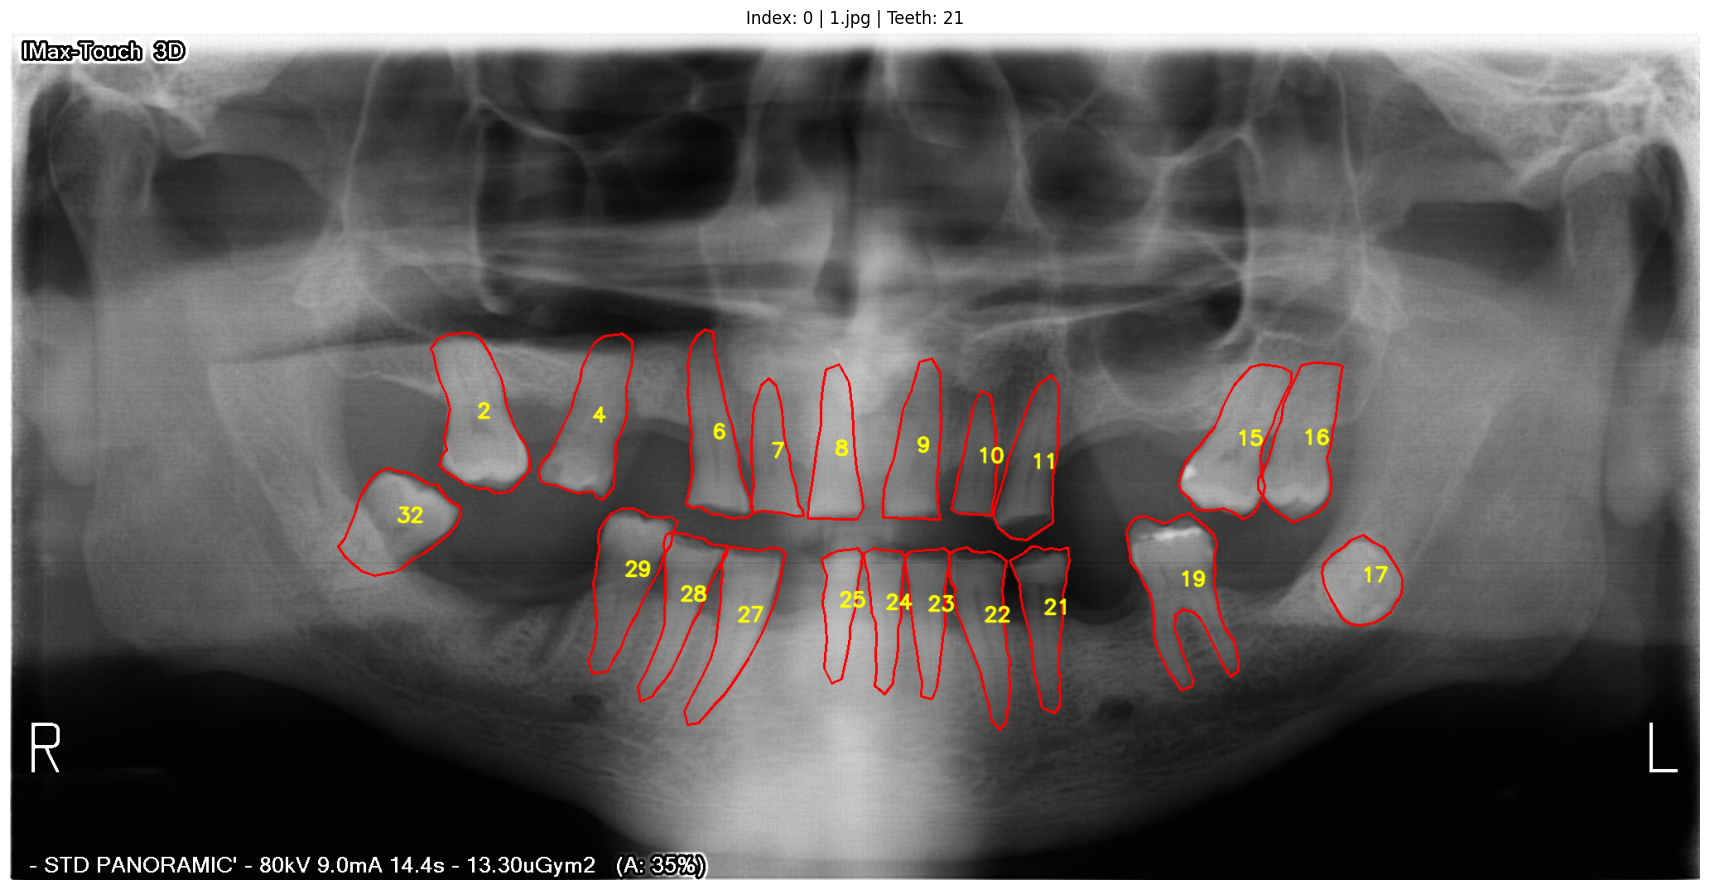

In [2]:
# ============================================================
# 5. Run
# ============================================================

visualize_segmentation(index=0)

In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.0+cu126
CUDA: 12.6
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [4]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm

In [5]:
# =========================================================
# Dataset Paths
# =========================================================

DATASET_DIR = Path(r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images")

IMAGE_DIR = DATASET_DIR / "Teeth Segmentation PNG"
ANNOTATION_DIR = DATASET_DIR / "Teeth Segmentation JSON"

# محل ذخیره نتایج EDA
EDA_DIR = DATASET_DIR / "EDA"

EDA_DIR.mkdir(parents=True, exist_ok=True)

print("Image directory:", IMAGE_DIR)
print("Annotation directory:", ANNOTATION_DIR)
print("EDA output directory:", EDA_DIR)

Image directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation PNG
Annotation directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON
EDA output directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\EDA


In [6]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}


def get_image_files(image_dir):
    
    image_files = [
        path for path in image_dir.rglob("*")
        if path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    
    image_files = sorted(image_files)
    
    return image_files

In [7]:
image_files = get_image_files(IMAGE_DIR)

print(f"Number of images: {len(image_files)}")

print("\nFirst 10 images:")
for path in image_files[:10]:
    print(path.name)

Number of images: 1794

First 10 images:
1.jpg
10.jpg
100.jpg
101.jpg
102.jpg
103.jpg
104.jpg
105.jpg
106.jpg
107.jpg


In [8]:
def find_annotation(image_path, annotation_dir):
    
    annotation_path = annotation_dir / f"{image_path.stem}.jpg.json"
    
    if annotation_path.exists():
        return annotation_path
    
     
    matches = list(annotation_dir.rglob(f"{image_path.stem}.jpg.json"))
    
    if len(matches) > 0:
        return matches[0]
    
    return None

In [9]:
def calculate_entropy(gray_image):
    
    histogram = cv2.calcHist(
        [gray_image],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()
    
    histogram = histogram / histogram.sum()
    
    histogram = histogram[histogram > 0]
    
    entropy = -np.sum(
        histogram * np.log2(histogram)
    )
    
    return float(entropy)

In [10]:
def calculate_annotation_coverage(
    annotation_path,
    image_height,
    image_width
):
    
    if annotation_path is None:
        return np.nan
    
    try:
        with open(
            annotation_path,
            "r",
            encoding="utf-8"
        ) as f:
            annotation = json.load(f)
            
    except Exception:
        return np.nan
    
    
    mask = np.zeros(
        (image_height, image_width),
        dtype=np.uint8
    )
    
    
    objects = annotation.get("objects", [])
    
    
    for obj in objects:
        
        if obj.get("geometryType") != "polygon":
            continue
        
        points = obj.get("points", {})
        exterior = points.get("exterior", [])
        
        if len(exterior) < 3:
            continue
        
        polygon = np.array(
            exterior,
            dtype=np.int32
        )
        
        cv2.fillPoly(
            mask,
            [polygon],
            1
        )
    
    
    mask_area = np.count_nonzero(mask)
    
    image_area = image_height * image_width
    
    coverage = mask_area / image_area
    
    return float(coverage)

In [11]:
def extract_image_statistics(
    image_files,
    annotation_dir
):
    
    records = []
    
    
    for image_path in tqdm(
        image_files,
        desc="Calculating image statistics"
    ):
        
        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )
        
        
        if image is None:
            print(
                f"Warning: Could not read {image_path}"
            )
            continue
        
        
        height, width = image.shape
        
        
        # -------------------------------------------------
        # 1. Width
        # -------------------------------------------------
        
        image_width = width
        
        
        # -------------------------------------------------
        # 2. Height
        # -------------------------------------------------
        
        image_height = height
        
        
        # -------------------------------------------------
        # 3. Aspect Ratio
        # -------------------------------------------------
        
        aspect_ratio = width / height
        
        
        # -------------------------------------------------
        # 4. Mean Intensity
        # -------------------------------------------------
        
        mean_intensity = float(
            np.mean(image)
        )
        
        
        # -------------------------------------------------
        # 5. Intensity Std
        # -------------------------------------------------
        
        intensity_std = float(
            np.std(image)
        )
        
        
        # -------------------------------------------------
        # 6. Minimum Intensity
        # -------------------------------------------------
        
        min_intensity = int(
            np.min(image)
        )
        
        
        # -------------------------------------------------
        # 7. Maximum Intensity
        # -------------------------------------------------
        
        max_intensity = int(
            np.max(image)
        )
        
        
        # -------------------------------------------------
        # 8. Dynamic Range
        # -------------------------------------------------
        
        dynamic_range = (
            max_intensity -
            min_intensity
        )
        
        
        # -------------------------------------------------
        # 9. Entropy
        # -------------------------------------------------
        
        entropy = calculate_entropy(image)
        
        
        # -------------------------------------------------
        # 10. Annotation Coverage
        # -------------------------------------------------
        
        annotation_path = find_annotation(
            image_path,
            annotation_dir
        )
        
        annotation_coverage = (
            calculate_annotation_coverage(
                annotation_path,
                height,
                width
            )
        )
        
        
        # -------------------------------------------------
        # Save record
        # -------------------------------------------------
        
        records.append({
            
            "Image": image_path.name,
            
            "Width": image_width,
            
            "Height": image_height,
            
            "Aspect_Ratio": aspect_ratio,
            
            "Mean_Intensity": mean_intensity,
            
            "Intensity_Std": intensity_std,
            
            "Min_Intensity": min_intensity,
            
            "Max_Intensity": max_intensity,
            
            "Dynamic_Range": dynamic_range,
            
            "Entropy": entropy,
            
            "Annotation_Coverage": annotation_coverage
        })
    
    
    return pd.DataFrame(records)

In [30]:
df = extract_image_statistics(
    image_files=image_files,
    annotation_dir=ANNOTATION_DIR
)

print("DataFrame shape:", df.shape)

df.head()

Calculating image statistics: 100%|████████████████████████████████████████████████| 1794/1794 [06:26<00:00,  4.65it/s]

DataFrame shape: (1794, 11)


,Image,Width,Height,Aspect_Ratio,Mean_Intensity,Intensity_Std,Min_Intensity,Max_Intensity,Dynamic_Range,Entropy,Annotation_Coverage
0,1.jpg,2041,1024,1.993164,85.409962,54.164808,1,255,254,7.116533,0.099884
1,10.jpg,2041,1024,1.993164,81.959400,50.682512,1,255,254,7.158739,0.108088
2,100.jpg,2041,1024,1.993164,82.954713,52.636624,1,255,254,7.182575,0.064075
3,101.jpg,2041,1024,1.993164,86.300996,55.447884,1,255,254,7.330974,0.077227
4,102.jpg,2041,1024,1.993164,85.557690,58.050369,1,255,254,7.056217,0.168135


In [45]:
numeric_columns = [
    "Width",
    "Height",
    "Aspect_Ratio",
    "Mean_Intensity",
    "Intensity_Std",
    "Min_Intensity",
    "Max_Intensity",
    "Dynamic_Range",
    "Entropy",
    "Annotation_Coverage"
]

In [46]:
summary_table = df[numeric_columns].describe().T

summary_table = summary_table[
    [
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

summary_table

,mean,std,min,25%,50%,75%,max
Width,2702.848384,959.328735,1394.000000,2041.000000,2041.000000,4083.000000,4091.000000
Height,1024.000000,0.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000
Aspect_Ratio,2.639500,0.936844,1.361328,1.993164,1.993164,3.987305,3.995117
Mean_Intensity,64.632297,33.971156,0.000000,23.388257,83.854314,86.728215,153.541692
Intensity_Std,53.721122,6.819359,0.000000,51.991870,54.512513,57.156040,80.773079
Min_Intensity,0.653289,0.703091,0.000000,0.000000,1.000000,1.000000,15.000000
Max_Intensity,252.983835,14.169174,0.000000,255.000000,255.000000,255.000000,255.000000
Dynamic_Range,252.330546,14.093406,0.000000,254.000000,254.000000,255.000000,255.000000
Entropy,5.220613,2.854932,-0.000000,1.485345,7.157507,7.278990,7.663051
Annotation_Coverage,0.120651,0.055014,0.000000,0.077773,0.114283,0.170100,0.261008


In [47]:
summary_table.to_csv(
    EDA_DIR / "numeric_eda_summary.csv",
    encoding="utf-8-sig"
)

df.to_csv(
    EDA_DIR / "image_level_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

In [48]:
missing_table = df.isnull().sum().to_frame(
    name="Missing_Count"
)

missing_table["Missing_Percentage"] = (
    missing_table["Missing_Count"]
    / len(df)
    * 100
)

missing_table

,Missing_Count,Missing_Percentage
Image,0,0.0
Width,0,0.0
Height,0,0.0
Aspect_Ratio,0,0.0
Mean_Intensity,0,0.0
Intensity_Std,0,0.0
Min_Intensity,0,0.0
Max_Intensity,0,0.0
Dynamic_Range,0,0.0
Entropy,0,0.0


In [49]:
def detect_outliers_iqr(dataframe, columns):
    
    results = []
    
    
    for column in columns:
        
        series = dataframe[column].dropna()
        
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = series[
            (series < lower_bound) |
            (series > upper_bound)
        ]
        
        
        results.append({
            
            "Metric": column,
            
            "Q1": Q1,
            
            "Q3": Q3,
            
            "IQR": IQR,
            
            "Lower_Bound": lower_bound,
            
            "Upper_Bound": upper_bound,
            
            "Outlier_Count": len(outliers),
            
            "Outlier_Percentage":
                len(outliers) / len(series) * 100
        })
    
    
    return pd.DataFrame(results)

In [50]:
outlier_table = detect_outliers_iqr(
    df,
    numeric_columns
)

outlier_table

,Metric,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Width,2041.000000,4083.000000,2042.000000,-1022.000000,7146.000000,0,0.000000
1,Height,1024.000000,1024.000000,0.000000,1024.000000,1024.000000,0,0.000000
2,Aspect_Ratio,1.993164,3.987305,1.994141,-0.998047,6.978516,0,0.000000
3,Mean_Intensity,23.388257,86.728215,63.339958,-71.621680,181.738153,0,0.000000
4,Intensity_Std,51.991870,57.156040,5.164170,44.245615,64.902294,159,8.862876
5,Min_Intensity,0.000000,1.000000,1.000000,-1.500000,2.500000,4,0.222965
6,Max_Intensity,255.000000,255.000000,0.000000,255.000000,255.000000,93,5.183946
7,Dynamic_Range,254.000000,255.000000,1.000000,252.500000,256.500000,97,5.406912
8,Entropy,1.485345,7.278990,5.793645,-7.205122,15.969457,0,0.000000
9,Annotation_Coverage,0.077773,0.170100,0.092327,-0.060718,0.308591,0,0.000000


In [51]:
outlier_table.to_csv(
    EDA_DIR / "outlier_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

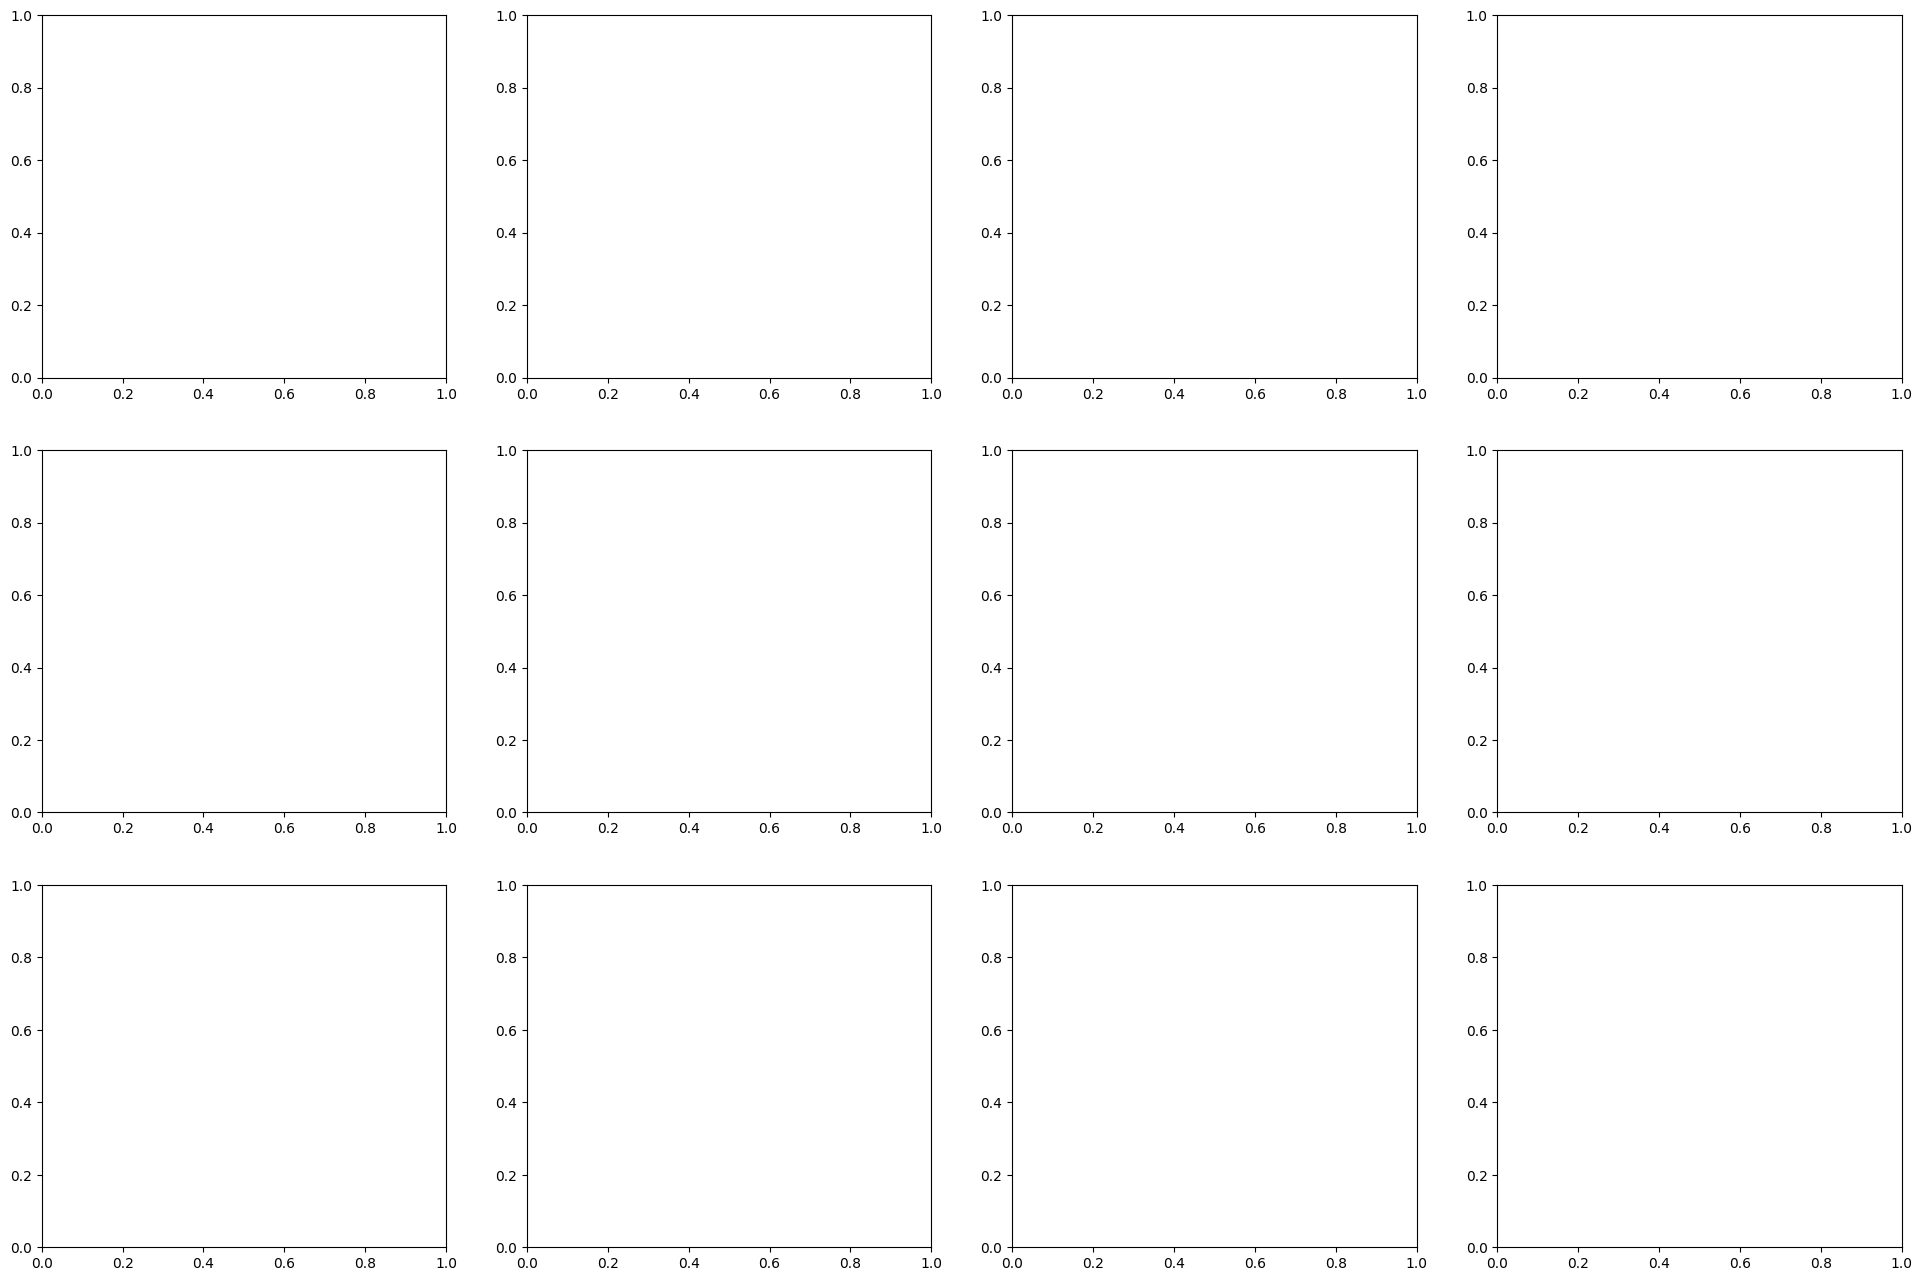

In [52]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(24, 16)
)

axes = axes.flatten()

In [53]:
axes[0].hist(
    df["Width"],
    bins=30
)

axes[0].set_title(
    "1. Width Distribution"
)

axes[0].set_xlabel(
    "Width (pixels)"
)

axes[0].set_ylabel(
    "Frequency"
)

axes[0].grid(
    alpha=0.3
)

In [54]:
axes[1].hist(
    df["Height"],
    bins=30
)

axes[1].set_title(
    "2. Height Distribution"
)

axes[1].set_xlabel(
    "Height (pixels)"
)

axes[1].set_ylabel(
    "Frequency"
)

axes[1].grid(
    alpha=0.3
)

In [55]:
axes[2].hist(
    df["Aspect_Ratio"],
    bins=30
)

axes[2].set_title(
    "3. Aspect Ratio Distribution"
)

axes[2].set_xlabel(
    "Width / Height"
)

axes[2].set_ylabel(
    "Frequency"
)

axes[2].grid(
    alpha=0.3
)

In [56]:
axes[3].hist(
    df["Mean_Intensity"],
    bins=30
)

axes[3].set_title(
    "4. Mean Intensity Distribution"
)

axes[3].set_xlabel(
    "Mean Intensity"
)

axes[3].set_ylabel(
    "Frequency"
)

axes[3].grid(
    alpha=0.3
)

In [57]:
axes[4].hist(
    df["Intensity_Std"],
    bins=30
)

axes[4].set_title(
    "5. Intensity Std Distribution"
)

axes[4].set_xlabel(
    "Intensity Std"
)

axes[4].set_ylabel(
    "Frequency"
)

axes[4].grid(
    alpha=0.3
)

In [58]:
axes[5].hist(
    df["Entropy"],
    bins=30
)

axes[5].set_title(
    "6. Entropy Distribution"
)

axes[5].set_xlabel(
    "Entropy"
)

axes[5].set_ylabel(
    "Frequency"
)

axes[5].grid(
    alpha=0.3
)

In [59]:
axes[6].scatter(
    df["Width"],
    df["Height"],
    alpha=0.6
)

axes[6].set_title(
    "7. Width vs Height"
)

axes[6].set_xlabel(
    "Width (pixels)"
)

axes[6].set_ylabel(
    "Height (pixels)"
)

axes[6].grid(
    alpha=0.3
)

In [60]:
axes[7].scatter(
    df["Aspect_Ratio"],
    df["Annotation_Coverage"],
    alpha=0.6
)

axes[7].set_title(
    "8. Aspect Ratio vs Coverage"
)

axes[7].set_xlabel(
    "Aspect Ratio"
)

axes[7].set_ylabel(
    "Annotation Coverage"
)

axes[7].grid(
    alpha=0.3
)

In [61]:
axes[8].scatter(
    df["Mean_Intensity"],
    df["Intensity_Std"],
    alpha=0.6
)

axes[8].set_title(
    "9. Mean Intensity vs Std"
)

axes[8].set_xlabel(
    "Mean Intensity"
)

axes[8].set_ylabel(
    "Intensity Std"
)

axes[8].grid(
    alpha=0.3
)

In [62]:
axes[9].hist(
    df["Annotation_Coverage"] * 100,
    bins=30
)

axes[9].set_title(
    "10. Annotation Coverage Distribution"
)

axes[9].set_xlabel(
    "Coverage (%)"
)

axes[9].set_ylabel(
    "Frequency"
)

axes[9].grid(
    alpha=0.3
)

In [63]:
fig.suptitle(
    "Dental OPG Image Preprocessing EDA",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

<Figure size 640x480 with 0 Axes>

In [64]:
plot_path = EDA_DIR / "preprocessing_eda_10_plots.png"

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [65]:
pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.4f}"
)

print("=" * 80)
print("NUMERICAL EDA SUMMARY")
print("=" * 80)

display(summary_table)

print("\n")
print("=" * 80)
print("MISSING VALUES")
print("=" * 80)

display(missing_table)

print("\n")
print("=" * 80)
print("OUTLIER ANALYSIS")
print("=" * 80)

display(outlier_table)

NUMERICAL EDA SUMMARY


,mean,std,min,25%,50%,75%,max
Width,2702.8484,959.3287,1394.0000,2041.0000,2041.0000,4083.0000,4091.0000
Height,1024.0000,0.0000,1024.0000,1024.0000,1024.0000,1024.0000,1024.0000
Aspect_Ratio,2.6395,0.9368,1.3613,1.9932,1.9932,3.9873,3.9951
Mean_Intensity,64.6323,33.9712,0.0000,23.3883,83.8543,86.7282,153.5417
Intensity_Std,53.7211,6.8194,0.0000,51.9919,54.5125,57.1560,80.7731
Min_Intensity,0.6533,0.7031,0.0000,0.0000,1.0000,1.0000,15.0000
Max_Intensity,252.9838,14.1692,0.0000,255.0000,255.0000,255.0000,255.0000
Dynamic_Range,252.3305,14.0934,0.0000,254.0000,254.0000,255.0000,255.0000
Entropy,5.2206,2.8549,-0.0000,1.4853,7.1575,7.2790,7.6631
Annotation_Coverage,0.1207,0.0550,0.0000,0.0778,0.1143,0.1701,0.2610




MISSING VALUES


,Missing_Count,Missing_Percentage
Image,0,0.0000
Width,0,0.0000
Height,0,0.0000
Aspect_Ratio,0,0.0000
Mean_Intensity,0,0.0000
Intensity_Std,0,0.0000
Min_Intensity,0,0.0000
Max_Intensity,0,0.0000
Dynamic_Range,0,0.0000
Entropy,0,0.0000




OUTLIER ANALYSIS


,Metric,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Width,2041.0000,4083.0000,2042.0000,-1022.0000,7146.0000,0,0.0000
1,Height,1024.0000,1024.0000,0.0000,1024.0000,1024.0000,0,0.0000
2,Aspect_Ratio,1.9932,3.9873,1.9941,-0.9980,6.9785,0,0.0000
3,Mean_Intensity,23.3883,86.7282,63.3400,-71.6217,181.7382,0,0.0000
4,Intensity_Std,51.9919,57.1560,5.1642,44.2456,64.9023,159,8.8629
5,Min_Intensity,0.0000,1.0000,1.0000,-1.5000,2.5000,4,0.2230
6,Max_Intensity,255.0000,255.0000,0.0000,255.0000,255.0000,93,5.1839
7,Dynamic_Range,254.0000,255.0000,1.0000,252.5000,256.5000,97,5.4069
8,Entropy,1.4853,7.2790,5.7936,-7.2051,15.9695,0,0.0000
9,Annotation_Coverage,0.0778,0.1701,0.0923,-0.0607,0.3086,0,0.0000


In [66]:
print(df.shape)
print(df[numeric_columns].dtypes)
print(df[numeric_columns].head())

(1794, 11)
Width                    int64
Height                   int64
Aspect_Ratio           float64
Mean_Intensity         float64
Intensity_Std          float64
Min_Intensity            int64
Max_Intensity            int64
Dynamic_Range            int64
Entropy                float64
Annotation_Coverage    float64
dtype: object
   Width  Height  Aspect_Ratio  Mean_Intensity  Intensity_Std  Min_Intensity  \
0   2041    1024        1.9932         85.4100        54.1648              1   
1   2041    1024        1.9932         81.9594        50.6825              1   
2   2041    1024        1.9932         82.9547        52.6366              1   
3   2041    1024        1.9932         86.3010        55.4479              1   
4   2041    1024        1.9932         85.5577        58.0504              1   

   Max_Intensity  Dynamic_Range  Entropy  Annotation_Coverage  
0            255            254   7.1165               0.0999  
1            255            254   7.1587               0

## Exploratory Data Analysis: Image and Annotation Distributions

This section presents a visual analysis of the numerical features extracted from the dental OPG dataset to better understand image characteristics and annotation properties before selecting the preprocessing strategy.

A collection of ten plots is generated to investigate the following aspects:

**Image Dimensions and Geometry**
- **Width Distribution:** Examines the distribution of image widths in pixels.
- **Height Distribution:** Examines the distribution of image heights in pixels.
- **Aspect Ratio Distribution:** Analyzes variations in image proportions.
- **Width vs. Height:** Visualizes the relationship between image dimensions.

**Image Intensity and Contrast**
- **Mean Intensity Distribution:** Examines the average pixel intensity across images.
- **Intensity Standard Deviation Distribution:** Evaluates variations in pixel intensity as an indicator of image contrast.
- **Entropy Distribution:** Provides an overview of image intensity complexity and information content.
- **Mean Intensity vs. Standard Deviation:** Investigates the relationship between average brightness and intensity variation.

**Annotation Characteristics**
- **Aspect Ratio vs. Annotation Coverage:** Explores the relationship between image proportions and the percentage of image area covered by annotations.
- **Annotation Coverage Distribution:** Examines how much of each image is occupied by annotated regions.

The resulting figure provides an overview of dataset variability and helps identify potential preprocessing considerations, including image resizing, aspect-ratio preservation, intensity normalization, contrast enhancement, and annotation-aware transformations.

The plots are saved as a high-resolution image for subsequent inspection and reporting.

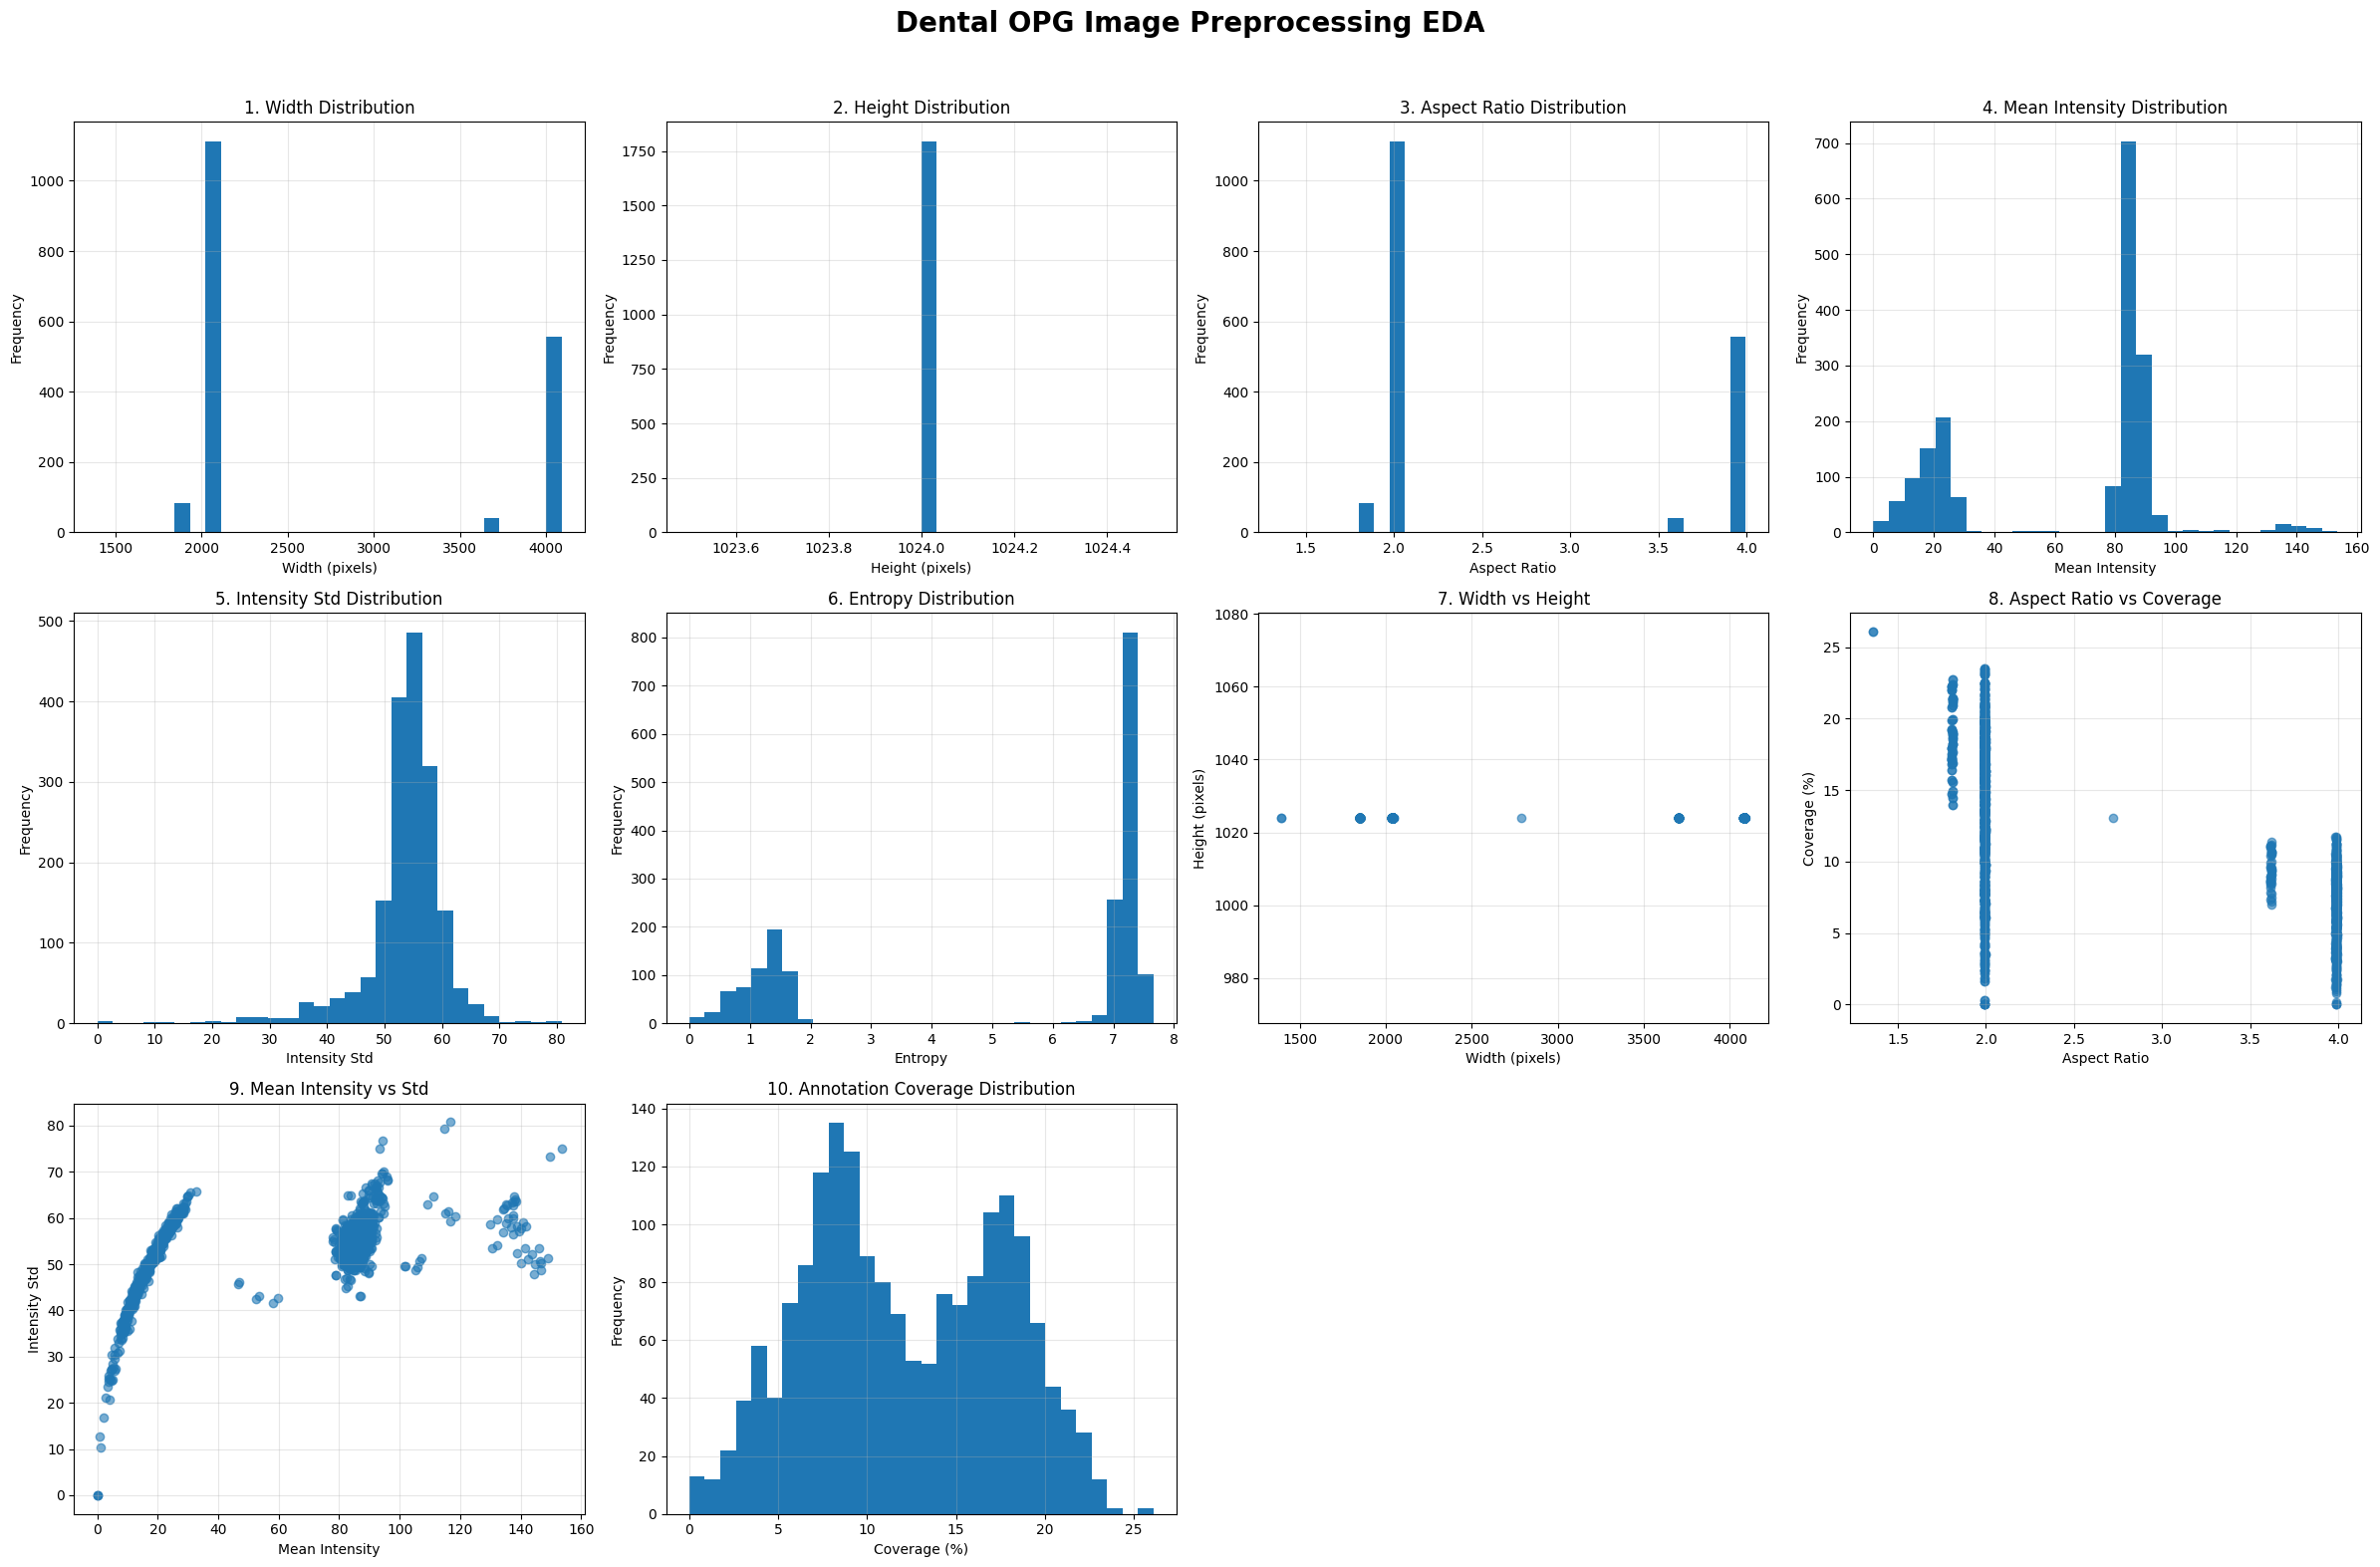

In [67]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(24, 16)
)

# تبدیل به آرایه یک‌بعدی
axes = axes.ravel()


# =========================================================
# 1. Width Distribution
# =========================================================

axes[0].hist(
    df["Width"].dropna(),
    bins=30
)

axes[0].set_title("1. Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Frequency")
axes[0].grid(alpha=0.3)


# =========================================================
# 2. Height Distribution
# =========================================================

axes[1].hist(
    df["Height"].dropna(),
    bins=30
)

axes[1].set_title("2. Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.3)


# =========================================================
# 3. Aspect Ratio Distribution
# =========================================================

axes[2].hist(
    df["Aspect_Ratio"].dropna(),
    bins=30
)

axes[2].set_title("3. Aspect Ratio Distribution")
axes[2].set_xlabel("Aspect Ratio")
axes[2].set_ylabel("Frequency")
axes[2].grid(alpha=0.3)


# =========================================================
# 4. Mean Intensity Distribution
# =========================================================

axes[3].hist(
    df["Mean_Intensity"].dropna(),
    bins=30
)

axes[3].set_title("4. Mean Intensity Distribution")
axes[3].set_xlabel("Mean Intensity")
axes[3].set_ylabel("Frequency")
axes[3].grid(alpha=0.3)


# =========================================================
# 5. Intensity Std Distribution
# =========================================================

axes[4].hist(
    df["Intensity_Std"].dropna(),
    bins=30
)

axes[4].set_title("5. Intensity Std Distribution")
axes[4].set_xlabel("Intensity Std")
axes[4].set_ylabel("Frequency")
axes[4].grid(alpha=0.3)


# =========================================================
# 6. Entropy Distribution
# =========================================================

axes[5].hist(
    df["Entropy"].dropna(),
    bins=30
)

axes[5].set_title("6. Entropy Distribution")
axes[5].set_xlabel("Entropy")
axes[5].set_ylabel("Frequency")
axes[5].grid(alpha=0.3)


# =========================================================
# 7. Width vs Height
# =========================================================

valid = df[
    ["Width", "Height"]
].dropna()

axes[6].scatter(
    valid["Width"],
    valid["Height"],
    alpha=0.6
)

axes[6].set_title("7. Width vs Height")
axes[6].set_xlabel("Width (pixels)")
axes[6].set_ylabel("Height (pixels)")
axes[6].grid(alpha=0.3)


# =========================================================
# 8. Aspect Ratio vs Coverage
# =========================================================

valid = df[
    ["Aspect_Ratio", "Annotation_Coverage"]
].dropna()

axes[7].scatter(
    valid["Aspect_Ratio"],
    valid["Annotation_Coverage"] * 100,
    alpha=0.6
)

axes[7].set_title("8. Aspect Ratio vs Coverage")
axes[7].set_xlabel("Aspect Ratio")
axes[7].set_ylabel("Coverage (%)")
axes[7].grid(alpha=0.3)


# =========================================================
# 9. Mean Intensity vs Std
# =========================================================

valid = df[
    ["Mean_Intensity", "Intensity_Std"]
].dropna()

axes[8].scatter(
    valid["Mean_Intensity"],
    valid["Intensity_Std"],
    alpha=0.6
)

axes[8].set_title("9. Mean Intensity vs Std")
axes[8].set_xlabel("Mean Intensity")
axes[8].set_ylabel("Intensity Std")
axes[8].grid(alpha=0.3)


# =========================================================
# 10. Annotation Coverage Distribution
# =========================================================

axes[9].hist(
    df["Annotation_Coverage"].dropna() * 100,
    bins=30
)

axes[9].set_title(
    "10. Annotation Coverage Distribution"
)

axes[9].set_xlabel("Coverage (%)")
axes[9].set_ylabel("Frequency")
axes[9].grid(alpha=0.3)


# =========================================================
# Remove unused axes
# =========================================================

axes[10].remove()
axes[11].remove()


# =========================================================
# Final layout
# =========================================================

fig.suptitle(
    "Dental OPG Image Preprocessing EDA",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


# Save
plt.savefig(
    EDA_DIR / "preprocessing_eda_10_plots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Annotation and Segmentation Exploratory Data Analysis

This section performs a comprehensive analysis of the polygon-based segmentation annotations and their spatial characteristics across the dental OPG dataset.

The analysis is conducted at two levels: **image-level** and **instance-level**, allowing both dataset-wide properties and individual tooth annotations to be investigated.

### 1. Image-Level Analysis

For each image, the following properties are extracted:

- **Image Dimensions:** Original image width and height.
- **Tooth Count:** Number of valid polygon annotations per image.
- **Annotation Area:** Total area covered by the annotated polygons.
- **Annotation Coverage:** Ratio of the total annotated area to the entire image area.

### 2. Instance-Level Analysis

Each valid tooth polygon is analyzed independently to extract:

- **Class Information:** Numerical class identifier and original class title.
- **Polygon Geometry:** Polygon area, perimeter, and number of vertices.
- **Bounding Box Properties:** Bounding box coordinates, width, height, and area.
- **Geometric Ratios:** Polygon-to-bounding-box area ratio and polygon-to-image area ratio.
- **Spatial Information:** Polygon centroid coordinates and normalized centroid positions.
- **Normalized Bounding Box Dimensions:** Bounding box width and height relative to the original image dimensions.

### 3. Statistical Analysis

Descriptive statistical summaries are generated separately for image-level and instance-level features. The class distribution is also calculated to examine the frequency of individual tooth classes and identify potential class imbalance.

### 4. Visualization

Ten plots are generated to investigate the distribution and relationships of the extracted features:

1. Number of Teeth per Image
2. Tooth Class Distribution
3. Polygon Area Distribution
4. Tooth Area Relative to Image Area
5. Polygon Perimeter Distribution
6. Polygon Point Count
7. Bounding Box Width vs. Height
8. Polygon Area vs. Bounding Box Area
9. Tooth Centroid Distribution
10. Annotation Coverage Distribution

These visualizations help characterize annotation geometry, spatial distribution, object-size variability, and class representation.

### 5. Exporting EDA Results

The extracted image-level and instance-level records, statistical summaries, and class distribution are exported as CSV files. The complete visualization is also saved as a high-resolution PNG image.

The resulting analysis provides quantitative evidence for subsequent decisions regarding segmentation preprocessing, image resizing, polygon coordinate transformations, class handling, and model design.

**Note:** This stage is strictly an annotation and dataset analysis procedure. It does not modify the original images or annotations and does not perform model training.

DATASET INFORMATION
Number of images: 1794


Processing annotations: 100%|██████████████████████████████████████████████████████| 1794/1794 [04:21<00:00,  6.85it/s]




ANNOTATION EDA INFORMATION
Images with valid annotations: 1794
Total segmentation instances: 45954
Missing annotations: 0


IMAGE LEVEL STATISTICS


,count,mean,std,min,25%,50%,75%,max
Tooth_Count,1794.0000,25.6154,7.4753,0.0000,21.0000,28.0000,31.0000,44.0000
Annotation_Area,1794.0000,297623.8253,101829.3873,0.0000,235135.5000,320394.0000,373192.0000,489150.5000
Annotation_Coverage,1794.0000,0.1198,0.0549,0.0000,0.0766,0.1131,0.1689,0.2613




INSTANCE LEVEL STATISTICS


,count,mean,std,min,25%,50%,75%,max
Polygon_Area,45954.0000,11618.9481,3835.3569,0.0000,8879.0000,11356.2500,14139.5000,28701.5000
Area_Image_Ratio,45954.0000,0.0047,0.0021,0.0000,0.0030,0.0044,0.0061,0.0137
Perimeter,45954.0000,510.5244,107.0231,0.0000,448.3303,504.0487,558.5838,1367.8553
Point_Count,45954.0000,15.9043,6.3164,3.0000,12.0000,15.0000,18.0000,65.0000
BBox_Width,45954.0000,99.2857,36.6467,1.0000,74.0000,90.0000,115.0000,444.0000
BBox_Height,45954.0000,199.8028,39.5272,1.0000,178.0000,202.0000,225.0000,490.0000
BBox_Area,45954.0000,19816.8072,8153.5453,1.0000,14416.0000,18752.5000,23754.0000,186036.0000
Area_BBox_Ratio,45954.0000,0.6077,0.1014,0.0000,0.5410,0.6183,0.6804,0.9071




CLASS DISTRIBUTION


,Instance_Count
1,996
2,1461
3,1344
4,1344
5,1356
6,1605
7,1524
8,1554
9,1557
10,1533


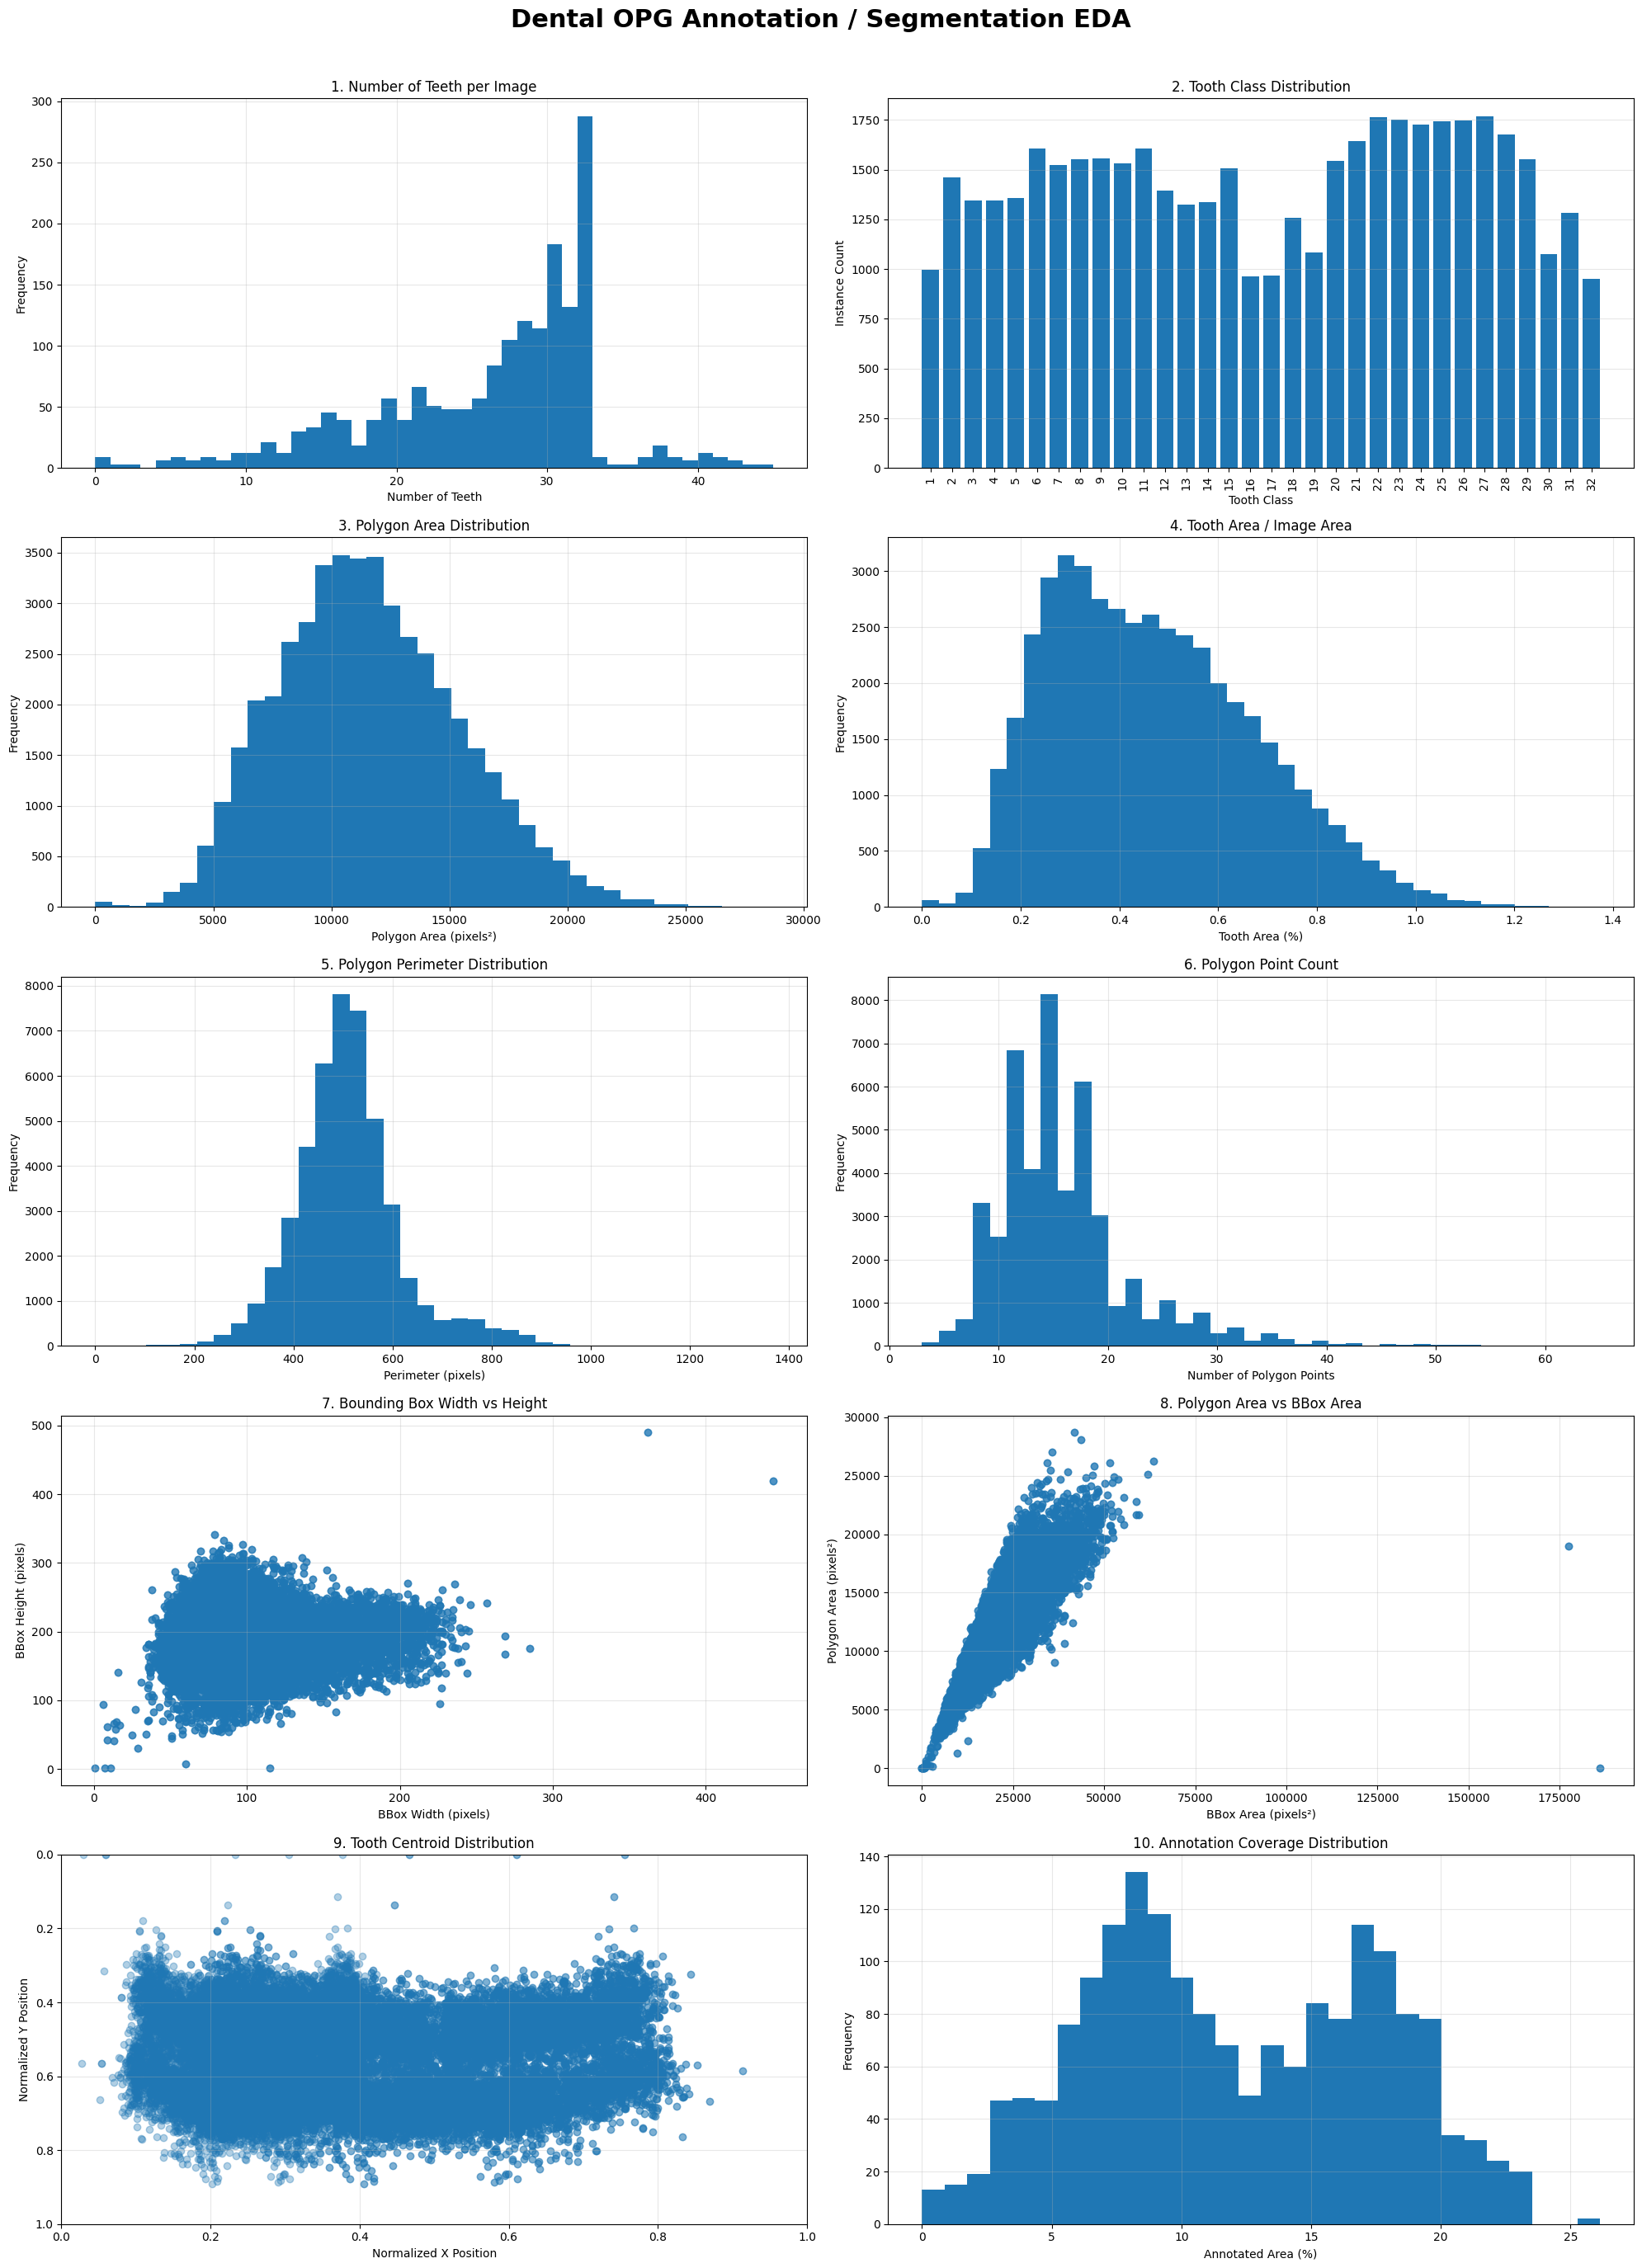



EDA COMPLETED
Image-level CSV: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\EDA\annotation_image_level_eda.csv
Instance-level CSV: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\EDA\annotation_instance_level_eda.csv
Class distribution: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\EDA\class_distribution.csv
10 plots: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\EDA\annotation_eda_10_plots.png


In [68]:
# ============================================================
# DENTAL OPG - ANNOTATION / SEGMENTATION EDA
# ============================================================

import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm

 
# ============================================================
# 2. FIND IMAGES
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}


image_files = sorted([
    p for p in IMAGE_DIR.rglob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
])


print("=" * 80)
print("DATASET INFORMATION")
print("=" * 80)

print(f"Number of images: {len(image_files)}")


# ============================================================
# 3. FIND JSON
# ============================================================

def find_annotation(image_path):
    
    json_path = ANNOTATION_DIR / f"{image_path.stem}.jpg.json"
    
    if json_path.exists():
        return json_path
    
    matches = list(
        ANNOTATION_DIR.rglob(
            f"{image_path.stem}.jpg.json"
        )
    )
    
    if len(matches) > 0:
        return matches[0]
    
    return None


# ============================================================
# 4. DATA CONTAINERS
# ============================================================

image_records = []
instance_records = []

missing_annotations = []


# ============================================================
# 5. MAIN EDA LOOP
# ============================================================

for image_path in tqdm(
    image_files,
    desc="Processing annotations"
):
    
    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------
    
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )
    
    if image is None:
        continue
    
    image_height, image_width = image.shape
    
    image_area = image_width * image_height
    
    
    # --------------------------------------------------------
    # Find annotation
    # --------------------------------------------------------
    
    annotation_path = find_annotation(
        image_path
    )
    
    
    if annotation_path is None:
        
        missing_annotations.append(
            image_path.name
        )
        
        continue
    
    
    # --------------------------------------------------------
    # Read JSON
    # --------------------------------------------------------
    
    try:
        
        with open(
            annotation_path,
            "r",
            encoding="utf-8"
        ) as f:
            
            annotation = json.load(f)
            
    except Exception as e:
        
        print(
            f"Error reading {annotation_path.name}: {e}"
        )
        
        continue
    
    
    objects = annotation.get(
        "objects",
        []
    )
    
    
    # ========================================================
    # IMAGE LEVEL VARIABLES
    # ========================================================
    
    tooth_count = 0
    
    total_annotation_area = 0
    
    image_instance_data = []
    
    
    # ========================================================
    # PROCESS EACH OBJECT
    # ========================================================
    
    for obj in objects:
        
        if obj.get("geometryType") != "polygon":
            continue
        
        
        points_data = obj.get(
            "points",
            {}
        )
        
        exterior = points_data.get(
            "exterior",
            []
        )
        
        
        if len(exterior) < 3:
            continue
        
        
        polygon = np.array(
            exterior,
            dtype=np.float32
        )
        
        
        # ----------------------------------------------------
        # Class
        # ----------------------------------------------------
        
        class_title = obj.get(
            "classTitle",
            "Unknown"
        )
        
        
        try:
            class_id = int(class_title)
        except:
            class_id = -1
        
        
        # ----------------------------------------------------
        # Polygon Area
        # ----------------------------------------------------
        
        polygon_int = polygon.astype(
            np.int32
        )
        
        polygon_area = cv2.contourArea(
            polygon_int
        )
        
        
        # ----------------------------------------------------
        # Polygon Perimeter
        # ----------------------------------------------------
        
        perimeter = cv2.arcLength(
            polygon_int,
            True
        )
        
        
        # ----------------------------------------------------
        # Bounding Box
        # ----------------------------------------------------
        
        x, y, w, h = cv2.boundingRect(
            polygon_int
        )
        
        
        bbox_area = w * h
        
        
        # ----------------------------------------------------
        # Area / Bounding Box Ratio
        # ----------------------------------------------------
        
        if bbox_area > 0:
            area_bbox_ratio = (
                polygon_area / bbox_area
            )
        else:
            area_bbox_ratio = 0
        
        
        # ----------------------------------------------------
        # Area / Image Ratio
        # ----------------------------------------------------
        
        area_image_ratio = (
            polygon_area / image_area
        )
        
        
        # ----------------------------------------------------
        # Polygon Centroid
        # ----------------------------------------------------
        
        moments = cv2.moments(
            polygon_int
        )
        
        if moments["m00"] != 0:
            
            cx = (
                moments["m10"]
                / moments["m00"]
            )
            
            cy = (
                moments["m01"]
                / moments["m00"]
            )
            
        else:
            
            cx = np.mean(
                polygon[:, 0]
            )
            
            cy = np.mean(
                polygon[:, 1]
            )
        
        
        # ----------------------------------------------------
        # Normalized centroid
        # ----------------------------------------------------
        
        cx_normalized = cx / image_width
        cy_normalized = cy / image_height
        
        
        # ----------------------------------------------------
        # Normalized bbox
        # ----------------------------------------------------
        
        bbox_width_ratio = w / image_width
        bbox_height_ratio = h / image_height
        
        
        # ----------------------------------------------------
        # Number of polygon points
        # ----------------------------------------------------
        
        point_count = len(exterior)
        
        
        # ----------------------------------------------------
        # Save instance record
        # ----------------------------------------------------
        
        instance_records.append({
            
            "Image": image_path.name,
            
            "Class": class_id,
            
            "Class_Title": str(class_title),
            
            "Polygon_Area": polygon_area,
            
            "Area_Image_Ratio": area_image_ratio,
            
            "Perimeter": perimeter,
            
            "Point_Count": point_count,
            
            "BBox_X": x,
            
            "BBox_Y": y,
            
            "BBox_Width": w,
            
            "BBox_Height": h,
            
            "BBox_Area": bbox_area,
            
            "Area_BBox_Ratio": area_bbox_ratio,
            
            "Centroid_X": cx,
            
            "Centroid_Y": cy,
            
            "Centroid_X_Normalized": cx_normalized,
            
            "Centroid_Y_Normalized": cy_normalized,
            
            "BBox_Width_Ratio": bbox_width_ratio,
            
            "BBox_Height_Ratio": bbox_height_ratio
        })
        
        
        # ----------------------------------------------------
        # Update image-level values
        # ----------------------------------------------------
        
        tooth_count += 1
        
        total_annotation_area += polygon_area
        
    
    # ========================================================
    # IMAGE LEVEL RECORD
    # ========================================================
    
    annotation_coverage = (
        total_annotation_area
        / image_area
    )
    
    
    image_records.append({
        
        "Image": image_path.name,
        
        "Width": image_width,
        
        "Height": image_height,
        
        "Tooth_Count": tooth_count,
        
        "Annotation_Area": total_annotation_area,
        
        "Annotation_Coverage":
            annotation_coverage
    })


# ============================================================
# 6. CREATE DATAFRAMES
# ============================================================

image_df = pd.DataFrame(
    image_records
)

instance_df = pd.DataFrame(
    instance_records
)


# ============================================================
# 7. BASIC INFORMATION
# ============================================================

print("\n")
print("=" * 80)
print("ANNOTATION EDA INFORMATION")
print("=" * 80)

print(
    f"Images with valid annotations: "
    f"{len(image_df)}"
)

print(
    f"Total segmentation instances: "
    f"{len(instance_df)}"
)

print(
    f"Missing annotations: "
    f"{len(missing_annotations)}"
)


# ============================================================
# 8. NUMERICAL SUMMARY - IMAGE LEVEL
# ============================================================

image_numeric_columns = [
    "Tooth_Count",
    "Annotation_Area",
    "Annotation_Coverage"
]


print("\n")
print("=" * 80)
print("IMAGE LEVEL STATISTICS")
print("=" * 80)

image_summary = (
    image_df[
        image_numeric_columns
    ]
    .describe()
    .T
)

display(image_summary)


# ============================================================
# 9. NUMERICAL SUMMARY - INSTANCE LEVEL
# ============================================================

instance_numeric_columns = [
    "Polygon_Area",
    "Area_Image_Ratio",
    "Perimeter",
    "Point_Count",
    "BBox_Width",
    "BBox_Height",
    "BBox_Area",
    "Area_BBox_Ratio"
]


print("\n")
print("=" * 80)
print("INSTANCE LEVEL STATISTICS")
print("=" * 80)

instance_summary = (
    instance_df[
        instance_numeric_columns
    ]
    .describe()
    .T
)

display(instance_summary)


# ============================================================
# 10. CLASS DISTRIBUTION
# ============================================================

class_distribution = (
    instance_df[
        "Class"
    ]
    .value_counts()
    .sort_index()
)


print("\n")
print("=" * 80)
print("CLASS DISTRIBUTION")
print("=" * 80)

display(
    class_distribution.to_frame(
        name="Instance_Count"
    )
)


# ============================================================
# 11. SAVE TABLES
# ============================================================

image_df.to_csv(
    EDA_DIR / "annotation_image_level_eda.csv",
    index=False,
    encoding="utf-8-sig"
)

instance_df.to_csv(
    EDA_DIR / "annotation_instance_level_eda.csv",
    index=False,
    encoding="utf-8-sig"
)

image_summary.to_csv(
    EDA_DIR / "annotation_image_summary.csv",
    encoding="utf-8-sig"
)

instance_summary.to_csv(
    EDA_DIR / "annotation_instance_summary.csv",
    encoding="utf-8-sig"
)

class_distribution.to_csv(
    EDA_DIR / "class_distribution.csv"
)


# ============================================================
# 12. CREATE 10-PLOT FIGURE
# ============================================================

fig, axes = plt.subplots(
    5,
    2,
    figsize=(20, 28)
)

axes = axes.ravel()


# ============================================================
# PLOT 1
# Number of Teeth per Image
# ============================================================

axes[0].hist(
    image_df["Tooth_Count"],
    bins=range(
        int(image_df["Tooth_Count"].min()),
        int(image_df["Tooth_Count"].max()) + 2
    )
)

axes[0].set_title(
    "1. Number of Teeth per Image"
)

axes[0].set_xlabel(
    "Number of Teeth"
)

axes[0].set_ylabel(
    "Frequency"
)

axes[0].grid(
    alpha=0.3
)


# ============================================================
# PLOT 2
# Class Distribution
# ============================================================

axes[1].bar(
    class_distribution.index.astype(str),
    class_distribution.values
)

axes[1].set_title(
    "2. Tooth Class Distribution"
)

axes[1].set_xlabel(
    "Tooth Class"
)

axes[1].set_ylabel(
    "Instance Count"
)

axes[1].tick_params(
    axis="x",
    rotation=90
)

axes[1].grid(
    axis="y",
    alpha=0.3
)


# ============================================================
# PLOT 3
# Polygon Area Distribution
# ============================================================

axes[2].hist(
    instance_df["Polygon_Area"],
    bins=40
)

axes[2].set_title(
    "3. Polygon Area Distribution"
)

axes[2].set_xlabel(
    "Polygon Area (pixels²)"
)

axes[2].set_ylabel(
    "Frequency"
)

axes[2].grid(
    alpha=0.3
)


# ============================================================
# PLOT 4
# Area / Image Ratio
# ============================================================

axes[3].hist(
    instance_df["Area_Image_Ratio"] * 100,
    bins=40
)

axes[3].set_title(
    "4. Tooth Area / Image Area"
)

axes[3].set_xlabel(
    "Tooth Area (%)"
)

axes[3].set_ylabel(
    "Frequency"
)

axes[3].grid(
    alpha=0.3
)


# ============================================================
# PLOT 5
# Polygon Perimeter Distribution
# ============================================================

axes[4].hist(
    instance_df["Perimeter"],
    bins=40
)

axes[4].set_title(
    "5. Polygon Perimeter Distribution"
)

axes[4].set_xlabel(
    "Perimeter (pixels)"
)

axes[4].set_ylabel(
    "Frequency"
)

axes[4].grid(
    alpha=0.3
)


# ============================================================
# PLOT 6
# Polygon Point Count
# ============================================================

axes[5].hist(
    instance_df["Point_Count"],
    bins=40
)

axes[5].set_title(
    "6. Polygon Point Count"
)

axes[5].set_xlabel(
    "Number of Polygon Points"
)

axes[5].set_ylabel(
    "Frequency"
)

axes[5].grid(
    alpha=0.3
)


# ============================================================
# PLOT 7
# Bounding Box Width vs Height
# ============================================================

axes[6].scatter(
    instance_df["BBox_Width"],
    instance_df["BBox_Height"],
    alpha=0.4
)

axes[6].set_title(
    "7. Bounding Box Width vs Height"
)

axes[6].set_xlabel(
    "BBox Width (pixels)"
)

axes[6].set_ylabel(
    "BBox Height (pixels)"
)

axes[6].grid(
    alpha=0.3
)


# ============================================================
# PLOT 8
# Polygon Area vs BBox Area
# ============================================================

axes[7].scatter(
    instance_df["BBox_Area"],
    instance_df["Polygon_Area"],
    alpha=0.4
)

axes[7].set_title(
    "8. Polygon Area vs BBox Area"
)

axes[7].set_xlabel(
    "BBox Area (pixels²)"
)

axes[7].set_ylabel(
    "Polygon Area (pixels²)"
)

axes[7].grid(
    alpha=0.3
)


# ============================================================
# PLOT 9
# Tooth Center Distribution
# ============================================================

axes[8].scatter(
    instance_df[
        "Centroid_X_Normalized"
    ],
    
    instance_df[
        "Centroid_Y_Normalized"
    ],
    
    alpha=0.35
)

axes[8].set_title(
    "9. Tooth Centroid Distribution"
)

axes[8].set_xlabel(
    "Normalized X Position"
)

axes[8].set_ylabel(
    "Normalized Y Position"
)

axes[8].set_xlim(
    0,
    1
)

axes[8].set_ylim(
    1,
    0
)

axes[8].grid(
    alpha=0.3
)


# ============================================================
# PLOT 10
# Annotation Coverage Distribution
# ============================================================

axes[9].hist(
    image_df["Annotation_Coverage"] * 100,
    bins=30
)

axes[9].set_title(
    "10. Annotation Coverage Distribution"
)

axes[9].set_xlabel(
    "Annotated Area (%)"
)

axes[9].set_ylabel(
    "Frequency"
)

axes[9].grid(
    alpha=0.3
)


# ============================================================
# 13. FINAL FIGURE
# ============================================================

fig.suptitle(
    "Dental OPG Annotation / Segmentation EDA",
    fontsize=22,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


# ============================================================
# 14. SAVE ONE IMAGE
# ============================================================

annotation_plot_path = (
    EDA_DIR /
    "annotation_eda_10_plots.png"
)

plt.savefig(
    annotation_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 80)
print("EDA COMPLETED")
print("=" * 80)

print(
    f"Image-level CSV: "
    f"{EDA_DIR / 'annotation_image_level_eda.csv'}"
)

print(
    f"Instance-level CSV: "
    f"{EDA_DIR / 'annotation_instance_level_eda.csv'}"
)

print(
    f"Class distribution: "
    f"{EDA_DIR / 'class_distribution.csv'}"
)

print(
    f"10 plots: "
    f"{annotation_plot_path}"
)

In [26]:
    # ============================================================
    # DENTAL OPG PREPROCESSING PIPELINE (ROBUST VERSION)
    # CLAHE + RESIZE + SUPERVISELY POLYGON TRANSFORMATION + QC
    # ============================================================
    
    from pathlib import Path
    import json
    import cv2
    import numpy as np
    import pandas as pd
    
    
    # ============================================================
    # 1. PATH CONFIGURATION
    # ============================================================
    
    DATASET_DIR = Path(r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2")
    IMAGE_DIR = DATASET_DIR / "img"
    ANNOTATION_DIR = DATASET_DIR / "ann"
    
    OUTPUT_DIR = DATASET_DIR / "Preprocessed" / "Baseline_CLAHE_256x256"
    OUTPUT_IMAGE_DIR = OUTPUT_DIR / "images"
    OUTPUT_ANNOTATION_DIR = OUTPUT_DIR / "annotations"
    OUTPUT_QC_DIR = OUTPUT_DIR / "qc"
    
     
    OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUT_ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUT_QC_DIR.mkdir(parents=True, exist_ok=True)
    
    
    # ============================================================
    # 2. PARAMETERS CONFIGURATION
    # ============================================================
    
    TARGET_W = 256
    TARGET_H = 256
    
    CLAHE_CLIP_LIMIT = 2.0
    CLAHE_TILE_GRID_SIZE = (8, 8)
    
    SAVE_QC_IMAGES = True
    MAX_QC_IMAGES = 20
    
    
    # ============================================================
    # 3. SCANNING IMAGE FILES (ROBUST)
    # ============================================================
    
    IMAGE_EXTENSIONS = {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
    }
    
    image_paths = sorted([
        p for p in IMAGE_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])
    
    print(f"[INFO] Image directory: {IMAGE_DIR.resolve()}")
    print(f"[INFO] Annotation directory: {ANNOTATION_DIR.resolve()}")
    print(f"[INFO] Total images found: {len(image_paths)}")
    
    if len(image_paths) == 0:
        print("[ERROR]  no file found.")
    
    
    # ============================================================
    # 4. INITIALIZE CLAHE
    # ============================================================
    
    clahe = cv2.createCLAHE(
        clipLimit=CLAHE_CLIP_LIMIT,
        tileGridSize=CLAHE_TILE_GRID_SIZE
    )
    
    
    # ============================================================
    # 5. HELPER FUNCTIONS
    # ============================================================
    
    def robust_read_image(path: Path):
         try:
            with open(path, "rb") as f:
                bytes_data = bytearray(f.read())
                numpy_array = np.asarray(bytes_data, dtype=np.uint8)
                return cv2.imdecode(numpy_array, cv2.IMREAD_GRAYSCALE)
        except Exception:
            return None
    
    
    def robust_save_image(path: Path, img):
         try:
            ext = path.suffix if path.suffix else ".jpg"
            is_success, buffer = cv2.imencode(ext, img)
            if is_success:
                with open(path, "wb") as f:
                    f.write(buffer)
                return True
            return False
        except Exception:
            return False
    
    
    def transform_point(point, scale_x, scale_y):
        x, y = point
        new_x = int(round(x * scale_x))
        new_y = int(round(y * scale_y))
        return new_x, new_y
    
    
    def transform_ring(ring, scale_x, scale_y):
        transformed_ring = []
        for point in ring:
            if not isinstance(point, (list, tuple)) or len(point) != 2:
                continue
            new_x, new_y = transform_point(point, scale_x, scale_y)
            new_x = np.clip(new_x, 0, TARGET_W - 1)
            new_y = np.clip(new_y, 0, TARGET_H - 1)
            transformed_ring.append([int(new_x), int(new_y)])
        return transformed_ring
    
    
    def polygon_is_valid(ring):
        if len(ring) < 3:
            return False
        points = np.array(ring, dtype=np.int32)
        unique_points = np.unique(points, axis=0)
        if len(unique_points) < 3:
            return False
        area = cv2.contourArea(points)
        return area > 0
    
    
    def draw_annotation(image, objects):
        canvas = cv2.cvtColor(image.copy(), cv2.COLOR_GRAY2BGR)
        for obj in objects:
            if obj.get("geometryType") != "polygon":
                continue
            points_data = obj.get("points", {})
            exterior = points_data.get("exterior", [])
            if not polygon_is_valid(exterior):
                continue
    
            polygon = np.array(exterior, dtype=np.int32)
            cv2.polylines(canvas, [polygon], isClosed=True, color=(0, 255, 0), thickness=1)
    
            M = cv2.moments(polygon)
            if M["m00"] != 0:
                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])
                class_title = str(obj.get("classTitle", "?"))
                cv2.putText(
                    canvas, class_title, (cx, cy),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 0, 255), 1, cv2.LINE_AA
                )
        return canvas
    
    
    def find_matching_json(annotation_dir: Path, img_path: Path):
        
        candidates = [
            annotation_dir / f"{img_path.name}.json",
            annotation_dir / f"{img_path.stem}.json",
            annotation_dir / img_path.name
        ]
        for cand in candidates:
            if cand.exists():
                return cand
        return None
    
    
    # ============================================================
    # 6. QC METRICS
    # ============================================================
    
    report_records = []
    total_images = 0
    successful_images = 0
    total_original_objects = 0
    total_saved_objects = 0
    total_invalid_polygons = 0
    total_clipped_points = 0
    
    
    # ============================================================
    # 7. MAIN LOOP
    # ============================================================
    
    for image_path in image_paths:
        total_images += 1
        print(f"[{total_images}/{len(image_paths)}] Processing: {image_path.name}")
    
        clean_image_name = image_path.name
    
        # 7.1 finding  JSON
        json_path = find_matching_json(ANNOTATION_DIR, image_path)
        if json_path is None:
            print(f"  [WARNING] Annotation not found for: {image_path.name}")
            report_records.append({
                "Image": clean_image_name,
                "JSON": "NOT_FOUND",
                "Status": "Missing Annotation"
            })
            continue
    
        # 7.2 reading json
        image = robust_read_image(image_path)
        if image is None:
            print(f"  [ERROR] Could not read image: {image_path.name}")
            report_records.append({
                "Image": clean_image_name,
                "JSON": json_path.name,
                "Status": "Image Read Error"
            })
            continue
    
        original_h, original_w = image.shape
    
        # 7.3 reading JSON
        try:
            with open(json_path, "r", encoding="utf-8") as f:
                annotation = json.load(f)
        except Exception as e:
            print(f"  [ERROR] JSON Read Error ({json_path.name}): {e}")
            report_records.append({
                "Image": clean_image_name,
                "JSON": json_path.name,
                "Status": "JSON Read Error"
            })
            continue
    
        # 7.4  
        scale_x = TARGET_W / original_w
        scale_y = TARGET_H / original_h
    
        # 7.5 CLAHE  
        clahe_image = clahe.apply(image)
        resized_image = cv2.resize(
            clahe_image,
            (TARGET_W, TARGET_H),
            interpolation=cv2.INTER_AREA
        )
    
        # 7.6 permutation to polygon
        original_objects = annotation.get("objects", [])
        total_original_objects += len(original_objects)
    
        transformed_objects = []
        invalid_polygon_count = 0
        clipped_point_count = 0
    
        for obj in original_objects:
            if obj.get("geometryType") != "polygon":
                continue
    
            points_data = obj.get("points", {})
            exterior = points_data.get("exterior", [])
    
            transformed_exterior = []
            for point in exterior:
                if not isinstance(point, (list, tuple)) or len(point) != 2:
                    continue
    
                x, y = point
                new_x, new_y = transform_point(point, scale_x, scale_y)
    
                if new_x < 0 or new_x >= TARGET_W or new_y < 0 or new_y >= TARGET_H:
                    clipped_point_count += 1
    
                new_x = np.clip(new_x, 0, TARGET_W - 1)
                new_y = np.clip(new_y, 0, TARGET_H - 1)
                transformed_exterior.append([int(new_x), int(new_y)])
    
            if not polygon_is_valid(transformed_exterior):
                invalid_polygon_count += 1
                continue
    
            new_object = obj.copy()
            new_points = points_data.copy()
            new_points["exterior"] = transformed_exterior
    
            interiors = points_data.get("interior", [])
            transformed_interiors = []
            if interiors:
                for interior_ring in interiors:
                    transformed_ring = transform_ring(interior_ring, scale_x, scale_y)
                    if polygon_is_valid(transformed_ring):
                        transformed_interiors.append(transformed_ring)
    
            new_points["interior"] = transformed_interiors
            new_object["points"] = new_points
            transformed_objects.append(new_object)
    
        # 7.7  update JSON
        new_annotation = annotation.copy()
        new_annotation["size"] = {
            "height": TARGET_H,
            "width": TARGET_W
        }
        new_annotation["objects"] = transformed_objects
    
        # 7.8 saving files
        output_image_path = OUTPUT_IMAGE_DIR / clean_image_name
        output_json_path = OUTPUT_ANNOTATION_DIR / f"{clean_image_name}.json"
    
        save_ok = robust_save_image(output_image_path, resized_image)
        if not save_ok:
            print(f"  [ERROR] Could not save image to: {output_image_path}")
            report_records.append({
                "Image": clean_image_name,
                "JSON": json_path.name,
                "Status": "Image Save Error"
            })
            continue
    
        #saving JSON
        with open(output_json_path, "w", encoding="utf-8") as f:
            json.dump(new_annotation, f, ensure_ascii=False, indent=2)
    
        # 7.9  (QC)
        if SAVE_QC_IMAGES and successful_images < MAX_QC_IMAGES:
            qc_image = draw_annotation(resized_image, transformed_objects)
            qc_path = OUTPUT_QC_DIR / f"{image_path.stem}_qc.png"
            robust_save_image(qc_path, qc_image)
    
        # 7.10 statistics 
        saved_objects = len(transformed_objects)
        total_saved_objects += saved_objects
        total_invalid_polygons += invalid_polygon_count
        total_clipped_points += clipped_point_count
        successful_images += 1
    
        report_records.append({
            "Image": clean_image_name,
            "JSON": json_path.name,
            "Original_Width": original_w,
            "Original_Height": original_h,
            "Target_Width": TARGET_W,
            "Target_Height": TARGET_H,
            "Scale_X": round(scale_x, 4),
            "Scale_Y": round(scale_y, 4),
            "Original_Objects": len(original_objects),
            "Saved_Objects": saved_objects,
            "Invalid_Polygons": invalid_polygon_count,
            "Clipped_Points": clipped_point_count,
            "Status": "Success"
        })
    
    
    # ============================================================
    # 8. CSV EXPORT & SUMMARY
    # ============================================================
    
    report_df = pd.DataFrame(report_records)
    report_path = OUTPUT_DIR / "baseline_clahe_qc_report.csv"
    report_df.to_csv(report_path, index=False, encoding="utf-8-sig")
    
    print("\n" + "=" * 70)
    print("PREPROCESSING COMPLETED")
    print("=" * 70)
    print(f"Total images found       : {total_images}")
    print(f"Successfully processed   : {successful_images}")
    print(f"Original polygon objects : {total_original_objects}")
    print(f"Saved polygon objects    : {total_saved_objects}")
    print(f"Invalid polygons removed : {total_invalid_polygons}")
    print(f"Clipped boundary points  : {total_clipped_points}")
    print(f"Outputs saved in         : {OUTPUT_DIR.resolve()}")
    print("=" * 70)


[INFO] Image directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\img
[INFO] Annotation directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\ann
[INFO] Total images found: 598
[1/598] Processing: 1.jpg
[2/598] Processing: 10.jpg
[3/598] Processing: 100.jpg
[4/598] Processing: 101.jpg
[5/598] Processing: 102.jpg
[6/598] Processing: 103.jpg
[7/598] Processing: 104.jpg
[8/598] Processing: 105.jpg
[9/598] Processing: 106.jpg
[10/598] Processing: 107.jpg
[11/598] Processing: 108.jpg
[12/598] Processing: 109.jpg
[13/598] Processing: 11.jpg
[14/598] Processing: 110.jpg
[15/598] Processing: 111.jpg
[16/598] Processing: 112.jpg
[17/598] Processing: 113.jpg
[18/598] Processing: 114.jpg
[19/598] Processing: 115.jpg
[20/598] Processing: 116.jpg
[21/598] Processing: 117.jpg
[22/598] Processing: 118.jpg
[23/598] Processing: 119.jpg
[24/598] Processing: 12.jpg
[25/598] Processing: 120.jpg
[26/598] Proc

In [13]:
# ============================================================
# DENTAL OPG PREPROCESSING PIPELINE
# CLAHE + RESIZE + POLYGON TRANSFORMATION + QC
# MASK GENERATION: BINARY / CLASS / INSTANCE
# NO ARGPARSE - DIRECT CONFIGURATION AND DIRECT FUNCTION CALL
# ============================================================

from dataclasses import dataclass
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import json

import cv2
import numpy as np
import pandas as pd

try:
    from tqdm import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable


# ============================================================
# 1. DIRECT CONFIGURATION
# ============================================================

# dataset main direction
DATASET_DIR = Path(
    r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2"
)

IMAGE_DIR = DATASET_DIR / "img"
ANNOTATION_DIR = DATASET_DIR / "ann"

# output setting
TARGET_W = 256
TARGET_H = 256

# "stretch"   
# "letterbox"  
RESIZE_MODE = "stretch"

PAD_VALUE = 0

# CLAHE setting
ENABLE_CLAHE = True
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID_SIZE = (8, 8)

# Gamma setting
 
ENABLE_GAMMA = False
GAMMA_VALUE = 1.0

#saving pictures
SAVE_QC_IMAGES = True
MAX_QC_IMAGES = 20

# saving masks
SAVE_MASKS = True

# mask conditions:
# "binary"   
# "class"  
# "instance" 
MASK_MODE = "binary"

# تعداد Workerها
NUM_WORKERS = 4

OVERWRITE_FILES = True


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

OUTPUT_DIR = (
    DATASET_DIR
    / "Preprocessed"
    / f"Baseline_{RESIZE_MODE}_{TARGET_W}x{TARGET_H}"
)

OUTPUT_IMAGE_DIR = OUTPUT_DIR / "images"
OUTPUT_ANNOTATION_DIR = OUTPUT_DIR / "annotations"
OUTPUT_MASK_DIR = OUTPUT_DIR / "masks"
OUTPUT_QC_DIR = OUTPUT_DIR / "qc"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

if SAVE_MASKS:
    OUTPUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

if SAVE_QC_IMAGES:
    OUTPUT_QC_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. DATA CONFIGURATION CLASS
# ============================================================

@dataclass
class Config:
    dataset_dir: Path
    image_dir: Path
    annotation_dir: Path
    output_dir: Path
    output_image_dir: Path
    output_annotation_dir: Path
    output_mask_dir: Path
    output_qc_dir: Path

    target_w: int = 256
    target_h: int = 256

    resize_mode: str = "stretch"
    pad_value: int = 0

    enable_clahe: bool = True
    clahe_clip_limit: float = 2.0
    clahe_tile_grid_size: Tuple[int, int] = (8, 8)

    enable_gamma: bool = False
    gamma_value: float = 1.0

    save_qc_images: bool = True
    max_qc_images: int = 20

    save_masks: bool = True
    mask_mode: str = "binary"

    num_workers: int = 4
    overwrite_files: bool = True


CONFIG = Config(
    dataset_dir=DATASET_DIR,
    image_dir=IMAGE_DIR,
    annotation_dir=ANNOTATION_DIR,
    output_dir=OUTPUT_DIR,
    output_image_dir=OUTPUT_IMAGE_DIR,
    output_annotation_dir=OUTPUT_ANNOTATION_DIR,
    output_mask_dir=OUTPUT_MASK_DIR,
    output_qc_dir=OUTPUT_QC_DIR,

    target_w=TARGET_W,
    target_h=TARGET_H,

    resize_mode=RESIZE_MODE,
    pad_value=PAD_VALUE,

    enable_clahe=ENABLE_CLAHE,
    clahe_clip_limit=CLAHE_CLIP_LIMIT,
    clahe_tile_grid_size=CLAHE_TILE_GRID_SIZE,

    enable_gamma=ENABLE_GAMMA,
    gamma_value=GAMMA_VALUE,

    save_qc_images=SAVE_QC_IMAGES,
    max_qc_images=MAX_QC_IMAGES,

    save_masks=SAVE_MASKS,
    mask_mode=MASK_MODE,

    num_workers=NUM_WORKERS,
    overwrite_files=OVERWRITE_FILES,
)


# ============================================================
# 4. CONSTANTS
# ============================================================

IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}


# ============================================================
# 5. ROBUST IMAGE I/O
# ============================================================

def robust_read_image(path: Path) -> Optional[np.ndarray]:
 
    try:
        with open(path, "rb") as file:
            image_bytes = bytearray(file.read())

        image_array = np.asarray(image_bytes, dtype=np.uint8)
        image = cv2.imdecode(image_array, cv2.IMREAD_GRAYSCALE)

        return image

    except Exception as error:
        print(f"[ERROR] Image read failed: {path} | {error}")
        return None


def robust_save_image(path: Path, image: np.ndarray) -> bool:
  
    try:
        path.parent.mkdir(parents=True, exist_ok=True)

        extension = path.suffix.lower()

        if extension == "":
            extension = ".png"

        success, encoded_image = cv2.imencode(extension, image)

        if not success:
            return False

        with open(path, "wb") as file:
            file.write(encoded_image.tobytes())

        return True

    except Exception as error:
        print(f"[ERROR] Image save failed: {path} | {error}")
        return False


# ============================================================
# 6. IMAGE SCANNING
# ============================================================

def scan_images(image_dir: Path) -> List[Path]:
  
    image_paths = [
        path
        for path in image_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_paths.sort()
    return image_paths


# ============================================================
# 7. ANNOTATION DISCOVERY
# ============================================================

def find_matching_json(
    annotation_dir: Path,
    image_path: Path
) -> Optional[Path]:
 

    candidates = [
        annotation_dir / f"{image_path.name}.json",
        annotation_dir / f"{image_path.stem}.json",
        annotation_dir / image_path.name,
    ]

    for candidate in candidates:
        if candidate.exists() and candidate.is_file():
            return candidate

    return None


# ============================================================
# 8. POLYGON VALIDATION
# ============================================================

def polygon_is_valid(ring: List[List[int]]) -> bool:
 

    if ring is None or len(ring) < 3:
        return False

    try:
        points = np.asarray(ring, dtype=np.int32)

        if points.ndim != 2 or points.shape[1] != 2:
            return False

        unique_points = np.unique(points, axis=0)

        if len(unique_points) < 3:
            return False

        area = cv2.contourArea(points)

        return area > 0.0

    except Exception:
        return False


# ============================================================
# 9. RESIZE PARAMETERS
# ============================================================

def compute_letterbox_parameters(
    original_width: int,
    original_height: int,
    target_width: int,
    target_height: int,
) -> Tuple[float, float, int, int, int, int]:
 

    scale = min(
        target_width / original_width,
        target_height / original_height,
    )

    resized_width = int(round(original_width * scale))
    resized_height = int(round(original_height * scale))

    pad_x = (target_width - resized_width) // 2
    pad_y = (target_height - resized_height) // 2

    return (
        scale,
        scale,
        pad_x,
        pad_y,
        resized_width,
        resized_height,
    )


# ============================================================
# 10. POINT TRANSFORMATION
# ============================================================

def transform_ring(
    ring: List[List[float]],
    scale_x: float,
    scale_y: float,
    pad_x: float,
    pad_y: float,
    target_width: int,
    target_height: int,
) -> Tuple[List[List[int]], int]:
    """
    تبدیل مختصات نقاط polygon به ابعاد جدید.
    """

    transformed_ring = []
    clipped_points = 0

    if not isinstance(ring, list):
        return transformed_ring, clipped_points

    for point in ring:
        if not isinstance(point, (list, tuple)):
            continue

        if len(point) != 2:
            continue

        try:
            x = float(point[0])
            y = float(point[1])

            new_x = int(round(x * scale_x + pad_x))
            new_y = int(round(y * scale_y + pad_y))

            if (
                new_x < 0
                or new_x >= target_width
                or new_y < 0
                or new_y >= target_height
            ):
                clipped_points += 1

            new_x = int(np.clip(new_x, 0, target_width - 1))
            new_y = int(np.clip(new_y, 0, target_height - 1))

            transformed_ring.append([new_x, new_y])

        except (TypeError, ValueError):
            continue

    return transformed_ring, clipped_points


# ============================================================
# 11. IMAGE ENHANCEMENT
# ============================================================

def apply_clahe(
    image: np.ndarray,
    clip_limit: float,
    tile_grid_size: Tuple[int, int],
) -> np.ndarray:
    """
    اعمال CLAHE روی تصویر grayscale.
    """

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size,
    )

    return clahe.apply(image)


def apply_gamma(
    image: np.ndarray,
    gamma: float,
) -> np.ndarray:
 
    if gamma <= 0:
        return image

    inverse_gamma = 1.0 / gamma

    lookup_table = np.array(
        [
            ((index / 255.0) ** inverse_gamma) * 255
            for index in np.arange(256)
        ],
        dtype=np.float32,
    ).astype(np.uint8)

    return cv2.LUT(image, lookup_table)


# ============================================================
# 12. CLASS MAPPING
# ============================================================

class ClassMap:
  

    def __init__(self):
        self.lock = Lock()
        self.mapping: Dict[str, int] = {}
        self.next_id = 1

    def get_class_id(self, class_title: str) -> int:
        class_title = str(class_title)

         try:
            numeric_id = int(class_title)

            if numeric_id >= 0:
                return numeric_id

        except ValueError:
            pass

        with self.lock:
            if class_title not in self.mapping:
                self.mapping[class_title] = self.next_id
                self.next_id += 1

            return self.mapping[class_title]

    def get_mapping(self) -> Dict[str, int]:
        with self.lock:
            return dict(self.mapping)


# ============================================================
# 13. MASK GENERATION
# ============================================================

def fill_polygon_with_holes(
    mask: np.ndarray,
    exterior: np.ndarray,
    interiors: List[np.ndarray],
    value: int,
) -> None:
 

    if exterior is None or len(exterior) < 3:
        return

    cv2.fillPoly(
        mask,
        [exterior],
        color=int(value),
    )

    for interior in interiors:
        if interior is not None and len(interior) >= 3:
            cv2.fillPoly(
                mask,
                [interior],
                color=0,
            )


def create_mask(
    objects: List[dict],
    target_width: int,
    target_height: int,
    mask_mode: str,
    class_map: ClassMap,
) -> Optional[np.ndarray]:
 

    if mask_mode == "binary":
        mask = np.zeros(
            (target_height, target_width),
            dtype=np.uint8,
        )

    elif mask_mode in {"class", "instance"}:
        mask = np.zeros(
            (target_height, target_width),
            dtype=np.uint16,
        )

    else:
        return None

    instance_id = 1

    for obj in objects:
        if obj.get("geometryType") != "polygon":
            continue

        points_data = obj.get("points", {})
        exterior = points_data.get("exterior", [])

        exterior_array = np.asarray(
            exterior,
            dtype=np.int32,
        )

        if exterior_array.ndim != 2:
            continue

        if exterior_array.shape[0] < 3:
            continue

        interior_rings = []

        for interior in points_data.get("interior", []):
            interior_array = np.asarray(
                interior,
                dtype=np.int32,
            )

            if (
                interior_array.ndim == 2
                and interior_array.shape[0] >= 3
            ):
                interior_rings.append(interior_array)

        if mask_mode == "binary":
            value = 1

        elif mask_mode == "class":
            class_title = str(
                obj.get("classTitle", "tooth")
            )
            value = class_map.get_class_id(class_title)

        else:
            value = instance_id
            instance_id += 1

        fill_polygon_with_holes(
            mask=mask,
            exterior=exterior_array,
            interiors=interior_rings,
            value=value,
        )

    return mask


# ============================================================
# 14. QC OVERLAY
# ============================================================

def draw_qc_overlay(
    image_gray: np.ndarray,
    objects: List[dict],
) -> np.ndarray:
 
    canvas = cv2.cvtColor(
        image_gray.copy(),
        cv2.COLOR_GRAY2BGR,
    )

    for obj in objects:
        if obj.get("geometryType") != "polygon":
            continue

        points_data = obj.get("points", {})
        exterior = points_data.get("exterior", [])

        if not polygon_is_valid(exterior):
            continue

        polygon = np.asarray(
            exterior,
            dtype=np.int32,
        )

        cv2.polylines(
            canvas,
            [polygon],
            isClosed=True,
            color=(0, 255, 0),
            thickness=1,
        )

        moments = cv2.moments(polygon)

        if moments["m00"] != 0:
            center_x = int(
                moments["m10"] / moments["m00"]
            )

            center_y = int(
                moments["m01"] / moments["m00"]
            )

            class_title = str(
                obj.get("classTitle", "?")
            )

            cv2.putText(
                canvas,
                class_title,
                (center_x, center_y),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.35,
                (0, 0, 255),
                1,
                cv2.LINE_AA,
            )

    return canvas


# ============================================================
# 15. COVERAGE CALCULATION
# ============================================================

def calculate_polygon_coverage(
    objects: List[dict],
    target_width: int,
    target_height: int,
) -> float:
 

    total_area = 0.0

    for obj in objects:
        if obj.get("geometryType") != "polygon":
            continue

        points_data = obj.get("points", {})
        exterior = points_data.get("exterior", [])

        exterior_array = np.asarray(
            exterior,
            dtype=np.int32,
        )

        if (
            exterior_array.ndim != 2
            or exterior_array.shape[0] < 3
        ):
            continue

        exterior_area = cv2.contourArea(
            exterior_array
        )

        holes_area = 0.0

        for interior in points_data.get("interior", []):
            interior_array = np.asarray(
                interior,
                dtype=np.int32,
            )

            if (
                interior_array.ndim == 2
                and interior_array.shape[0] >= 3
            ):
                holes_area += cv2.contourArea(
                    interior_array
                )

        total_area += max(
            exterior_area - holes_area,
            0.0,
        )

    image_area = target_width * target_height

    if image_area <= 0:
        return 0.0

    return (total_area / image_area) * 100.0


# ============================================================
# 16. SINGLE IMAGE PROCESSING
# ============================================================

def process_one_image(
    image_path: Path,
    config: Config,
    class_map: ClassMap,
) -> Dict[str, object]:

    image_name = image_path.name

    json_path = find_matching_json(
        config.annotation_dir,
        image_path,
    )

    if json_path is None:
        return {
            "Image": image_name,
            "JSON": "NOT_FOUND",
            "Status": "Missing Annotation",
        }

    image = robust_read_image(image_path)

    if image is None:
        return {
            "Image": image_name,
            "JSON": json_path.name,
            "Status": "Image Read Error",
        }

    original_height, original_width = image.shape[:2]

    # ----------------------------
    # Read annotation
    # ----------------------------

    try:
        with open(
            json_path,
            "r",
            encoding="utf-8",
        ) as file:
            annotation = json.load(file)

    except Exception as error:
        return {
            "Image": image_name,
            "JSON": json_path.name,
            "Status": f"JSON Read Error: {error}",
        }

    # ----------------------------
    # Image enhancement
    # ----------------------------

    processed_image = image.copy()

    if config.enable_clahe:
        processed_image = apply_clahe(
            processed_image,
            config.clahe_clip_limit,
            config.clahe_tile_grid_size,
        )

    if (
        config.enable_gamma
        and abs(config.gamma_value - 1.0) > 1e-3
    ):
        processed_image = apply_gamma(
            processed_image,
            config.gamma_value,
        )

    # ----------------------------
    # Resize image
    # ----------------------------

    if config.resize_mode == "stretch":

        scale_x = config.target_w / original_width
        scale_y = config.target_h / original_height

        pad_x = 0.0
        pad_y = 0.0

        resized_image = cv2.resize(
            processed_image,
            (config.target_w, config.target_h),
            interpolation=cv2.INTER_AREA,
        )

    elif config.resize_mode == "letterbox":

        (
            scale_x,
            scale_y,
            pad_x,
            pad_y,
            resized_width,
            resized_height,
        ) = compute_letterbox_parameters(
            original_width,
            original_height,
            config.target_w,
            config.target_h,
        )

        resized_core = cv2.resize(
            processed_image,
            (resized_width, resized_height),
            interpolation=cv2.INTER_AREA,
        )

        resized_image = np.full(
            (
                config.target_h,
                config.target_w,
            ),
            config.pad_value,
            dtype=resized_core.dtype,
        )

        resized_image[
            int(pad_y):int(pad_y) + resized_height,
            int(pad_x):int(pad_x) + resized_width,
        ] = resized_core

    else:
        return {
            "Image": image_name,
            "JSON": json_path.name,
            "Status": f"Invalid Resize Mode: {config.resize_mode}",
        }

    # ----------------------------
    # Transform polygons
    # ----------------------------

    original_objects = annotation.get(
        "objects",
        [],
    )

    transformed_objects = []
    invalid_polygons = 0
    clipped_points = 0

    for obj in original_objects:

        if obj.get("geometryType") != "polygon":
            continue

        points_data = obj.get(
            "points",
            {},
        )

        exterior = points_data.get(
            "exterior",
            [],
        )

        transformed_exterior, clipped_count = transform_ring(
            exterior,
            scale_x,
            scale_y,
            pad_x,
            pad_y,
            config.target_w,
            config.target_h,
        )

        clipped_points += clipped_count

        if not polygon_is_valid(
            transformed_exterior
        ):
            invalid_polygons += 1
            continue

        transformed_interiors = []

        for interior_ring in points_data.get(
            "interior",
            [],
        ):
            transformed_ring, clipped_count = transform_ring(
                interior_ring,
                scale_x,
                scale_y,
                pad_x,
                pad_y,
                config.target_w,
                config.target_h,
            )

            clipped_points += clipped_count

            if polygon_is_valid(
                transformed_ring
            ):
                transformed_interiors.append(
                    transformed_ring
                )

        new_object = obj.copy()
        new_points = points_data.copy()

        new_points["exterior"] = transformed_exterior
        new_points["interior"] = transformed_interiors

        new_object["points"] = new_points

        transformed_objects.append(new_object)

    # ----------------------------
    # Create new annotation
    # ----------------------------

    new_annotation = annotation.copy()

    new_annotation["size"] = {
        "height": config.target_h,
        "width": config.target_w,
    }

    new_annotation["objects"] = transformed_objects

    # ----------------------------
    # Save image
    # ----------------------------

    output_image_path = (
        config.output_image_dir / image_name
    )

    if (
        config.overwrite_files
        or not output_image_path.exists()
    ):
        image_saved = robust_save_image(
            output_image_path,
            resized_image,
        )

        if not image_saved:
            return {
                "Image": image_name,
                "JSON": json_path.name,
                "Status": "Image Save Error",
            }

    # ----------------------------
    # Save annotation
    # ----------------------------

    output_json_path = (
        config.output_annotation_dir
        / f"{image_name}.json"
    )

    try:
        if (
            config.overwrite_files
            or not output_json_path.exists()
        ):
            with open(
                output_json_path,
                "w",
                encoding="utf-8",
            ) as file:
                json.dump(
                    new_annotation,
                    file,
                    ensure_ascii=False,
                    indent=2,
                )

    except Exception as error:
        return {
            "Image": image_name,
            "JSON": json_path.name,
            "Status": f"JSON Save Error: {error}",
        }

    # ----------------------------
    # Save mask
    # ----------------------------

    mask_saved = False

    if config.save_masks:

        mask = create_mask(
            objects=transformed_objects,
            target_width=config.target_w,
            target_height=config.target_h,
            mask_mode=config.mask_mode,
            class_map=class_map,
        )

        if mask is not None:

            mask_path = (
                config.output_mask_dir
                / f"{image_path.stem}.png"
            )

            if (
                config.overwrite_files
                or not mask_path.exists()
            ):
                mask_saved = robust_save_image(
                    mask_path,
                    mask,
                )
            else:
                mask_saved = True

    # ----------------------------
    # Calculate coverage
    # ----------------------------

    coverage_percent = calculate_polygon_coverage(
        transformed_objects,
        config.target_w,
        config.target_h,
    )

    return {
        "Image": image_name,
        "JSON": json_path.name,
        "Original_Width": original_width,
        "Original_Height": original_height,
        "Target_Width": config.target_w,
        "Target_Height": config.target_h,
        "Resize_Mode": config.resize_mode,
        "Scale_X": round(scale_x, 6),
        "Scale_Y": round(scale_y, 6),
        "Pad_X": int(pad_x),
        "Pad_Y": int(pad_y),
        "Original_Objects": len(original_objects),
        "Saved_Objects": len(transformed_objects),
        "Invalid_Polygons": invalid_polygons,
        "Clipped_Points": clipped_points,
        "Coverage_Percent": round(coverage_percent, 4),
        "Saved_Mask": mask_saved,
        "Status": "Success",
    }


# ============================================================
# 17. MAIN PIPELINE FUNCTION
# ============================================================

def run_pipeline(config: Config) -> None:

    print("=" * 70)
    print("DENTAL OPG PREPROCESSING PIPELINE")
    print("=" * 70)

    print(f"[INFO] Dataset directory: {config.dataset_dir.resolve()}")
    print(f"[INFO] Image directory:   {config.image_dir.resolve()}")
    print(f"[INFO] Annotation dir:    {config.annotation_dir.resolve()}")
    print(f"[INFO] Output directory:  {config.output_dir.resolve()}")
    print(f"[INFO] Resize mode:       {config.resize_mode}")
    print(f"[INFO] Target size:       {config.target_w}x{config.target_h}")
    print(f"[INFO] Mask mode:         {config.mask_mode}")
    print("=" * 70)

    image_paths = scan_images(
        config.image_dir
    )

    print(
        f"[INFO] Total images found: {len(image_paths)}"
    )

    if len(image_paths) == 0:
        print(
            "[ERROR] No images found. "
            "Please check IMAGE_DIR."
        )
        return

    class_map = ClassMap()
    records = []

    with ThreadPoolExecutor(
        max_workers=config.num_workers
    ) as executor:

        futures = [
            executor.submit(
                process_one_image,
                image_path,
                config,
                class_map,
            )
            for image_path in image_paths
        ]

        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Processing images",
        ):
            try:
                result = future.result()
                records.append(result)

            except Exception as error:
                print(
                    f"[ERROR] Unexpected worker error: {error}"
                )

    report_df = pd.DataFrame(records)

    if not report_df.empty and "Image" in report_df.columns:
        report_df = report_df.sort_values(
            by="Image"
        ).reset_index(drop=True)

    report_path = (
        config.output_dir
        / "preprocess_report.csv"
    )

    report_df.to_csv(
        report_path,
        index=False,
        encoding="utf-8-sig",
    )

    class_mapping_path = (
        config.output_dir
        / "class_mapping.json"
    )

    with open(
        class_mapping_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            class_map.get_mapping(),
            file,
            ensure_ascii=False,
            indent=2,
        )

    # ----------------------------
    # Summary
    # ----------------------------

    total_images = len(report_df)

    if (
        not report_df.empty
        and "Status" in report_df.columns
    ):
        successful_images = int(
            (
                report_df["Status"]
                == "Success"
            ).sum()
        )
    else:
        successful_images = 0

    def safe_sum(column_name: str) -> int:
        if (
            not report_df.empty
            and column_name in report_df.columns
        ):
            return int(
                pd.to_numeric(
                    report_df[column_name],
                    errors="coerce",
                )
                .fillna(0)
                .sum()
            )

        return 0

    total_original_objects = safe_sum(
        "Original_Objects"
    )

    total_saved_objects = safe_sum(
        "Saved_Objects"
    )

    total_invalid_polygons = safe_sum(
        "Invalid_Polygons"
    )

    total_clipped_points = safe_sum(
        "Clipped_Points"
    )

    print()
    print("=" * 70)
    print("PREPROCESSING COMPLETED")
    print("=" * 70)
    print(
        f"Total images processed in report: "
        f"{total_images}"
    )
    print(
        f"Successfully processed: "
        f"{successful_images}"
    )
    print(
        f"Original polygon objects: "
        f"{total_original_objects}"
    )
    print(
        f"Saved polygon objects: "
        f"{total_saved_objects}"
    )
    print(
        f"Invalid polygons removed: "
        f"{total_invalid_polygons}"
    )
    print(
        f"Clipped points: "
        f"{total_clipped_points}"
    )
    print(
        f"Report saved at: "
        f"{report_path.resolve()}"
    )
    print(
        f"Class mapping saved at: "
        f"{class_mapping_path.resolve()}"
    )
    print(
        f"Outputs saved at: "
        f"{config.output_dir.resolve()}"
    )
    print("=" * 70)


# ============================================================
# 18. DIRECT FUNCTION CALL
# ============================================================

run_pipeline(CONFIG)
RESIZE_MODE = "letterbox"
SAVE_MASKS = True
MASK_MODE = "binary"
ENABLE_CLAHE = True
SAVE_QC_IMAGES = True
MASK_MODE = "instance"
MASK_MODE = "class"
value = 1
value = 255


DENTAL OPG PREPROCESSING PIPELINE
[INFO] Dataset directory: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2
[INFO] Image directory:   D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\img
[INFO] Annotation dir:    D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\ann
[INFO] Output directory:  D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_stretch_256x256
[INFO] Resize mode:       stretch
[INFO] Target size:       256x256
[INFO] Mask mode:         binary
[INFO] Total images found: 598


Processing images: 100%|█████████████████████████████████████████████████████████████| 598/598 [00:32<00:00, 18.43it/s]



PREPROCESSING COMPLETED
Total images processed in report: 598
Successfully processed: 598
Original polygon objects: 15318
Saved polygon objects: 15312
Invalid polygons removed: 6
Clipped points: 0
Report saved at: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_stretch_256x256\preprocess_report.csv
Class mapping saved at: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_stretch_256x256\class_mapping.json
Outputs saved at: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_stretch_256x256


In [27]:
# ============================================================
# DENTAL OPG
# TRAIN / VALIDATION / TEST SPLIT
# 85% / 10% / 5%
# ============================================================

from pathlib import Path
import shutil
import random
import pandas as pd


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = Path(
    r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256"
)

IMAGE_DIR = BASE_DIR / "images"
ANNOTATION_DIR = BASE_DIR / "annotations"


# ============================================================
# 2. SPLIT CONFIGURATION
# ============================================================

SPLITS = {
    "train": 0.85,
    "validation": 0.10,
    "test": 0.05
}


SEED = 42


# ============================================================
# 3. RANDOM SEED
# ============================================================

random.seed(SEED)


# ============================================================
# 4. IMAGE EXTENSIONS
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}


# ============================================================
# 5. FIND IMAGES
# ============================================================

image_paths = sorted([
    p
    for p in IMAGE_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])


print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print(f"Images found: {len(image_paths)}")


# ============================================================
# 6. FIND IMAGE + ANNOTATION PAIRS
# ============================================================

pairs = []

missing_annotations = []


for image_path in image_paths:

    annotation_path = (
        ANNOTATION_DIR /
        f"{image_path.name}.json"
    )

    if annotation_path.exists():

        pairs.append(
            (
                image_path,
                annotation_path
            )
        )

    else:

        missing_annotations.append(
            image_path.name
        )


print(
    f"Valid image-annotation pairs: "
    f"{len(pairs)}"
)

print(
    f"Missing annotations: "
    f"{len(missing_annotations)}"
)


# ============================================================
# 7. STOP IF THERE ARE NO VALID PAIRS
# ============================================================

if len(pairs) == 0:

    raise RuntimeError(
        "No valid image-annotation pairs found."
    )


# ============================================================
# 8. CHECK SPLIT RATIOS
# ============================================================

ratio_sum = sum(SPLITS.values())


if abs(ratio_sum - 1.0) > 1e-6:

    raise ValueError(
        f"Split ratios must sum to 1.0, "
        f"but got {ratio_sum}"
    )


# ============================================================
# 9. SHUFFLE
# ============================================================

random.shuffle(pairs)


# ============================================================
# 10. CALCULATE SPLIT SIZES
# ============================================================

total = len(pairs)


train_count = int(
    total * SPLITS["train"]
)

validation_count = int(
    total * SPLITS["validation"]
)

test_count = (
    total
    - train_count
    - validation_count
)


print("\n" + "=" * 60)
print("SPLIT SIZES")
print("=" * 60)

print(
    f"Train      : {train_count} "
    f"({train_count / total:.2%})"
)

print(
    f"Validation : {validation_count} "
    f"({validation_count / total:.2%})"
)

print(
    f"Test       : {test_count} "
    f"({test_count / total:.2%})"
)

print(
    f"Total      : "
    f"{train_count + validation_count + test_count}"
)


# ============================================================
# 11. CREATE SPLIT DATA
# ============================================================

train_pairs = pairs[
    :train_count
]


validation_pairs = pairs[
    train_count:
    train_count + validation_count
]


test_pairs = pairs[
    train_count + validation_count:
]


split_data = {

    "train": train_pairs,

    "validation": validation_pairs,

    "test": test_pairs

}


# ============================================================
# 12. REMOVE OLD SPLITS
# ============================================================

print("\n" + "=" * 60)
print("REMOVING OLD SPLITS")
print("=" * 60)


for split_name in SPLITS:

    split_dir = BASE_DIR / split_name

    if split_dir.exists():

        print(
            f"Removing: {split_dir}"
        )

        shutil.rmtree(split_dir)


# ============================================================
# 13. CREATE NEW DIRECTORIES
# ============================================================

for split_name in SPLITS:

    (
        BASE_DIR /
        split_name /
        "images"
    ).mkdir(
        parents=True,
        exist_ok=True
    )

    (
        BASE_DIR /
        split_name /
        "annotations"
    ).mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 14. COPY DATA
# ============================================================

split_records = []


for split_name, split_pairs in split_data.items():

    print(
        f"\nProcessing {split_name}..."
    )


    image_output_dir = (
        BASE_DIR /
        split_name /
        "images"
    )


    annotation_output_dir = (
        BASE_DIR /
        split_name /
        "annotations"
    )


    for image_path, annotation_path in split_pairs:

        # ----------------------------------------------------
        # IMAGE
        # ----------------------------------------------------

        destination_image = (
            image_output_dir /
            image_path.name
        )


        shutil.copy2(
            image_path,
            destination_image
        )


        # ----------------------------------------------------
        # ANNOTATION
        # ----------------------------------------------------

        destination_annotation = (
            annotation_output_dir /
            annotation_path.name
        )


        shutil.copy2(
            annotation_path,
            destination_annotation
        )


        # ----------------------------------------------------
        # RECORD
        # ----------------------------------------------------

        split_records.append({

            "image": image_path.name,

            "annotation": annotation_path.name,

            "split": split_name

        })


    print(
        f"{split_name}: "
        f"{len(split_pairs)} pairs copied."
    )


# ============================================================
# 15. SAVE SPLIT REPORT
# ============================================================

split_df = pd.DataFrame(
    split_records
)


report_path = (
    BASE_DIR /
    "dataset_split_report.csv"
)


split_df.to_csv(
    report_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 16. VERIFY SPLIT
# ============================================================

print("\n" + "=" * 60)
print("VERIFYING SPLIT")
print("=" * 60)


for split_name in SPLITS:

    image_dir = (
        BASE_DIR /
        split_name /
        "images"
    )

    annotation_dir = (
        BASE_DIR /
        split_name /
        "annotations"
    )


    image_count = len([
        p
        for p in image_dir.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ])


    annotation_count = len([
        p
        for p in annotation_dir.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".json"
    ])


    print(
        f"{split_name:<12} | "
        f"Images: {image_count:<4} | "
        f"Annotations: {annotation_count:<4}"
    )


    if image_count != annotation_count:

        print(
            "WARNING: Image/annotation "
            "count mismatch!"
        )


# ============================================================
# 17. FINAL REPORT
# ============================================================

print("\n" + "=" * 60)
print("DATASET SPLIT COMPLETED")
print("=" * 60)

print(
    f"Train      : {len(train_pairs)}"
)

print(
    f"Validation : {len(validation_pairs)}"
)

print(
    f"Test       : {len(test_pairs)}"
)

print(
    f"Total      : {len(pairs)}"
)

print("\nOutput:")
print(BASE_DIR)

print("\nSplit report:")
print(report_path)

print("=" * 60)

DATASET INFORMATION
Images found: 598
Valid image-annotation pairs: 598
Missing annotations: 0

SPLIT SIZES
Train      : 508 (84.95%)
Validation : 59 (9.87%)
Test       : 31 (5.18%)
Total      : 598

REMOVING OLD SPLITS
Removing: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256\train
Removing: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256\validation
Removing: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256\test

Processing train...
train: 508 pairs copied.

Processing validation...
validation: 59 pairs copied.

Processing test...
test: 31 pairs copied.

VERIFYING SPLIT
train        | Images: 508  | Annotations: 508 
validation   | Images: 59   | Annotations: 59  
test         | Images: 31   | Annotations: 31  

DATASET SPLIT COMPLETED
Train      : 5

## Data-Driven Architecture Selection EDA

This section performs a data-driven architectural analysis of the dental OPG segmentation dataset. The primary objective is to extract quantitative and visual evidence from image characteristics and polygon annotations to identify the challenges that the segmentation model architecture should address.

Rather than selecting architectural components based solely on conventional design preferences, this analysis establishes a dataset-oriented problem profile and evaluates the relevance of different architectural building blocks.

### 1. Geometric and Annotation Feature Extraction

For each annotated tooth instance, the following geometric properties are calculated:

- Polygon area and perimeter.
- Bounding box width, height, and area.
- Object aspect ratio.
- Polygon-to-bounding-box area ratio.
- Polygon complexity based on perimeter and area.
- Polygon centroid coordinates.
- Number of polygon vertices.

These measurements characterize object scale, geometric variation, shape irregularity, and annotation complexity.

### 2. Image-Level Indicators

Several additional indicators are extracted to characterize the overall segmentation environment:

- **Object Size Variation:** Coefficient of variation of polygon areas.
- **Aspect Ratio Variation:** Variability in object aspect ratios.
- **Inter-Object Distance:** Mean nearest-neighbor distance between tooth centroids, normalized by image diagonal.
- **Object Density:** Number of annotated instances per million image pixels.
- **Edge Density:** Proportion of edge pixels detected using the Canny operator.
- **Annotation Coverage:** Proportion of image area covered by annotated polygons.
- **Polygon Complexity:** Average geometric complexity of annotated instances.
- **Polygon-to-Bounding-Box Ratio:** A geometric indicator of polygon compactness.
- **Class Distribution CV:** Coefficient of variation across class instance counts.

### 3. Numerical Indicators

Ten global numerical indicators are calculated and exported to a structured CSV report.

These indicators provide quantitative evidence about object-scale variation, geometric diversity, spatial distribution, image complexity, annotation characteristics, and class imbalance.

### 4. Visual Analysis

Ten individual visualizations are generated to examine the dataset from different perspectives:

1. Object Area Distribution
2. Object Width vs. Height
3. Object Aspect Ratio Distribution
4. Object Centroid Heatmap
5. Object Density per Image
6. Edge Density Distribution
7. Annotation Coverage Distribution
8. Polygon Area vs. Bounding Box Area
9. Per-Class Object Size
10. Feature Correlation Heatmap

These plots help identify patterns that may influence feature extraction, multi-scale representation, spatial reasoning, feature fusion, and segmentation boundary modeling.

### 5. Dataset Problem Severity Profiling

The extracted indicators are converted into normalized severity values between 0 and 1 using percentile-based comparisons.

The resulting problem profile evaluates eight dataset characteristics:

- Multi-Scale Variation
- Geometric Variation
- Object Density
- Image/Edge Complexity
- Foreground Coverage
- Polygon Complexity
- Shape Irregularity
- Class Imbalance

Higher severity values represent stronger relative evidence within the corresponding dataset distribution. They should not be interpreted as universal measures of segmentation difficulty.

### 6. Architecture Relevance Analysis

A predefined architecture relevance matrix connects dataset characteristics to candidate architectural components, including:

- Residual, Bottleneck, CSP, C2f/C3, and Dense Blocks.
- Dilated and Deformable Convolutions.
- SPP/SPPF.
- FPN, PAN, BiFPN, and PAFPN.
- SE, ECA, CBAM, Spatial Attention, and Channel Attention.
- Transformer, Self-Attention, and Multi-Head Attention.
- Feature Fusion Blocks.

Each component receives an evidence score calculated from the severity values of the dataset characteristics associated with that component.

The resulting ranking provides an initial, data-informed indication of architectural relevance and helps prioritize components for subsequent investigation.

### 7. Exporting Results

The analysis generates structured CSV reports containing:

- Object-level geometric measurements.
- Image-level metrics.
- Class distribution statistics.
- Ten numerical indicators.
- Dataset problem severity profiles.
- Architecture relevance scores and rankings.

All ten visualizations are also saved individually in the output directory.

**Important:** The architecture evidence scores are heuristic prioritization signals based on the predefined relevance matrix. They do not demonstrate that a particular block will improve segmentation performance. Final architectural decisions must be validated through controlled training experiments and evaluation on independent validation and test sets.

DENTAL OPG - ARCHITECTURE SELECTION EDA
Image directory      : D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256\images
Annotation directory  : D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\Preprocessed\Baseline_CLAHE_256x256\annotations
Images found         : 598


10 NUMERICAL INDICATORS
             Indicator      Value
     Object Area Ratio   0.005614
        Object Size CV   0.329516
Object Aspect Ratio CV   0.514173
 Inter-Object Distance   0.031955
        Object Density 390.706652
          Edge Density   0.182400
   Annotation Coverage   0.143761
    Polygon Complexity   2.889100
  Polygon / BBox Ratio   0.619030
 Class Distribution CV   0.176901


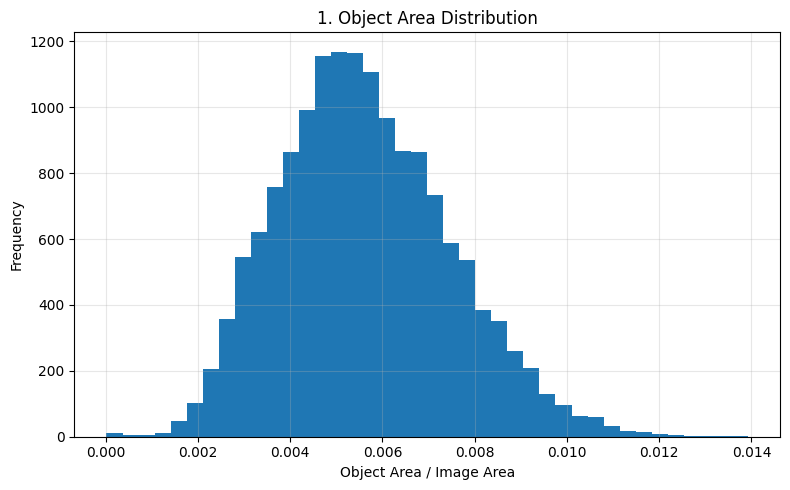

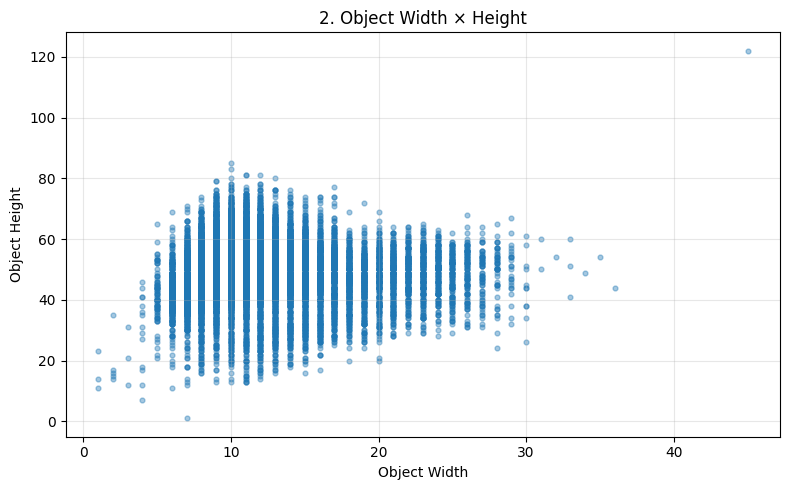

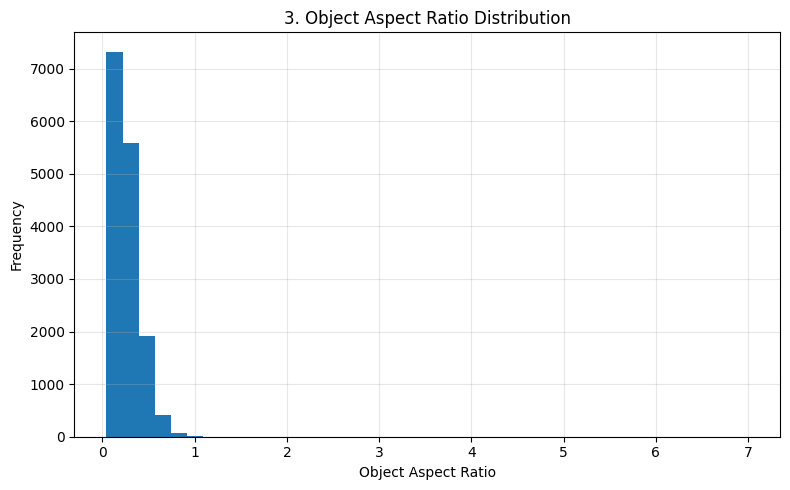

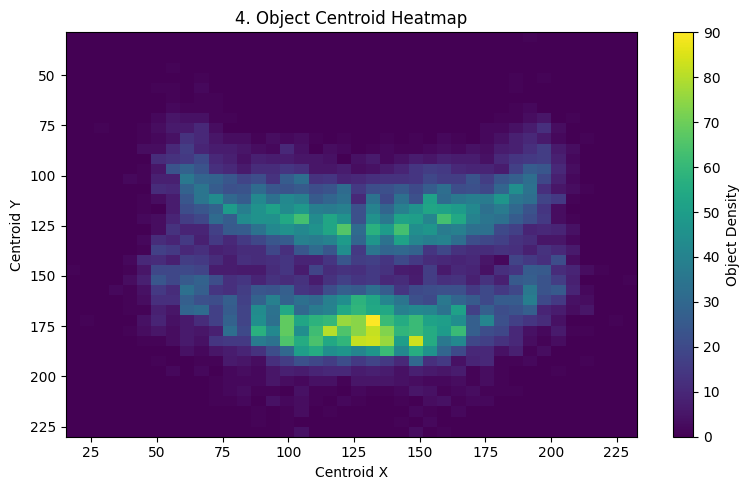

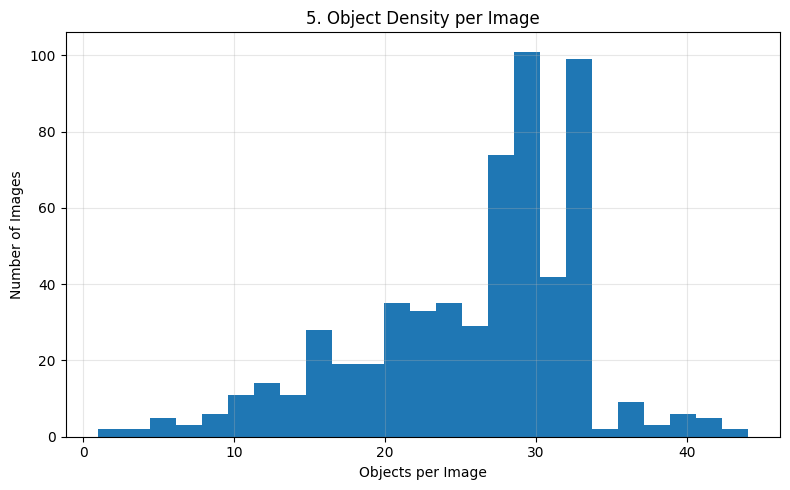

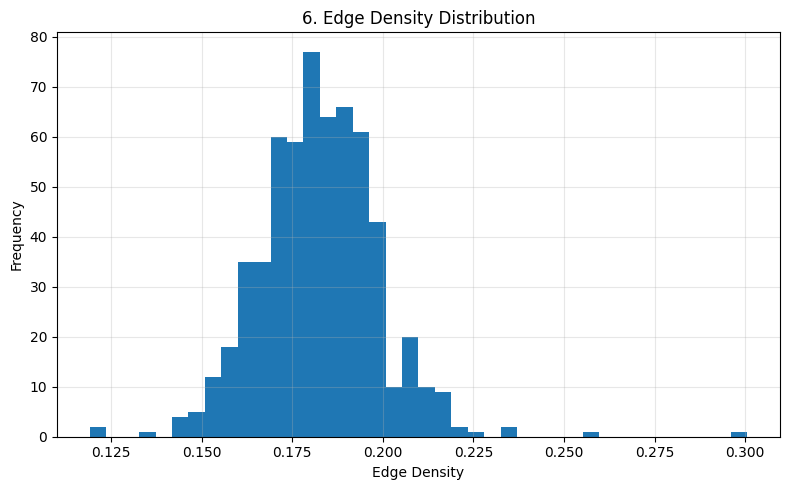

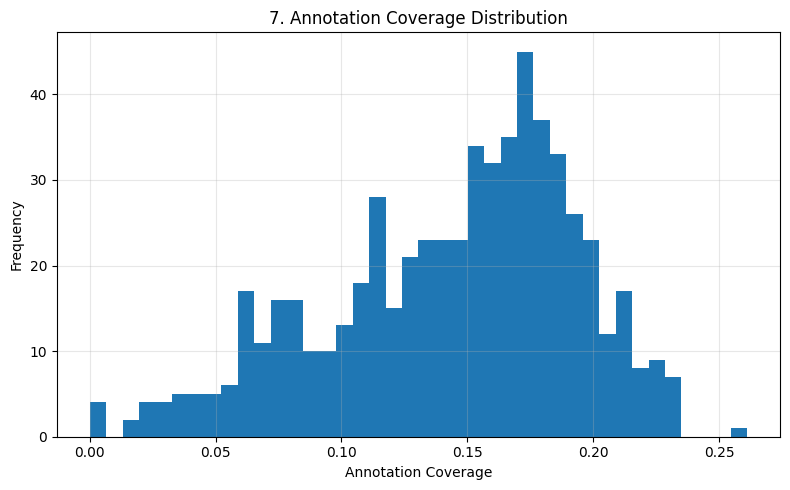

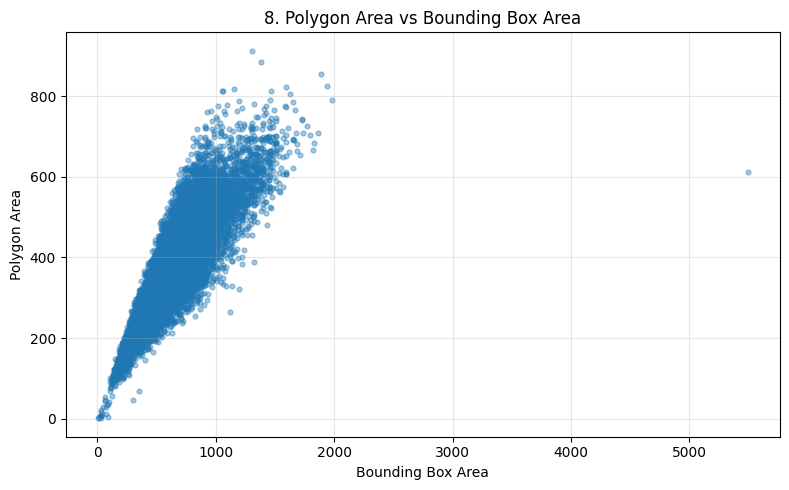

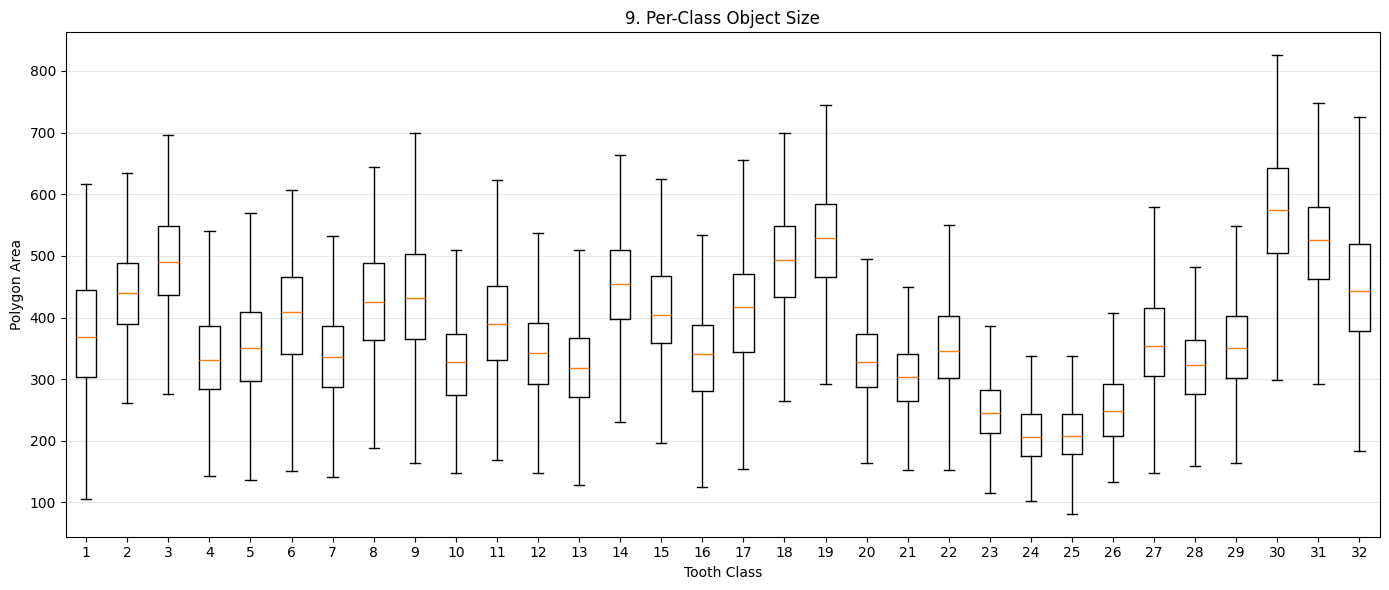

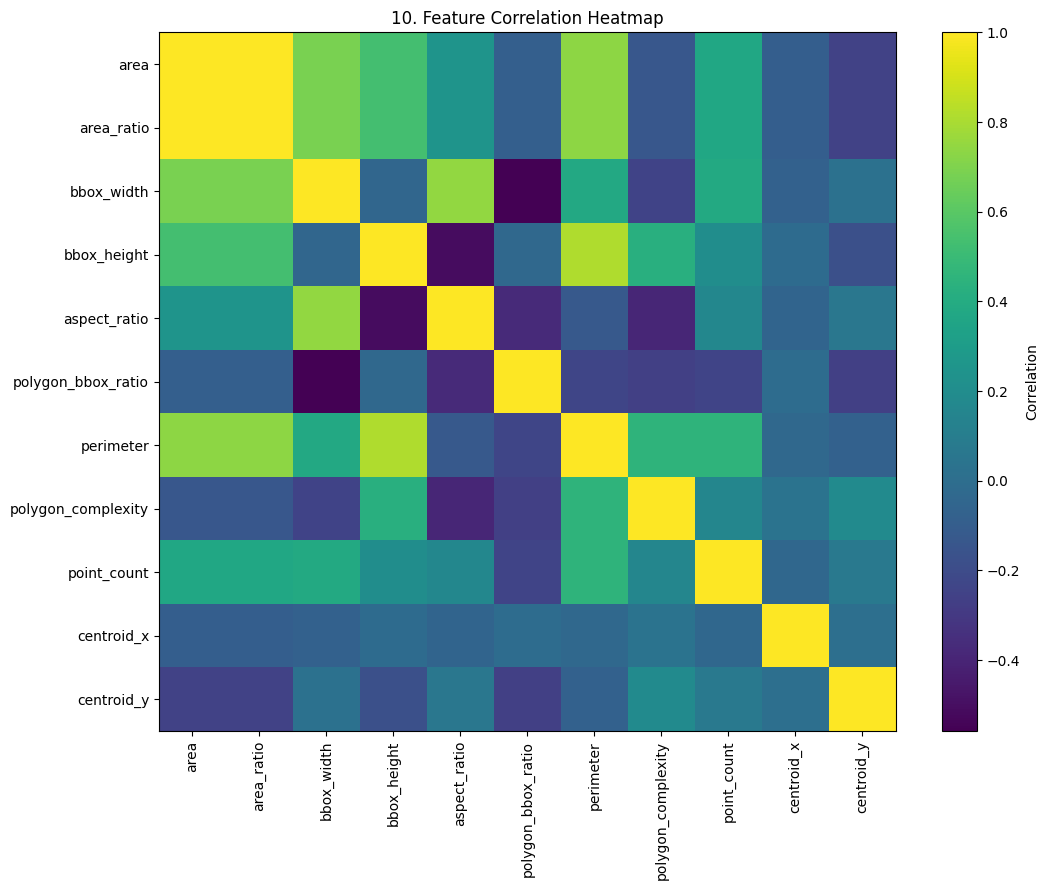



DATA-DRIVEN PROBLEM PROFILE
              Problem  Severity
Multi-Scale Variation  0.769748
  Geometric Variation  0.830252
       Object Density  0.377926
Image/Edge Complexity  0.510033
  Foreground Coverage  0.428094
   Polygon Complexity  0.496473
   Shape Irregularity  0.530499
      Class Imbalance  0.666667


DATA-DRIVEN ARCHITECTURE EVIDENCE SCORE
 Rank                    Block  Evidence_Score                                                                                                         Relevant_Problems
    1               SPP / SPPF        0.639891                                                                              Multi-Scale Variation, Image/Edge Complexity
    2             Dilated Conv        0.592085                                                          Multi-Scale Variation, Image/Edge Complexity, Polygon Complexity
    3          Deformable Conv        0.591814                                        Geometric Variation, Image/Edge Complexity, Pol

In [28]:
# ============================================================
# DENTAL OPG
# DATA-DRIVEN ARCHITECTURE SELECTION EDA
#
# 10 NUMERICAL INDICATORS
# 10 VISUAL INDICATORS
# DATA-DRIVEN ARCHITECTURE EVIDENCE SCORE
#
# Dataset:
# Supervisely Polygon JSON
#
# Image:
# 1.jpg
#
# Annotation:
# 1.jpg.json
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import json
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = Path(
    r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2"
)

IMAGE_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Baseline_CLAHE_256x256"
    / "images"
)

ANNOTATION_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Baseline_CLAHE_256x256"
    / "annotations"
)

OUTPUT_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Architecture_Selection_EDA"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. OUTPUT FILES
# ============================================================

NUMERIC_CSV = (
    OUTPUT_DIR
    / "architecture_numeric_indicators.csv"
)

OBJECT_CSV = (
    OUTPUT_DIR
    / "architecture_object_metrics.csv"
)

CLASS_CSV = (
    OUTPUT_DIR
    / "architecture_class_distribution.csv"
)

DECISION_CSV = (
    OUTPUT_DIR
    / "architecture_evidence_scores.csv"
)

IMAGE_METRICS_CSV = (
    OUTPUT_DIR
    / "architecture_image_metrics.csv"
)


# ============================================================
# 3. PARAMETERS
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

MIN_POLYGON_POINTS = 3


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def polygon_area(points):
    """
    Shoelace formula
    """

    if len(points) < 3:
        return 0.0

    pts = np.asarray(
        points,
        dtype=np.float32
    )

    x = pts[:, 0]
    y = pts[:, 1]

    return float(
        abs(
            np.sum(
                x * np.roll(y, -1)
                -
                y * np.roll(x, -1)
            )
        )
        / 2.0
    )


def polygon_perimeter(points):
    """
    Polygon perimeter.
    """

    if len(points) < 2:
        return 0.0

    pts = np.asarray(
        points,
        dtype=np.float32
    )

    diff = (
        pts
        -
        np.roll(
            pts,
            -1,
            axis=0
        )
    )

    distances = np.sqrt(
        np.sum(
            diff ** 2,
            axis=1
        )
    )

    return float(
        np.sum(distances)
    )


def coefficient_of_variation(values):
    """
    CV = std / mean
    """

    values = np.asarray(
        values,
        dtype=np.float64
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan

    mean_value = np.mean(values)

    if mean_value == 0:
        return np.nan

    return float(
        np.std(values)
        /
        mean_value
    )


def nearest_neighbor_distance(
    centers,
    diagonal
):
    """
    Mean nearest-neighbor distance
    normalized by image diagonal.
    """

    if len(centers) < 2:
        return np.nan

    centers = np.asarray(
        centers,
        dtype=np.float32
    )

    distances = []

    for i in range(
        len(centers)
    ):

        diff = (
            centers
            -
            centers[i]
        )

        dist = np.sqrt(
            np.sum(
                diff ** 2,
                axis=1
            )
        )

        dist = dist[
            dist > 0
        ]

        if len(dist) > 0:

            distances.append(
                np.min(dist)
            )

    if not distances:
        return np.nan

    return float(
        np.mean(distances)
        /
        diagonal
    )


def percentile_severity(
    value,
    values
):
    """
    Convert a value to a percentile [0, 1].

    Larger value = stronger evidence.
    """

    values = np.asarray(
        values,
        dtype=np.float64
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return 0.0

    return float(
        np.mean(
            values <= value
        )
    )


# ============================================================
# 5. FIND IMAGES
# ============================================================

image_paths = sorted([
    p
    for p in IMAGE_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower()
    in IMAGE_EXTENSIONS
])


print("=" * 75)
print("DENTAL OPG - ARCHITECTURE SELECTION EDA")
print("=" * 75)

print(
    f"Image directory      : {IMAGE_DIR}"
)

print(
    f"Annotation directory  : {ANNOTATION_DIR}"
)

print(
    f"Images found         : {len(image_paths)}"
)


# ============================================================
# 6. STORAGE
# ============================================================

object_records = []
image_records = []


# ============================================================
# 7. PROCESS DATASET
# ============================================================

for image_path in image_paths:

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:

        print(
            f"[WARNING] Image read failed: "
            f"{image_path.name}"
        )

        continue


    height, width = image.shape

    image_area = (
        width
        *
        height
    )

    diagonal = np.sqrt(
        width ** 2
        +
        height ** 2
    )


    # --------------------------------------------------------
    # Annotation
    # --------------------------------------------------------

    annotation_path = (
        ANNOTATION_DIR
        /
        f"{image_path.name}.json"
    )

    if not annotation_path.exists():

        print(
            f"[WARNING] Annotation missing: "
            f"{image_path.name}"
        )

        continue


    try:

        with open(
            annotation_path,
            "r",
            encoding="utf-8"
        ) as f:

            annotation = json.load(f)

    except Exception:

        print(
            f"[WARNING] JSON read failed: "
            f"{annotation_path.name}"
        )

        continue


    objects = annotation.get(
        "objects",
        []
    )


    # --------------------------------------------------------
    # Image-level temporary storage
    # --------------------------------------------------------

    areas = []
    area_ratios = []

    aspect_ratios = []

    complexities = []

    polygon_bbox_ratios = []

    centers = []

    total_annotation_area = 0.0


    # ========================================================
    # OBJECT LOOP
    # ========================================================

    for obj in objects:

        if (
            obj.get("geometryType")
            !=
            "polygon"
        ):
            continue


        points_data = obj.get(
            "points",
            {}
        )

        exterior = points_data.get(
            "exterior",
            []
        )


        if len(exterior) < MIN_POLYGON_POINTS:
            continue


        points = np.asarray(
            exterior,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Polygon area
        # ----------------------------------------------------

        area = polygon_area(
            points
        )

        if area <= 0:
            continue


        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        xmin = np.min(
            points[:, 0]
        )

        xmax = np.max(
            points[:, 0]
        )

        ymin = np.min(
            points[:, 1]
        )

        ymax = np.max(
            points[:, 1]
        )


        bbox_width = (
            xmax - xmin
        )

        bbox_height = (
            ymax - ymin
        )


        if (
            bbox_width <= 0
            or
            bbox_height <= 0
        ):
            continue


        bbox_area = (
            bbox_width
            *
            bbox_height
        )


        # ----------------------------------------------------
        # Aspect ratio
        # ----------------------------------------------------

        aspect_ratio = (
            bbox_width
            /
            bbox_height
        )


        # ----------------------------------------------------
        # Polygon / BBox
        # ----------------------------------------------------

        polygon_bbox_ratio = (
            area
            /
            bbox_area
        )


        # ----------------------------------------------------
        # Perimeter
        # ----------------------------------------------------

        perimeter = polygon_perimeter(
            points
        )


        # ----------------------------------------------------
        # Polygon complexity
        # ----------------------------------------------------

        if area > 0:

            complexity = (
                perimeter ** 2
                /
                (
                    4
                    *
                    np.pi
                    *
                    area
                )
            )

        else:

            complexity = np.nan


        # ----------------------------------------------------
        # Centroid
        # ----------------------------------------------------

        centroid_x = np.mean(
            points[:, 0]
        )

        centroid_y = np.mean(
            points[:, 1]
        )


        # ----------------------------------------------------
        # Class
        # ----------------------------------------------------

        class_title = obj.get(
            "classTitle",
            "unknown"
        )


        # ----------------------------------------------------
        # Area ratio
        # ----------------------------------------------------

        area_ratio = (
            area
            /
            image_area
        )


        # ----------------------------------------------------
        # Store object
        # ----------------------------------------------------

        object_records.append({

            "image":
                image_path.name,

            "class":
                str(class_title),

            "area":
                area,

            "area_ratio":
                area_ratio,

            "bbox_width":
                bbox_width,

            "bbox_height":
                bbox_height,

            "bbox_area":
                bbox_area,

            "aspect_ratio":
                aspect_ratio,

            "polygon_bbox_ratio":
                polygon_bbox_ratio,

            "perimeter":
                perimeter,

            "polygon_complexity":
                complexity,

            "centroid_x":
                centroid_x,

            "centroid_y":
                centroid_y,

            "point_count":
                len(points)
        })


        # ----------------------------------------------------
        # Append temporary values
        # ----------------------------------------------------

        areas.append(
            area
        )

        area_ratios.append(
            area_ratio
        )

        aspect_ratios.append(
            aspect_ratio
        )

        complexities.append(
            complexity
        )

        polygon_bbox_ratios.append(
            polygon_bbox_ratio
        )

        centers.append(
            [
                centroid_x,
                centroid_y
            ]
        )

        total_annotation_area += area


    # ========================================================
    # EDGE DENSITY
    # ========================================================

    edges = cv2.Canny(
        image,
        50,
        150
    )

    edge_density = (
        np.count_nonzero(edges)
        /
        image_area
    )


    # ========================================================
    # ANNOTATION COVERAGE
    # ========================================================

    annotation_coverage = (
        total_annotation_area
        /
        image_area
    )


    # ========================================================
    # OBJECT COUNT
    # ========================================================

    object_count = len(
        areas
    )


    # ========================================================
    # OBJECT DENSITY
    #
    # objects per million pixels
    # ========================================================

    object_density = (
        object_count
        /
        image_area
        *
        1_000_000
    )


    # ========================================================
    # INTER-OBJECT DISTANCE
    # normalized by image diagonal
    # ========================================================

    nn_distance = (
        nearest_neighbor_distance(
            centers,
            diagonal
        )
    )


    # ========================================================
    # IMAGE RECORD
    # ========================================================

    image_records.append({

        "image":
            image_path.name,

        "width":
            width,

        "height":
            height,

        "object_count":
            object_count,

        "mean_object_area":
            np.mean(areas)
            if areas
            else np.nan,

        "object_area_ratio":
            np.mean(area_ratios)
            if area_ratios
            else np.nan,

        "object_size_cv":
            coefficient_of_variation(
                areas
            ),

        "object_aspect_ratio_cv":
            coefficient_of_variation(
                aspect_ratios
            ),

        "inter_object_distance":
            nn_distance,

        "object_density":
            object_density,

        "edge_density":
            edge_density,

        "annotation_coverage":
            annotation_coverage,

        "polygon_complexity":
            np.nanmean(
                complexities
            )
            if complexities
            else np.nan,

        "polygon_bbox_ratio":
            np.nanmean(
                polygon_bbox_ratios
            )
            if polygon_bbox_ratios
            else np.nan
    })


# ============================================================
# 8. DATAFRAMES
# ============================================================

object_df = pd.DataFrame(
    object_records
)

image_df = pd.DataFrame(
    image_records
)


if object_df.empty:

    raise RuntimeError(
        "No valid annotation objects were found."
    )


if image_df.empty:

    raise RuntimeError(
        "No valid images were processed."
    )


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

class_counts = (
    object_df[
        "class"
    ]
    .value_counts()
    .sort_index()
)


class_df = pd.DataFrame({

    "class":
        class_counts.index,

    "count":
        class_counts.values
})


class_df[
    "percentage"
] = (
    class_df["count"]
    /
    class_df["count"].sum()
    *
    100
)


class_distribution_cv = (
    coefficient_of_variation(
        class_df["count"]
    )
)


class_df.to_csv(
    CLASS_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. GLOBAL NUMERICAL INDICATORS
# ============================================================

# ------------------------------------------------------------
# 1. Object Area Ratio
# ------------------------------------------------------------

object_area_ratio = (
    object_df[
        "area_ratio"
    ].mean()
)


# ------------------------------------------------------------
# 2. Object Size CV
# ------------------------------------------------------------

object_size_cv = (
    coefficient_of_variation(
        object_df["area"]
    )
)


# ------------------------------------------------------------
# 3. Object Aspect Ratio CV
# ------------------------------------------------------------

object_aspect_ratio_cv = (
    coefficient_of_variation(
        object_df[
            "aspect_ratio"
        ]
    )
)


# ------------------------------------------------------------
# 4. Inter-Object Distance
# ------------------------------------------------------------

inter_object_distance = (
    image_df[
        "inter_object_distance"
    ].mean()
)


# ------------------------------------------------------------
# 5. Object Density
# ------------------------------------------------------------

object_density = (
    image_df[
        "object_density"
    ].mean()
)


# ------------------------------------------------------------
# 6. Edge Density
# ------------------------------------------------------------

edge_density = (
    image_df[
        "edge_density"
    ].mean()
)


# ------------------------------------------------------------
# 7. Annotation Coverage
# ------------------------------------------------------------

annotation_coverage = (
    image_df[
        "annotation_coverage"
    ].mean()
)


# ------------------------------------------------------------
# 8. Polygon Complexity
# ------------------------------------------------------------

polygon_complexity = (
    object_df[
        "polygon_complexity"
    ].mean()
)


# ------------------------------------------------------------
# 9. Polygon / BBox Ratio
# ------------------------------------------------------------

polygon_bbox_ratio = (
    object_df[
        "polygon_bbox_ratio"
    ].mean()
)


# ------------------------------------------------------------
# 10. Class Distribution CV
# ------------------------------------------------------------

class_cv = (
    class_distribution_cv
)


# ============================================================
# 11. NUMERICAL REPORT
# ============================================================

numeric_df = pd.DataFrame({

    "Indicator": [

        "Object Area Ratio",

        "Object Size CV",

        "Object Aspect Ratio CV",

        "Inter-Object Distance",

        "Object Density",

        "Edge Density",

        "Annotation Coverage",

        "Polygon Complexity",

        "Polygon / BBox Ratio",

        "Class Distribution CV"
    ],

    "Value": [

        object_area_ratio,

        object_size_cv,

        object_aspect_ratio_cv,

        inter_object_distance,

        object_density,

        edge_density,

        annotation_coverage,

        polygon_complexity,

        polygon_bbox_ratio,

        class_cv
    ]
})


numeric_df.to_csv(
    NUMERIC_CSV,
    index=False,
    encoding="utf-8-sig"
)


object_df.to_csv(
    OBJECT_CSV,
    index=False,
    encoding="utf-8-sig"
)


image_df.to_csv(
    IMAGE_METRICS_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 12. PRINT NUMERICAL RESULTS
# ============================================================

print("\n")
print("=" * 75)
print("10 NUMERICAL INDICATORS")
print("=" * 75)

print(
    numeric_df.to_string(
        index=False
    )
)


# ============================================================
# 13. VISUALIZATION 1
# Object Area Distribution
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    object_df[
        "area_ratio"
    ],
    bins=40
)

plt.xlabel(
    "Object Area / Image Area"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "1. Object Area Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_01_object_area_distribution.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 14. VISUALIZATION 2
# Object Width × Height
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    object_df[
        "bbox_width"
    ],
    object_df[
        "bbox_height"
    ],
    alpha=0.4,
    s=12
)

plt.xlabel(
    "Object Width"
)

plt.ylabel(
    "Object Height"
)

plt.title(
    "2. Object Width × Height"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_02_object_width_height.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 15. VISUALIZATION 3
# Aspect Ratio Distribution
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    object_df[
        "aspect_ratio"
    ],
    bins=40
)

plt.xlabel(
    "Object Aspect Ratio"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "3. Object Aspect Ratio Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_03_aspect_ratio_distribution.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 16. VISUALIZATION 4
# Centroid Heatmap
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist2d(
    object_df[
        "centroid_x"
    ],
    object_df[
        "centroid_y"
    ],
    bins=40
)

plt.colorbar(
    label="Object Density"
)

plt.gca().invert_yaxis()

plt.xlabel(
    "Centroid X"
)

plt.ylabel(
    "Centroid Y"
)

plt.title(
    "4. Object Centroid Heatmap"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_04_centroid_heatmap.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 17. VISUALIZATION 5
# Object Density per Image
# ============================================================

objects_per_image = (
    object_df
    .groupby("image")
    .size()
)


plt.figure(
    figsize=(8, 5)
)

plt.hist(
    objects_per_image,
    bins=25
)

plt.xlabel(
    "Objects per Image"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "5. Object Density per Image"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_05_object_density.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 18. VISUALIZATION 6
# Edge Density
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    image_df[
        "edge_density"
    ],
    bins=40
)

plt.xlabel(
    "Edge Density"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "6. Edge Density Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_06_edge_density.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 19. VISUALIZATION 7
# Annotation Coverage
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    image_df[
        "annotation_coverage"
    ],
    bins=40
)

plt.xlabel(
    "Annotation Coverage"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "7. Annotation Coverage Distribution"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_07_annotation_coverage.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 20. VISUALIZATION 8
# Polygon Area vs BBox Area
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    object_df[
        "bbox_area"
    ],
    object_df[
        "area"
    ],
    alpha=0.4,
    s=12
)

plt.xlabel(
    "Bounding Box Area"
)

plt.ylabel(
    "Polygon Area"
)

plt.title(
    "8. Polygon Area vs Bounding Box Area"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_08_polygon_vs_bbox.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 21. VISUALIZATION 9
# Per-Class Object Size
# ============================================================

def class_sort_key(x):

    try:
        return int(x)

    except:
        return str(x)


classes = sorted(
    object_df[
        "class"
    ].unique(),
    key=class_sort_key
)


class_area_data = [

    object_df[
        object_df["class"] == cls
    ]["area"]

    for cls in classes
]


plt.figure(
    figsize=(14, 6)
)

plt.boxplot(
    class_area_data,
    labels=classes,
    showfliers=False
)

plt.xlabel(
    "Tooth Class"
)

plt.ylabel(
    "Polygon Area"
)

plt.title(
    "9. Per-Class Object Size"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_09_class_object_size.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 22. VISUALIZATION 10
# Correlation Heatmap
# ============================================================

correlation_columns = [

    "area",

    "area_ratio",

    "bbox_width",

    "bbox_height",

    "aspect_ratio",

    "polygon_bbox_ratio",

    "perimeter",

    "polygon_complexity",

    "point_count",

    "centroid_x",

    "centroid_y"
]


correlation_df = (
    object_df[
        correlation_columns
    ]
    .corr()
)


plt.figure(
    figsize=(11, 9)
)

plt.imshow(
    correlation_df,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(
        len(correlation_columns)
    ),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(
        len(correlation_columns)
    ),
    correlation_columns
)

plt.title(
    "10. Feature Correlation Heatmap"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "plot_10_correlation_heatmap.png",
    dpi=200
)

plt.show()

plt.close()


# ============================================================
# 23. DATA-DRIVEN PROBLEM SEVERITY
# ============================================================

# ------------------------------------------------------------
# Each indicator is converted to a [0,1] severity value.
#
# 0 = weak evidence
# 1 = strong evidence
#
# Important:
# These are calculated from the actual dataset distribution.
# ------------------------------------------------------------


# ------------------------------------------------------------
# Scale variation
# ------------------------------------------------------------

scale_severity = percentile_severity(
    object_size_cv,
    image_df[
        "object_size_cv"
    ]
)


# ------------------------------------------------------------
# Geometry variation
# ------------------------------------------------------------

geometry_severity = percentile_severity(
    object_aspect_ratio_cv,
    image_df[
        "object_aspect_ratio_cv"
    ]
)


# ------------------------------------------------------------
# Object spacing / density
# ------------------------------------------------------------

density_severity = percentile_severity(
    object_density,
    image_df[
        "object_density"
    ]
)


# ------------------------------------------------------------
# Edge / background complexity
# ------------------------------------------------------------

edge_severity = percentile_severity(
    edge_density,
    image_df[
        "edge_density"
    ]
)


# ------------------------------------------------------------
# Annotation / foreground coverage
# ------------------------------------------------------------

coverage_severity = percentile_severity(
    annotation_coverage,
    image_df[
        "annotation_coverage"
    ]
)


# ------------------------------------------------------------
# Shape complexity
# ------------------------------------------------------------

complexity_severity = percentile_severity(
    polygon_complexity,
    object_df[
        "polygon_complexity"
    ]
)


# ------------------------------------------------------------
# Compactness / irregularity
#
# Smaller polygon/bbox ratio
# => more irregular geometry
# ------------------------------------------------------------

compactness_severity = 1 - percentile_severity(
    polygon_bbox_ratio,
    object_df[
        "polygon_bbox_ratio"
    ]
)


# ------------------------------------------------------------
# Class imbalance
# ------------------------------------------------------------

class_imbalance_severity = percentile_severity(
    class_cv,
    np.array([
        0,
        class_cv,
        1
    ])
)


# ============================================================
# 24. PROBLEM PROFILE
# ============================================================

problem_profile = pd.DataFrame({

    "Problem": [

        "Multi-Scale Variation",

        "Geometric Variation",

        "Object Density",

        "Image/Edge Complexity",

        "Foreground Coverage",

        "Polygon Complexity",

        "Shape Irregularity",

        "Class Imbalance"
    ],

    "Severity": [

        scale_severity,

        geometry_severity,

        density_severity,

        edge_severity,

        coverage_severity,

        complexity_severity,

        compactness_severity,

        class_imbalance_severity
    ]
})


print("\n")
print("=" * 75)
print("DATA-DRIVEN PROBLEM PROFILE")
print("=" * 75)

print(
    problem_profile.to_string(
        index=False
    )
)


# ============================================================
# 25. ARCHITECTURE RELEVANCE MAP
# ============================================================
#
# 1 = this block addresses this problem
# 0 = no direct relation
#
# This is NOT an arbitrary score.
# It only defines which EDA signal is relevant to each block.
#
# Final score comes from actual dataset severity.
# ============================================================

architecture_relevance = {

    "Residual Block": [
        0, 0, 1, 0, 0, 0, 0, 0
    ],

    "Bottleneck": [
        0, 0, 0, 0, 0, 0, 0, 0
    ],

    "CSP Block": [
        1, 0, 1, 1, 0, 0, 0, 0
    ],

    "C2f / C3": [
        1, 0, 1, 1, 0, 1, 0, 0
    ],

    "Dense Block": [
        0, 0, 1, 1, 0, 1, 0, 0
    ],

    "Inverted Residual": [
        0, 0, 0, 0, 0, 0, 0, 0
    ],

    "Depthwise Separable Conv": [
        0, 0, 0, 0, 0, 0, 0, 0
    ],

    "Dilated Conv": [
        1, 0, 0, 1, 0, 1, 0, 0
    ],

    "Deformable Conv": [
        0, 1, 0, 1, 0, 1, 1, 0
    ],

    "SPP / SPPF": [
        1, 0, 0, 1, 0, 0, 0, 0
    ],

    "FPN": [
        1, 0, 1, 1, 0, 0, 0, 0
    ],

    "PAN / PANet": [
        1, 0, 1, 1, 0, 0, 0, 0
    ],

    "BiFPN": [
        1, 0, 1, 1, 0, 0, 0, 0
    ],

    "PAFPN": [
        1, 0, 1, 1, 0, 0, 0, 0
    ],

    "SE": [
        0, 0, 0, 1, 0, 0, 0, 0
    ],

    "ECA": [
        0, 0, 0, 1, 0, 0, 0, 0
    ],

    "CBAM": [
        0, 0, 1, 1, 0, 1, 1, 0
    ],

    "Spatial Attention": [
        0, 1, 1, 1, 0, 1, 1, 0
    ],

    "Channel Attention": [
        0, 0, 1, 1, 0, 1, 0, 0
    ],

    "Transformer Block": [
        1, 1, 1, 1, 0, 1, 1, 0
    ],

    "Self-Attention": [
        1, 1, 1, 1, 0, 1, 1, 0
    ],

    "Multi-Head Attention": [
        1, 1, 1, 1, 0, 1, 1, 0
    ],

    "Feature Fusion Block": [
        1, 0, 1, 1, 0, 1, 0, 0
    ]
}


problem_names = [

    "Multi-Scale Variation",

    "Geometric Variation",

    "Object Density",

    "Image/Edge Complexity",

    "Foreground Coverage",

    "Polygon Complexity",

    "Shape Irregularity",

    "Class Imbalance"
]


severity_vector = np.array([
    scale_severity,
    geometry_severity,
    density_severity,
    edge_severity,
    coverage_severity,
    complexity_severity,
    compactness_severity,
    class_imbalance_severity
])


# ============================================================
# 26. CALCULATE DATA-DRIVEN ARCHITECTURE SCORE
# ============================================================

decision_records = []


for block, relevance in architecture_relevance.items():

    relevance = np.array(
        relevance,
        dtype=np.float32
    )


    relevant_indices = (
        relevance > 0
    )


    if not np.any(
        relevant_indices
    ):

        evidence_score = 0.0

    else:

        evidence_score = float(
            np.mean(
                severity_vector[
                    relevant_indices
                ]
            )
        )


    decision_records.append({

        "Block":
            block,

        "Evidence_Score":
            evidence_score,

        "Relevant_Problems":
            ", ".join(
                np.array(
                    problem_names
                )[relevant_indices]
            )
    })


# ============================================================
# 27. SORT RESULTS
# ============================================================

decision_df = pd.DataFrame(
    decision_records
)


decision_df = (
    decision_df
    .sort_values(
        "Evidence_Score",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


decision_df[
    "Rank"
] = np.arange(
    1,
    len(decision_df) + 1
)


decision_df = decision_df[
    [
        "Rank",
        "Block",
        "Evidence_Score",
        "Relevant_Problems"
    ]
]


# ============================================================
# 28. SAVE DECISION MATRIX
# ============================================================

decision_df.to_csv(
    DECISION_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 29. FINAL ARCHITECTURE REPORT
# ============================================================

print("\n")
print("=" * 75)
print("DATA-DRIVEN ARCHITECTURE EVIDENCE SCORE")
print("=" * 75)

print(
    decision_df.to_string(
        index=False
    )
)


# ============================================================
# 30. SAVE PROBLEM PROFILE
# ============================================================

problem_profile_path = (
    OUTPUT_DIR
    /
    "problem_profile.csv"
)

problem_profile.to_csv(
    problem_profile_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 31. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 75)
print("EDA COMPLETED")
print("=" * 75)

print(
    f"Processed images : {len(image_df)}"
)

print(
    f"Annotated objects: {len(object_df)}"
)

print(
    f"Classes          : {len(class_df)}"
)

print("\nOutput directory:")
print(
    OUTPUT_DIR
)

print("\nSaved files:")

print(
    NUMERIC_CSV
)

print(
    OBJECT_CSV
)

print(
    CLASS_CSV
)

print(
    IMAGE_METRICS_CSV
)

print(
    DECISION_CSV
)

print(
    problem_profile_path
)

print("\n10 plots saved successfully.")

## Experiment E: SE Attention with Dropout Regularization

This experiment evaluates the effect of introducing **Spatial Dropout (`Dropout2d`)** into the existing dental OPG segmentation architecture while retaining the Squeeze-and-Excitation (SE) attention mechanism.

The experiment uses the previously established encoder–decoder architecture, consisting of a corrected C2F encoder, Spatial Pyramid Pooling Fast (SPPF), Deformable Convolution, SE channel attention, and a multi-stage decoder. The only intended architectural change in this ablation is the insertion of `Dropout2d` between the Deformable Convolution block and the SE attention module.

### 1. Experimental Configuration

The model is trained using the following configuration:

- **Input resolution:** 256 × 256
- **Input channels:** 1 (grayscale)
- **Number of classes:** 33 (background + 32 tooth classes)
- **Batch size:** 4
- **Maximum epochs:** 50
- **Optimizer:** AdamW
- **Initial learning rate:** 0.001
- **Weight decay:** 0.0001
- **Early stopping patience:** 10 epochs
- **Random seed:** 42
- **Dropout type:** `Dropout2d`
- **Dropout probability:** 0.10

The dataset is loaded from the predefined training, validation, and test splits. Supervisely polygon annotations are converted into semantic segmentation masks, with polygon interiors handled as background regions. Images are resized using area interpolation, while masks use nearest-neighbor interpolation to preserve discrete class IDs. Input images are normalized to the [0, 1] range.

### 2. Architecture and Dropout Placement

The architecture follows this processing sequence:

1. Convolutional stem
2. C2F-based encoder
3. SPPF multi-scale context aggregation
4. Deformable Convolution
5. `Dropout2d` regularization
6. SE channel attention
7. Skip-connected decoder
8. Final 33-class segmentation head

The dropout layer is applied to the feature maps immediately after Deformable Convolution and before SE attention:

**Deformable Convolution → Dropout2d → SE Attention**

With a dropout probability of 0.10, entire feature channels are randomly suppressed during training. This is intended to reduce reliance on specific feature channels and investigate whether channel-level regularization improves generalization.

FPN and the residual block are not included in this experiment. No data augmentation is applied.

### 3. Loss Function and Evaluation Metrics

The training objective combines Cross-Entropy Loss and Foreground Dice Loss with equal weights:

\[
L_{\text{total}} = 0.5L_{\text{CE}} + 0.5L_{\text{Dice}}
\]

The Dice component excludes the background class and evaluates the foreground tooth classes.

The following metrics are recorded for both training and validation:

- Training and validation loss
- Foreground Dice score
- Foreground IoU
- Learning rate
- Epoch execution time

The reported Dice and IoU values are calculated as the mean over classes that have a non-empty prediction or target in each batch.

### 4. Optimization and Model Selection

AdamW is used for optimization. A `ReduceLROnPlateau` scheduler monitors validation Dice and reduces the learning rate when improvement stalls.

The checkpoint with the highest validation Dice score is saved. Early stopping terminates training when validation Dice fails to improve for the configured patience period.

The checkpoint stores the model parameters, optimizer and scheduler states, best validation Dice, selected epoch, and experiment configuration.

Training history is exported to a CSV file for subsequent analysis and visualization.

### 5. Experimental Isolation and Test-Set Protection

This is an ablation experiment intended to investigate the contribution of `Dropout2d` in the presence of SE attention.

**The test set is deliberately not evaluated during this experiment.** Model selection is based exclusively on validation performance, preserving the test set for the final, independent evaluation after architecture selection is complete.

The resulting checkpoint and training history provide the artifacts needed to compare this experiment against the other ablation configurations under the same evaluation protocol.

In [26]:
import os
import json
import random
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision.ops import DeformConv2d


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# 2. Paths
# ============================================================

BASE_DIR = Path(
    r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2"
)

IMAGE_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Baseline_CLAHE_256x256"
    / "images"
)

ANNOTATION_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Baseline_CLAHE_256x256"
    / "annotations"
)

OUTPUT_DIR = (
    BASE_DIR
    / "Preprocessed"
    / "Architecture_Selection_EDA"
)

CHECKPOINT_DIR = BASE_DIR / "checkpoints"

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# Experiment E - SE + Dropout
# ============================================================

EXPERIMENT_NAME = "E_SE_Dropout"

CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / "dental_opg_ablation_E_SE_Dropout.pt"
)

HISTORY_PATH = (
    BASE_DIR
    / "training_history_ablation_E_SE_Dropout.csv"
)


# ============================================================
# 3. Configuration
# ============================================================

IMAGE_SIZE = 256
NUM_CLASSES = 33

BATCH_SIZE = 4
NUM_WORKERS = 0

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

EPOCHS = 50

EARLY_STOPPING_PATIENCE = 10

# ------------------------------------------------------------
# NEW:
# Dropout probability
# ------------------------------------------------------------

DROPOUT_P = 0.10

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print("=" * 70)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print("=" * 70)


# ============================================================
# 4. Utility
# ============================================================

def get_image_paths(split):

    image_dir = (
        BASE_DIR
        / "Preprocessed"
        / "Baseline_CLAHE_256x256"
        / split
        / "images"
    )

    if not image_dir.exists():

        raise FileNotFoundError(
            f"Image directory not found:\n{image_dir}"
        )

    image_paths = sorted(
        list(image_dir.glob("*.jpg"))
        +
        list(image_dir.glob("*.jpeg"))
        +
        list(image_dir.glob("*.png"))
    )

    return image_paths


# ============================================================
# 5. Supervisely JSON → Semantic Mask
# ============================================================

def polygon_to_mask(
    annotation_path,
    height,
    width
):

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    with open(
        annotation_path,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(f)

    for obj in data.get(
        "objects",
        []
    ):

        class_title = obj.get(
            "classTitle"
        )

        if class_title is None:
            continue

        try:

            class_id = int(
                class_title
            )

        except (
            ValueError,
            TypeError
        ):

            continue

        if (
            class_id < 1
            or
            class_id >= NUM_CLASSES
        ):

            continue

        points = obj.get(
            "points",
            {}
        )

        exterior = points.get(
            "exterior",
            []
        )

        if len(exterior) < 3:
            continue

        exterior = np.array(
            exterior,
            dtype=np.int32
        )

        exterior[:, 0] = np.clip(
            exterior[:, 0],
            0,
            width - 1
        )

        exterior[:, 1] = np.clip(
            exterior[:, 1],
            0,
            height - 1
        )

        cv2.fillPoly(
            mask,
            [exterior],
            int(class_id)
        )

        # ----------------------------------------------------
        # Polygon holes
        # ----------------------------------------------------

        for interior in points.get(
            "interior",
            []
        ):

            if len(interior) < 3:
                continue

            interior = np.array(
                interior,
                dtype=np.int32
            )

            interior[:, 0] = np.clip(
                interior[:, 0],
                0,
                width - 1
            )

            interior[:, 1] = np.clip(
                interior[:, 1],
                0,
                height - 1
            )

            cv2.fillPoly(
                mask,
                [interior],
                0
            )

    return mask


# ============================================================
# 6. Dataset
# ============================================================

class DentalOPGDataset(Dataset):

    def __init__(
        self,
        image_paths,
        image_size=256
    ):

        self.image_paths = image_paths
        self.image_size = image_size

    def __len__(self):

        return len(
            self.image_paths
        )

    def __getitem__(
        self,
        index
    ):

        img_path = (
            self.image_paths[index]
        )

        annotation_path = (
            ANNOTATION_DIR
            /
            f"{img_path.name}.json"
        )

        if not annotation_path.exists():

            raise FileNotFoundError(
                f"Annotation not found:\n"
                f"{annotation_path}"
            )

        # ----------------------------------------------------
        # Image
        # ----------------------------------------------------

        image = cv2.imread(
            str(img_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:

            raise ValueError(
                f"Could not read image:\n"
                f"{img_path}"
            )

        original_height, original_width = (
            image.shape
        )

        # ----------------------------------------------------
        # Mask
        # ----------------------------------------------------

        mask = polygon_to_mask(
            annotation_path,
            original_height,
            original_width
        )

        # ----------------------------------------------------
        # Resize
        # ----------------------------------------------------

        image = cv2.resize(
            image,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_AREA
        )

        mask = cv2.resize(
            mask,
            (
                self.image_size,
                self.image_size
            ),
            interpolation=cv2.INTER_NEAREST
        )

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        image = (
            image.astype(
                np.float32
            )
            /
            255.0
        )

        image = torch.from_numpy(
            image
        )

        image = image.unsqueeze(
            0
        )

        mask = torch.from_numpy(
            mask.astype(
                np.int64
            )
        )

        return image, mask


# ============================================================
# 7. Dataset Splits
# ============================================================

train_paths = get_image_paths(
    "train"
)

val_paths = get_image_paths(
    "validation"
)

test_paths = get_image_paths(
    "test"
)

print("\nDataset:")

print(
    "Train:",
    len(train_paths)
)

print(
    "Validation:",
    len(val_paths)
)

print(
    "Test:",
    len(test_paths)
)


train_dataset = DentalOPGDataset(
    train_paths,
    IMAGE_SIZE
)

val_dataset = DentalOPGDataset(
    val_paths,
    IMAGE_SIZE
)

test_dataset = DentalOPGDataset(
    test_paths,
    IMAGE_SIZE
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 8. Basic Conv Block
# ============================================================

class ConvBNAct(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=None
    ):

        super().__init__()

        if padding is None:

            padding = (
                kernel_size // 2
            )

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size,
                stride,
                padding,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.SiLU(
                inplace=True
            )
        )

    def forward(self, x):

        return self.block(x)


# ============================================================
# 9. Corrected C2F Block
# ============================================================

class C2FBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        num_blocks=2
    ):

        super().__init__()

        hidden = (
            out_channels // 2
        )

        self.hidden = hidden

        self.num_blocks = num_blocks

        self.split_conv = ConvBNAct(
            in_channels,
            out_channels,
            kernel_size=1,
            padding=0
        )

        self.blocks = nn.ModuleList([

            nn.Sequential(

                ConvBNAct(
                    hidden,
                    hidden,
                    kernel_size=3,
                    stride=1,
                    padding=1
                ),

                ConvBNAct(
                    hidden,
                    hidden,
                    kernel_size=3,
                    stride=1,
                    padding=1
                )

            )

            for _ in range(
                num_blocks
            )
        ])

        fuse_channels = (
            hidden
            *
            (
                2
                +
                num_blocks
            )
        )

        self.fuse = ConvBNAct(
            fuse_channels,
            out_channels,
            kernel_size=1,
            padding=0
        )

    def forward(self, x):

        x = self.split_conv(
            x
        )

        part1, part2 = torch.chunk(
            x,
            2,
            dim=1
        )

        outputs = [
            part1,
            part2
        ]

        current = part2

        for block in self.blocks:

            current = block(
                current
            )

            outputs.append(
                current
            )

        x = torch.cat(
            outputs,
            dim=1
        )

        return self.fuse(x)


# ============================================================
# 10. SPPF
# ============================================================

class SPPF(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=5
    ):

        super().__init__()

        hidden_channels = (
            in_channels // 2
        )

        self.cv1 = ConvBNAct(
            in_channels,
            hidden_channels,
            kernel_size=1,
            padding=0
        )

        self.pool = nn.MaxPool2d(
            kernel_size=kernel_size,
            stride=1,
            padding=kernel_size // 2
        )

        self.cv2 = ConvBNAct(
            hidden_channels * 4,
            out_channels,
            kernel_size=1,
            padding=0
        )

    def forward(self, x):

        x = self.cv1(x)

        y1 = self.pool(x)

        y2 = self.pool(y1)

        y3 = self.pool(y2)

        x = torch.cat(
            [
                x,
                y1,
                y2,
                y3
            ],
            dim=1
        )

        return self.cv2(x)


# ============================================================
# 11. Deformable Convolution
# ============================================================

class DeformableConvBlock(nn.Module):

    def __init__(
        self,
        channels
    ):

        super().__init__()

        self.offset_conv = nn.Conv2d(
            channels,
            18,
            kernel_size=3,
            stride=1,
            padding=1
        )

        self.deform_conv = DeformConv2d(
            channels,
            channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn = nn.BatchNorm2d(
            channels
        )

        self.act = nn.SiLU(
            inplace=True
        )

    def forward(self, x):

        offset = self.offset_conv(
            x
        )

        x = self.deform_conv(
            x,
            offset
        )

        x = self.bn(x)

        x = self.act(x)

        return x


# ============================================================
# 12. SE Attention
# ============================================================

class SEBlock(nn.Module):

    """
    Squeeze-and-Excitation Attention.

    Input:
        [B, C, H, W]

    Process:
        Global Average Pooling
              ↓
        Channel Reduction
              ↓
        ReLU
              ↓
        Channel Expansion
              ↓
        Sigmoid
              ↓
        Channel-wise Reweighting
    """

    def __init__(
        self,
        channels,
        reduction=16
    ):

        super().__init__()

        reduced_channels = max(
            channels // reduction,
            1
        )

        self.pool = nn.AdaptiveAvgPool2d(
            1
        )

        self.fc = nn.Sequential(

            nn.Linear(
                channels,
                reduced_channels,
                bias=False
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                reduced_channels,
                channels,
                bias=False
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        batch_size, channels, _, _ = (
            x.shape
        )

        # ----------------------------------------------------
        # Squeeze
        # ----------------------------------------------------

        weights = self.pool(
            x
        )

        # ----------------------------------------------------
        # Flatten
        # ----------------------------------------------------

        weights = weights.view(
            batch_size,
            channels
        )

        # ----------------------------------------------------
        # Excitation
        # ----------------------------------------------------

        weights = self.fc(
            weights
        )

        # ----------------------------------------------------
        # Restore spatial dimensions
        # ----------------------------------------------------

        weights = weights.view(
            batch_size,
            channels,
            1,
            1
        )

        # ----------------------------------------------------
        # Channel-wise attention
        # ----------------------------------------------------

        return x * weights


# ============================================================
# 13. Decoder Block
# ============================================================

class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels
    ):

        super().__init__()

        self.conv = nn.Sequential(

            ConvBNAct(
                in_channels + skip_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            ConvBNAct(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            )
        )

    def forward(
        self,
        x,
        skip
    ):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat(
            [
                x,
                skip
            ],
            dim=1
        )

        return self.conv(x)


# ============================================================
# 14. Dental OPG Model
# ============================================================

class DentalOPGNet(nn.Module):

    def __init__(
        self,
        num_classes=33,
        dropout_p=0.10
    ):

        super().__init__()

        # ----------------------------------------------------
        # Stem
        #
        # 256 -> 128
        # ----------------------------------------------------

        self.stem = ConvBNAct(
            1,
            32,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 1
        #
        # 128x128
        # ----------------------------------------------------

        self.enc1 = C2FBlock(
            32,
            64,
            num_blocks=2
        )

        self.down1 = ConvBNAct(
            64,
            128,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 2
        #
        # 64x64
        # ----------------------------------------------------

        self.enc2 = C2FBlock(
            128,
            128,
            num_blocks=2
        )

        self.down2 = ConvBNAct(
            128,
            256,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 3
        #
        # 32x32
        # ----------------------------------------------------

        self.enc3 = C2FBlock(
            256,
            256,
            num_blocks=2
        )

        # ----------------------------------------------------
        # SPPF
        # ----------------------------------------------------

        self.sppf = SPPF(
            256,
            256
        )

        # ----------------------------------------------------
        # Deformable Convolution
        # ----------------------------------------------------

        self.deform = DeformableConvBlock(
            256
        )

        # ====================================================
        # NEW: Dropout2d
        #
        # Deformable Conv
        #        ↓
        #    Dropout2d
        #        ↓
        #       SE
        #
        # Only architectural change in this experiment.
        # ====================================================

        self.dropout = nn.Dropout2d(
            p=dropout_p
        )

        # ----------------------------------------------------
        # SE Attention
        # ----------------------------------------------------

        self.attention = SEBlock(
            channels=256,
            reduction=16
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.dec2 = DecoderBlock(
            256,
            128,
            128
        )

        self.dec1 = DecoderBlock(
            128,
            64,
            64
        )

        # ----------------------------------------------------
        # Segmentation Head
        # ----------------------------------------------------

        self.final_conv = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Stem
        # 256 -> 128
        # ----------------------------------------------------

        x = self.stem(x)

        # ----------------------------------------------------
        # Encoder 1
        # 128x128
        # ----------------------------------------------------

        e1 = self.enc1(x)

        # ----------------------------------------------------
        # Downsample
        # 128 -> 64
        # ----------------------------------------------------

        x = self.down1(
            e1
        )

        # ----------------------------------------------------
        # Encoder 2
        # 64x64
        # ----------------------------------------------------

        e2 = self.enc2(x)

        # ----------------------------------------------------
        # Downsample
        # 64 -> 32
        # ----------------------------------------------------

        x = self.down2(
            e2
        )

        # ----------------------------------------------------
        # Encoder 3
        # 32x32
        # ----------------------------------------------------

        e3 = self.enc3(x)

        # ----------------------------------------------------
        # SPPF
        # ----------------------------------------------------

        x = self.sppf(
            e3
        )

        # ----------------------------------------------------
        # Deformable Conv
        # ----------------------------------------------------

        x = self.deform(
            x
        )

        # ====================================================
        # NEW: Dropout
        # ====================================================

        x = self.dropout(
            x
        )

        # ----------------------------------------------------
        # SE Attention
        # ----------------------------------------------------

        x = self.attention(
            x
        )

        # ----------------------------------------------------
        # Decoder 2
        # 32 -> 64
        # ----------------------------------------------------

        x = self.dec2(
            x,
            e2
        )

        # ----------------------------------------------------
        # Decoder 1
        # 64 -> 128
        # ----------------------------------------------------

        x = self.dec1(
            x,
            e1
        )

        # ----------------------------------------------------
        # 128 -> 256
        # ----------------------------------------------------

        x = F.interpolate(
            x,
            size=(
                IMAGE_SIZE,
                IMAGE_SIZE
            ),
            mode="bilinear",
            align_corners=False
        )

        return self.final_conv(
            x
        )


# ============================================================
# 15. Model
# ============================================================

model = DentalOPGNet(
    num_classes=NUM_CLASSES,
    dropout_p=DROPOUT_P
).to(DEVICE)


# ============================================================
# 16. Parameter Count
# ============================================================

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


total_params = count_parameters(
    model
)

print(
    f"\nTrainable parameters: "
    f"{total_params:,}"
)

print(
    f"Dropout probability: "
    f"{DROPOUT_P}"
)


# ============================================================
# 17. Forward Test
# ============================================================

with torch.no_grad():

    dummy = torch.randn(
        1,
        1,
        IMAGE_SIZE,
        IMAGE_SIZE
    ).to(DEVICE)

    output = model(
        dummy
    )

print(
    "Forward test:",
    tuple(output.shape)
)

assert output.shape == (
    1,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE
)


# ============================================================
# 18. Foreground Dice Loss
# ============================================================

class ForegroundDiceLoss(nn.Module):

    def __init__(
        self,
        smooth=1.0
    ):

        super().__init__()

        self.smooth = smooth

    def forward(
        self,
        logits,
        targets
    ):

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=logits.shape[1]
        )

        targets_one_hot = (
            targets_one_hot
            .permute(
                0,
                3,
                1,
                2
            )
            .float()
        )

        # Remove background

        probabilities = (
            probabilities[:, 1:]
        )

        targets_one_hot = (
            targets_one_hot[:, 1:]
        )

        intersection = (
            probabilities
            *
            targets_one_hot
        ).sum(
            dim=(0, 2, 3)
        )

        denominator = (
            probabilities.sum(
                dim=(0, 2, 3)
            )
            +
            targets_one_hot.sum(
                dim=(0, 2, 3)
            )
        )

        dice = (
            2.0 * intersection
            +
            self.smooth
        ) / (
            denominator
            +
            self.smooth
        )

        return (
            1.0
            -
            dice.mean()
        )


# ============================================================
# 19. Combined Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

        self.ce = nn.CrossEntropyLoss()

        self.dice = ForegroundDiceLoss()

    def forward(
        self,
        logits,
        targets
    ):

        ce_loss = self.ce(
            logits,
            targets
        )

        dice_loss = self.dice(
            logits,
            targets
        )

        return (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )


criterion = CombinedLoss()


# ============================================================
# 20. Metrics
# ============================================================

@torch.no_grad()
def dice_score(
    logits,
    targets,
    num_classes=33
):

    predictions = torch.argmax(
        logits,
        dim=1
    )

    scores = []

    for class_id in range(
        1,
        num_classes
    ):

        pred = (
            predictions == class_id
        )

        target = (
            targets == class_id
        )

        intersection = (
            pred & target
        ).sum().float()

        denominator = (
            pred.sum().float()
            +
            target.sum().float()
        )

        if denominator == 0:
            continue

        dice = (
            2.0 * intersection
            /
            denominator
        )

        scores.append(
            dice.item()
        )

    if not scores:
        return 0.0

    return float(
        np.mean(scores)
    )


@torch.no_grad()
def iou_score(
    logits,
    targets,
    num_classes=33
):

    predictions = torch.argmax(
        logits,
        dim=1
    )

    scores = []

    for class_id in range(
        1,
        num_classes
    ):

        pred = (
            predictions == class_id
        )

        target = (
            targets == class_id
        )

        intersection = (
            pred & target
        ).sum().float()

        union = (
            pred | target
        ).sum().float()

        if union == 0:
            continue

        iou = (
            intersection
            /
            union
        )

        scores.append(
            iou.item()
        )

    if not scores:
        return 0.0

    return float(
        np.mean(scores)
    )


# ============================================================
# 21. Optimizer
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 22. Scheduler
# ============================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4
)


# ============================================================
# 23. Train One Epoch
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            images
        )

        loss = criterion(
            logits,
            masks
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        batch_dice = dice_score(
            logits,
            masks,
            NUM_CLASSES
        )

        batch_iou = iou_score(
            logits,
            masks,
            NUM_CLASSES
        )

        running_loss += (
            loss.item()
        )

        running_dice += (
            batch_dice
        )

        running_iou += (
            batch_iou
        )

        num_batches += 1

    return (
        running_loss / num_batches,
        running_dice / num_batches,
        running_iou / num_batches
    )


# ============================================================
# 24. Validation
# ============================================================

@torch.no_grad()
def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(
            images
        )

        loss = criterion(
            logits,
            masks
        )

        batch_dice = dice_score(
            logits,
            masks,
            NUM_CLASSES
        )

        batch_iou = iou_score(
            logits,
            masks,
            NUM_CLASSES
        )

        running_loss += (
            loss.item()
        )

        running_dice += (
            batch_dice
        )

        running_iou += (
            batch_iou
        )

        num_batches += 1

    return (
        running_loss / num_batches,
        running_dice / num_batches,
        running_iou / num_batches
    )


# ============================================================
# 25. Training Loop
# ============================================================

history = []

best_val_dice = -float(
    "inf"
)

epochs_without_improvement = 0


print("\n" + "=" * 70)

print("START TRAINING")

print(
    "Experiment:",
    EXPERIMENT_NAME
)

print(
    "Architecture:"
)

print(
    "Corrected C2F + SPPF + "
    "DeformableConv + Dropout2d + "
    "SE Attention + Decoder"
)

print(
    "FPN: REMOVED"
)

print(
    "Residual block: REMOVED"
)

print(
    "Attention: SE"
)

print(
    "Dropout2d:",
    f"p={DROPOUT_P}"
)

print(
    "Dropout position:"
)

print(
    "After DeformableConv "
    "and before SE"
)

print(
    "Augmentation: NONE"
)

print(
    "Dice: FOREGROUND ONLY"
)

print("=" * 70)


for epoch in range(
    1,
    EPOCHS + 1
):

    start_time = time.time()

    train_loss, train_dice, train_iou = (
        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE
        )
    )

    val_loss, val_dice, val_iou = (
        validate(
            model,
            val_loader,
            criterion,
            DEVICE
        )
    )

    scheduler.step(
        val_dice
    )

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    epoch_time = (
        time.time()
        -
        start_time
    )

    row = {

        "epoch": epoch,

        "train_loss":
            train_loss,

        "train_dice":
            train_dice,

        "train_iou":
            train_iou,

        "val_loss":
            val_loss,

        "val_dice":
            val_dice,

        "val_iou":
            val_iou,

        "learning_rate":
            current_lr,

        "epoch_time_sec":
            epoch_time
    }

    history.append(
        row
    )

    print(
        f"\nEpoch [{epoch:02d}/{EPOCHS}] "
        f"| "
        f"Train Loss: {train_loss:.4f} "
        f"| Train Dice: {train_dice:.4f} "
        f"| Train IoU: {train_iou:.4f}"
    )

    print(
        f"             "
        f"Val Loss: {val_loss:.4f} "
        f"| Val Dice: {val_dice:.4f} "
        f"| Val IoU: {val_iou:.4f} "
        f"| LR: {current_lr:.2e} "
        f"| Time: {epoch_time:.1f}s"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_dice > best_val_dice:

        best_val_dice = (
            val_dice
        )

        epochs_without_improvement = 0

        checkpoint = {

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "epoch":
                epoch,

            "best_val_dice":
                best_val_dice,

            "config": {

                "experiment":
                    EXPERIMENT_NAME,

                "image_size":
                    IMAGE_SIZE,

                "num_classes":
                    NUM_CLASSES,

                "batch_size":
                    BATCH_SIZE,

                "learning_rate":
                    LEARNING_RATE,

                "weight_decay":
                    WEIGHT_DECAY,

                "seed":
                    SEED,

                # --------------------------------------------
                # Architecture
                # --------------------------------------------

                "architecture":
                    (
                        "Corrected C2F + "
                        "SPPF + "
                        "DeformableConv + "
                        "Dropout2d + "
                        "SE Attention + "
                        "Decoder"
                    ),

                "fpn":
                    False,

                "residual":
                    False,

                "attention":
                    "SE",

                # --------------------------------------------
                # NEW
                # --------------------------------------------

                "dropout":
                    True,

                "dropout_type":
                    "Dropout2d",

                "dropout_probability":
                    DROPOUT_P,

                "dropout_position":
                    (
                        "After DeformableConv "
                        "and before SE"
                    ),

                # --------------------------------------------

                "augmentation":
                    False,

                "dice_loss":
                    "Foreground-only"
            }
        }

        torch.save(
            checkpoint,
            CHECKPOINT_PATH
        )

        print(
            f"  >>> BEST MODEL SAVED "
            f"(Val Dice: "
            f"{best_val_dice:.4f})"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  No improvement "
            f"({epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE})"
        )

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


# ============================================================
# 26. Save Training History
# ============================================================

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print(
    f"\nTraining history saved to:\n"
    f"{HISTORY_PATH}"
)


# ============================================================
# 27. Load Best Model
# ============================================================

print(
    "\nLoading best checkpoint..."
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Dice:",
    checkpoint["best_val_dice"]
)


# ============================================================
# 28. IMPORTANT:
# No Test Evaluation During Ablation
# ============================================================

print("\n" + "=" * 70)

print(
    "ABLATION EXPERIMENT COMPLETED"
)

print("=" * 70)

print(
    "Experiment:",
    EXPERIMENT_NAME
)

print(
    "Architecture:"
)

print(
    "C2F + SPPF + DeformableConv "
    "+ Dropout2d + SE Attention + Decoder"
)

print(
    "FPN: REMOVED"
)

print(
    "Residual block: REMOVED"
)

print(
    "Dropout: Dropout2d"
)

print(
    "Dropout probability:",
    DROPOUT_P
)

print(
    "Dropout position:"
)

print(
    "After DeformableConv "
    "and before SE"
)

print(
    f"Parameters: {total_params:,}"
)

print(
    f"Best Val Dice: "
    f"{checkpoint['best_val_dice']:.4f}"
)

print(
    "\nTest evaluation SKIPPED."
)

print(
    "Test set remains untouched "
    "for architecture selection."
)

print(
    "\nCheckpoint:"
)

print(
    CHECKPOINT_PATH
)

print(
    "\nHistory:"
)

print(
    HISTORY_PATH
)

print("=" * 70)

print("\nDone.")

DEVICE: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA: 12.6

Dataset:
Train: 538
Validation: 59
Test: 1

Trainable parameters: 2,948,307
Dropout probability: 0.1
Forward test: (1, 33, 256, 256)

START TRAINING
Experiment: E_SE_Dropout
Architecture:
Corrected C2F + SPPF + DeformableConv + Dropout2d + SE Attention + Decoder
FPN: REMOVED
Residual block: REMOVED
Attention: SE
Dropout2d: p=0.1
Dropout position:
After DeformableConv and before SE
Augmentation: NONE
Dice: FOREGROUND ONLY

Epoch [01/50] | Train Loss: 1.2413 | Train Dice: 0.0712 | Train IoU: 0.0419
             Val Loss: 0.7756 | Val Dice: 0.1909 | Val IoU: 0.1193 | LR: 1.00e-03 | Time: 31.9s
  >>> BEST MODEL SAVED (Val Dice: 0.1909)

Epoch [02/50] | Train Loss: 0.5520 | Train Dice: 0.4807 | Train IoU: 0.3474
             Val Loss: 0.4996 | Val Dice: 0.5355 | Val IoU: 0.3859 | LR: 1.00e-03 | Time: 33.8s
  >>> BEST MODEL SAVED (Val Dice: 0.5355)

Epoch [03/50] | Train Loss: 0.3223 | Train Dice: 0.6803 | Train IoU: 0.5395
   

Model Evaluation and Visualization
This section evaluates the trained segmentation model on the test dataset and provides a comprehensive performance analysis.

The evaluation includes:
- Training Curves: Training and validation loss, Dice score, IoU, and learning rate.
- Per-Class Metrics: Dice, IoU, Precision, and Recall for each tooth class.
- Prediction Visualization: Comparison of predicted segmentation masks with ground-truth masks.
- Error Analysis: Visualization of pixel-level segmentation errors.
- Confusion Matrix: Pixel-level confusion matrix across all classes.
- Final Summary: Mean Dice, IoU, Precision, and Recall scores.
All generated plots and per-class metrics can optionally be saved to the specified output directory.
 

In [27]:
# ============================================================
# MODEL EVALUATION & VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F


def evaluate_segmentation_model(
    model,
    history_df,
    test_loader,
    device,
    num_classes=33,
    num_visual_samples=4,
    save_dir=None
):
    """
    Complete evaluation and visualization for
    Dental OPG semantic segmentation.

    Generates:

    1. Loss Curve
    2. Dice Curve
    3. IoU Curve
    4. Learning Rate Curve
    5. Prediction vs Ground Truth
    6. Per-Class Dice
    7. Per-Class IoU
    8. Pixel Confusion Matrix
    """


    # ========================================================
    # 1. OUTPUT DIRECTORY
    # ========================================================

    if save_dir is not None:

        save_dir = Path(
            save_dir
        )

        save_dir.mkdir(
            parents=True,
            exist_ok=True
        )


    # ========================================================
    # 2. TRAINING CURVES
    # ========================================================

    epochs = history_df[
        "epoch"
    ].values


    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        epochs,
        history_df["train_loss"],
        label="Train Loss"
    )

    plt.plot(
        epochs,
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        "Training and Validation Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "01_loss_curve.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Dice
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        epochs,
        history_df["train_dice"],
        label="Train Dice"
    )

    plt.plot(
        epochs,
        history_df["val_dice"],
        label="Validation Dice"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Dice"
    )

    plt.title(
        "Training and Validation Dice"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "02_dice_curve.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # IoU
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        epochs,
        history_df["train_iou"],
        label="Train IoU"
    )

    plt.plot(
        epochs,
        history_df["val_iou"],
        label="Validation IoU"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "IoU"
    )

    plt.title(
        "Training and Validation IoU"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "03_iou_curve.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Learning Rate
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        epochs,
        history_df["lr"]
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Learning Rate"
    )

    plt.title(
        "Learning Rate Schedule"
    )

    plt.yscale(
        "log"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "04_learning_rate.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # ========================================================
    # 3. MODEL EVALUATION ON TEST SET
    # ========================================================

    model.eval()


    all_predictions = []

    all_targets = []

    visualization_samples = []


    with torch.no_grad():

        for batch_idx, (
            images,
            masks
        ) in enumerate(
            test_loader
        ):


            images = images.to(
                device
            )

            masks = masks.to(
                device
            )


            logits = model(
                images
            )


            predictions = torch.argmax(
                logits,
                dim=1
            )


            # ------------------------------------------------
            # Store predictions
            # ------------------------------------------------

            all_predictions.append(
                predictions.cpu()
            )


            all_targets.append(
                masks.cpu()
            )


            # ------------------------------------------------
            # Save visual samples
            # ------------------------------------------------

            if len(
                visualization_samples
            ) < num_visual_samples:

                for i in range(
                    images.shape[0]
                ):

                    if len(
                        visualization_samples
                    ) >= num_visual_samples:

                        break


                    visualization_samples.append({

                        "image":
                            images[i]
                            .cpu(),

                        "target":
                            masks[i]
                            .cpu(),

                        "prediction":
                            predictions[i]
                            .cpu()
                    })


    # ========================================================
    # 4. CONCATENATE
    # ========================================================

    all_predictions = torch.cat(
        all_predictions,
        dim=0
    )

    all_targets = torch.cat(
        all_targets,
        dim=0
    )


    # ========================================================
    # 5. PER-CLASS METRICS
    # ========================================================

    per_class_dice = []

    per_class_iou = []

    per_class_precision = []

    per_class_recall = []


    for cls in range(
        1,
        num_classes
    ):

        pred = (
            all_predictions
            ==
            cls
        )

        target = (
            all_targets
            ==
            cls
        )


        tp = (
            pred
            &
            target
        ).sum().item()


        fp = (
            pred
            &
            (~target)
        ).sum().item()


        fn = (
            (~pred)
            &
            target
        ).sum().item()


        # ----------------------------------------------------
        # Dice
        # ----------------------------------------------------

        dice_denominator = (
            2 * tp
            +
            fp
            +
            fn
        )


        if dice_denominator > 0:

            dice = (
                2 * tp
                /
                dice_denominator
            )

        else:

            dice = np.nan


        # ----------------------------------------------------
        # IoU
        # ----------------------------------------------------

        iou_denominator = (
            tp
            +
            fp
            +
            fn
        )


        if iou_denominator > 0:

            iou = (
                tp
                /
                iou_denominator
            )

        else:

            iou = np.nan


        # ----------------------------------------------------
        # Precision
        # ----------------------------------------------------

        precision_denominator = (
            tp
            +
            fp
        )


        if precision_denominator > 0:

            precision = (
                tp
                /
                precision_denominator
            )

        else:

            precision = np.nan


        # ----------------------------------------------------
        # Recall
        # ----------------------------------------------------

        recall_denominator = (
            tp
            +
            fn
        )


        if recall_denominator > 0:

            recall = (
                tp
                /
                recall_denominator
            )

        else:

            recall = np.nan


        per_class_dice.append(
            dice
        )

        per_class_iou.append(
            iou
        )

        per_class_precision.append(
            precision
        )

        per_class_recall.append(
            recall
        )


    # ========================================================
    # 6. METRICS DATAFRAME
    # ========================================================

    class_metrics = pd.DataFrame({

        "class":
            np.arange(
                1,
                num_classes
            ),

        "dice":
            per_class_dice,

        "iou":
            per_class_iou,

        "precision":
            per_class_precision,

        "recall":
            per_class_recall
    })


    if save_dir is not None:

        class_metrics.to_csv(
            save_dir
            /
            "per_class_metrics.csv",
            index=False
        )


    # ========================================================
    # 7. PER-CLASS DICE
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.bar(
        class_metrics["class"].astype(str),
        class_metrics["dice"]
    )

    plt.xlabel(
        "Tooth Class"
    )

    plt.ylabel(
        "Dice"
    )

    plt.title(
        "Per-Class Dice Score"
    )

    plt.ylim(
        0,
        1
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "05_per_class_dice.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # ========================================================
    # 8. PER-CLASS IoU
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.bar(
        class_metrics["class"].astype(str),
        class_metrics["iou"]
    )

    plt.xlabel(
        "Tooth Class"
    )

    plt.ylabel(
        "IoU"
    )

    plt.title(
        "Per-Class IoU"
    )

    plt.ylim(
        0,
        1
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "06_per_class_iou.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # ========================================================
    # 9. VISUAL PREDICTIONS
    # ========================================================

    for idx, sample in enumerate(
        visualization_samples
    ):

        image = sample[
            "image"
        ].squeeze().numpy()


        target = sample[
            "target"
        ].numpy()


        prediction = sample[
            "prediction"
        ].numpy()


        # ----------------------------------------------------
        # Ground Truth
        # ----------------------------------------------------

        plt.figure(
            figsize=(8, 6)
        )

        plt.imshow(
            image,
            cmap="gray"
        )

        plt.imshow(
            target,
            alpha=0.45
        )

        plt.title(
            f"Sample {idx + 1} - Ground Truth"
        )

        plt.axis(
            "off"
        )

        plt.tight_layout()


        if save_dir is not None:

            plt.savefig(
                save_dir
                /
                f"07_sample_{idx+1}_ground_truth.png",
                dpi=200,
                bbox_inches="tight"
            )

        plt.show()

        plt.close()


        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        plt.figure(
            figsize=(8, 6)
        )

        plt.imshow(
            image,
            cmap="gray"
        )

        plt.imshow(
            prediction,
            alpha=0.45
        )

        plt.title(
            f"Sample {idx + 1} - Prediction"
        )

        plt.axis(
            "off"
        )

        plt.tight_layout()


        if save_dir is not None:

            plt.savefig(
                save_dir
                /
                f"08_sample_{idx+1}_prediction.png",
                dpi=200,
                bbox_inches="tight"
            )

        plt.show()

        plt.close()


        # ----------------------------------------------------
        # Error Map
        # ----------------------------------------------------

        error = (
            prediction
            !=
            target
        )


        plt.figure(
            figsize=(8, 6)
        )

        plt.imshow(
            image,
            cmap="gray"
        )

        plt.imshow(
            error,
            alpha=0.5
        )

        plt.title(
            f"Sample {idx + 1} - Segmentation Error"
        )

        plt.axis(
            "off"
        )

        plt.tight_layout()


        if save_dir is not None:

            plt.savefig(
                save_dir
                /
                f"09_sample_{idx+1}_error.png",
                dpi=200,
                bbox_inches="tight"
            )

        plt.show()

        plt.close()


    # ========================================================
    # 10. PIXEL CONFUSION MATRIX
    # ========================================================

    confusion_matrix = np.zeros(
        (
            num_classes,
            num_classes
        ),
        dtype=np.int64
    )


    target_flat = (
        all_targets
        .numpy()
        .reshape(-1)
    )


    prediction_flat = (
        all_predictions
        .numpy()
        .reshape(-1)
    )


    valid = (
        (target_flat >= 0)
        &
        (target_flat < num_classes)
    )


    target_flat = (
        target_flat[valid]
    )

    prediction_flat = (
        prediction_flat[valid]
    )


    np.add.at(
        confusion_matrix,
        (
            target_flat,
            prediction_flat
        ),
        1
    )


    # --------------------------------------------------------
    # Confusion Matrix Visualization
    # --------------------------------------------------------

    plt.figure(
        figsize=(12, 10)
    )

    plt.imshow(
        confusion_matrix,
        interpolation="nearest"
    )

    plt.colorbar(
        label="Pixel Count"
    )

    plt.xlabel(
        "Predicted Class"
    )

    plt.ylabel(
        "True Class"
    )

    plt.title(
        "Pixel-Level Confusion Matrix"
    )

    plt.tight_layout()


    if save_dir is not None:

        plt.savefig(
            save_dir
            /
            "10_confusion_matrix.png",
            dpi=200
        )

    plt.show()

    plt.close()


    # ========================================================
    # 11. FINAL SUMMARY
    # ========================================================

    mean_dice = np.nanmean(
        class_metrics["dice"]
    )

    mean_iou = np.nanmean(
        class_metrics["iou"]
    )

    mean_precision = np.nanmean(
        class_metrics["precision"]
    )

    mean_recall = np.nanmean(
        class_metrics["recall"]
    )


    print("\n")
    print("=" * 70)
    print("FINAL SEGMENTATION EVALUATION")
    print("=" * 70)

    print(
        f"Mean Dice      : {mean_dice:.4f}"
    )

    print(
        f"Mean IoU       : {mean_iou:.4f}"
    )

    print(
        f"Mean Precision : {mean_precision:.4f}"
    )

    print(
        f"Mean Recall    : {mean_recall:.4f}"
    )

    print("=" * 70)


    # ========================================================
    # 12. RETURN RESULTS
    # ========================================================

    return {

        "mean_dice":
            mean_dice,

        "mean_iou":
            mean_iou,

        "mean_precision":
            mean_precision,

        "mean_recall":
            mean_recall,

        "class_metrics":
            class_metrics,

        "confusion_matrix":
            confusion_matrix
    }

In [28]:
history_df = pd.DataFrame(history)
history_df 

,epoch,train_loss,train_dice,train_iou,val_loss,val_dice,val_iou,learning_rate,epoch_time_sec
0,1,1.241311,0.071171,0.041940,0.775576,0.190927,0.119314,0.001000,31.890285
1,2,0.552018,0.480712,0.347380,0.499642,0.535487,0.385884,0.001000,33.803372
2,3,0.322308,0.680343,0.539494,0.296819,0.700093,0.559234,0.001000,33.974255
3,4,0.243270,0.751939,0.620521,0.260020,0.722595,0.591875,0.001000,34.336439
4,5,0.223088,0.763498,0.637732,0.234173,0.758973,0.633985,0.001000,33.921530
5,6,0.209811,0.778250,0.655745,0.211651,0.773489,0.651796,0.001000,33.739378
6,7,0.193193,0.793872,0.677750,0.217385,0.768393,0.645175,0.001000,33.766112
7,8,0.178490,0.810744,0.697372,0.208436,0.780154,0.660026,0.001000,34.281530
8,9,0.177756,0.811589,0.699434,0.235502,0.749033,0.624643,0.001000,33.469397
9,10,0.166832,0.822973,0.713517,0.208453,0.781265,0.662267,0.001000,37.430897


Model Evaluation and Visualization
This section performs a comprehensive evaluation of the trained segmentation model on the test dataset, aligned with the current training pipeline.

The evaluation includes:
- Training Analysis: Total loss, Cross-Entropy loss, Dice loss, Dice score, IoU, and learning rate curves.
- Per-Class Metrics: Dice, IoU, Precision, Recall, Specificity, and pixel support for each class.
- Foreground Evaluation: Separate analysis of tooth classes, excluding the background class.
- Prediction Visualization: Ground-truth masks, predicted masks, and segmentation error maps.
- Confusion Matrix: Global pixel-level confusion matrices, including raw and row-normalized results.
- Final Summary: Mean evaluation metrics with optional background exclusion.
All evaluation metrics, visualizations, and summary results can optionally be exported to the specified output directory for further analysis.

In [30]:
# ============================================================
# MODEL EVALUATION & VISUALIZATION (Aligned with current training)
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


def evaluate_segmentation_model(
    model,
    history_df,
    test_loader,
    device,
    num_classes=33,
    num_visual_samples=4,
    save_dir=None,
    ignore_background_in_summary=True
):
    """
    Complete evaluation and visualization for Dental OPG semantic segmentation.

    Aligned with training pipeline:
      - Global pixel confusion matrix over full test set
      - Foreground mean metrics (classes 1..num_classes-1)
      - Supports history columns from current script:
            learning_rate, train_ce, val_ce, train_dice_loss, val_dice_loss
    """

    # ========================================================
    # 1. OUTPUT DIRECTORY
    # ========================================================

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    # ========================================================
    # 2. TRAINING CURVES
    # ========================================================

    epochs = history_df["epoch"].values

    # -----------------------------
    # 2.1 Total Loss
    # -----------------------------
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df["train_loss"], label="Train Loss")
    plt.plot(epochs, history_df["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Total Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "01_loss_curve.png", dpi=200)
    plt.show()
    plt.close()

    # -----------------------------
    # 2.2 CE Loss (if available)
    # -----------------------------
    if {"train_ce", "val_ce"}.issubset(history_df.columns):
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, history_df["train_ce"], label="Train CE")
        plt.plot(epochs, history_df["val_ce"], label="Validation CE")
        plt.xlabel("Epoch")
        plt.ylabel("Cross-Entropy")
        plt.title("Training and Validation CE Loss")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / "02_ce_curve.png", dpi=200)
        plt.show()
        plt.close()

    # -----------------------------
    # 2.3 Dice Loss (if available)
    # -----------------------------
    if {"train_dice_loss", "val_dice_loss"}.issubset(history_df.columns):
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, history_df["train_dice_loss"], label="Train Dice Loss")
        plt.plot(epochs, history_df["val_dice_loss"], label="Validation Dice Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Dice Loss")
        plt.title("Training and Validation Dice Loss")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / "03_dice_loss_curve.png", dpi=200)
        plt.show()
        plt.close()

    # -----------------------------
    # 2.4 Dice Score
    # -----------------------------
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df["train_dice"], label="Train Dice")
    plt.plot(epochs, history_df["val_dice"], label="Validation Dice")
    plt.xlabel("Epoch")
    plt.ylabel("Dice")
    plt.title("Training and Validation Dice")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "04_dice_curve.png", dpi=200)
    plt.show()
    plt.close()

    # -----------------------------
    # 2.5 IoU Score
    # -----------------------------
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history_df["train_iou"], label="Train IoU")
    plt.plot(epochs, history_df["val_iou"], label="Validation IoU")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.title("Training and Validation IoU")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "05_iou_curve.png", dpi=200)
    plt.show()
    plt.close()

    # -----------------------------
    # 2.6 Learning Rate
    # -----------------------------
    lr_col = "learning_rate" if "learning_rate" in history_df.columns else ("lr" if "lr" in history_df.columns else None)
    if lr_col is not None:
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, history_df[lr_col])
        plt.xlabel("Epoch")
        plt.ylabel("Learning Rate")
        plt.title("Learning Rate Schedule")
        plt.yscale("log")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / "06_learning_rate.png", dpi=200)
        plt.show()
        plt.close()

    # ========================================================
    # 3. MODEL EVALUATION ON TEST SET (GLOBAL CONFUSION MATRIX)
    # ========================================================

    model.eval()

    confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    visualization_samples = []

    with torch.no_grad():
        for images, masks in test_loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(images)
            preds = torch.argmax(logits, dim=1)

            # Update confusion matrix (global)
            t = masks.view(-1).cpu().numpy()
            p = preds.view(-1).cpu().numpy()

            valid = (t >= 0) & (t < num_classes)
            t = t[valid]
            p = p[valid]

            np.add.at(confusion_matrix, (t, p), 1)

            # Store visual samples
            if len(visualization_samples) < num_visual_samples:
                for i in range(images.shape[0]):
                    if len(visualization_samples) >= num_visual_samples:
                        break
                    visualization_samples.append({
                        "image": images[i].cpu(),
                        "target": masks[i].cpu(),
                        "prediction": preds[i].cpu()
                    })

    # ========================================================
    # 4. PER-CLASS METRICS FROM CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix.astype(np.float64)

    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - (tp + fp + fn)

    eps = 1e-12

    per_class_dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    per_class_iou = (tp + eps) / (tp + fp + fn + eps)
    per_class_precision = (tp + eps) / (tp + fp + eps)
    per_class_recall = (tp + eps) / (tp + fn + eps)
    per_class_specificity = (tn + eps) / (tn + fp + eps)
    per_class_support = cm.sum(axis=1)  # true pixels per class

    class_metrics = pd.DataFrame({
        "class": np.arange(num_classes),
        "dice": per_class_dice,
        "iou": per_class_iou,
        "precision": per_class_precision,
        "recall": per_class_recall,
        "specificity": per_class_specificity,
        "support_pixels": per_class_support.astype(np.int64)
    })

    # foreground-only view for teeth classes
    fg_metrics = class_metrics[class_metrics["class"] != 0].copy()

    if save_dir is not None:
        class_metrics.to_csv(save_dir / "per_class_metrics_all_classes.csv", index=False)
        fg_metrics.to_csv(save_dir / "per_class_metrics_foreground.csv", index=False)

    # ========================================================
    # 5. PER-CLASS BARS (FOREGROUND)
    # ========================================================

    plt.figure(figsize=(14, 6))
    plt.bar(fg_metrics["class"].astype(str), fg_metrics["dice"])
    plt.xlabel("Tooth Class")
    plt.ylabel("Dice")
    plt.title("Per-Class Dice Score (Foreground)")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "07_per_class_dice_fg.png", dpi=200)
    plt.show()
    plt.close()

    plt.figure(figsize=(14, 6))
    plt.bar(fg_metrics["class"].astype(str), fg_metrics["iou"])
    plt.xlabel("Tooth Class")
    plt.ylabel("IoU")
    plt.title("Per-Class IoU (Foreground)")
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "08_per_class_iou_fg.png", dpi=200)
    plt.show()
    plt.close()

    # ========================================================
    # 6. VISUAL PREDICTIONS
    # ========================================================

    for idx, sample in enumerate(visualization_samples, start=1):

        image = sample["image"].squeeze().numpy()
        target = sample["target"].numpy()
        prediction = sample["prediction"].numpy()
        error = prediction != target

        # GT
        plt.figure(figsize=(8, 6))
        plt.imshow(image, cmap="gray")
        plt.imshow(target, alpha=0.45)
        plt.title(f"Sample {idx} - Ground Truth")
        plt.axis("off")
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / f"09_sample_{idx}_ground_truth.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close()

        # Pred
        plt.figure(figsize=(8, 6))
        plt.imshow(image, cmap="gray")
        plt.imshow(prediction, alpha=0.45)
        plt.title(f"Sample {idx} - Prediction")
        plt.axis("off")
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / f"10_sample_{idx}_prediction.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close()

        # Error
        plt.figure(figsize=(8, 6))
        plt.imshow(image, cmap="gray")
        plt.imshow(error, alpha=0.5)
        plt.title(f"Sample {idx} - Segmentation Error")
        plt.axis("off")
        plt.tight_layout()
        if save_dir is not None:
            plt.savefig(save_dir / f"11_sample_{idx}_error.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close()

    # ========================================================
    # 7. CONFUSION MATRICES (RAW + NORMALIZED)
    # ========================================================

    # Raw
    plt.figure(figsize=(12, 10))
    plt.imshow(confusion_matrix, interpolation="nearest")
    plt.colorbar(label="Pixel Count")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title("Pixel-Level Confusion Matrix (Raw)")
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "12_confusion_matrix_raw.png", dpi=200)
    plt.show()
    plt.close()

    # Row-normalized
    row_sum = confusion_matrix.sum(axis=1, keepdims=True)
    cm_norm = confusion_matrix / np.clip(row_sum, a_min=1, a_max=None)

    plt.figure(figsize=(12, 10))
    plt.imshow(cm_norm, interpolation="nearest", vmin=0.0, vmax=1.0)
    plt.colorbar(label="Row-normalized ratio")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title("Pixel-Level Confusion Matrix (Row-Normalized)")
    plt.tight_layout()
    if save_dir is not None:
        plt.savefig(save_dir / "13_confusion_matrix_normalized.png", dpi=200)
    plt.show()
    plt.close()

    # ========================================================
    # 8. FINAL SUMMARY
    # ========================================================

    summary_df = fg_metrics if ignore_background_in_summary else class_metrics

    mean_dice = float(summary_df["dice"].mean())
    mean_iou = float(summary_df["iou"].mean())
    mean_precision = float(summary_df["precision"].mean())
    mean_recall = float(summary_df["recall"].mean())
    mean_specificity = float(summary_df["specificity"].mean())

    print("\n" + "=" * 70)
    print("FINAL SEGMENTATION EVALUATION")
    print("=" * 70)
    print(f"Classes used in summary : {'Foreground only (1..N-1)' if ignore_background_in_summary else 'All classes (0..N-1)'}")
    print(f"Mean Dice               : {mean_dice:.4f}")
    print(f"Mean IoU                : {mean_iou:.4f}")
    print(f"Mean Precision          : {mean_precision:.4f}")
    print(f"Mean Recall             : {mean_recall:.4f}")
    print(f"Mean Specificity        : {mean_specificity:.4f}")
    print("=" * 70)

    if save_dir is not None:
        summary = pd.DataFrame([{
            "summary_scope": "foreground" if ignore_background_in_summary else "all_classes",
            "mean_dice": mean_dice,
            "mean_iou": mean_iou,
            "mean_precision": mean_precision,
            "mean_recall": mean_recall,
            "mean_specificity": mean_specificity
        }])
        summary.to_csv(save_dir / "evaluation_summary.csv", index=False)

    # ========================================================
    # 9. RETURN RESULTS
    # ========================================================

    return {
        "mean_dice": mean_dice,
        "mean_iou": mean_iou,
        "mean_precision": mean_precision,
        "mean_recall": mean_recall,
        "mean_specificity": mean_specificity,
        "class_metrics_all": class_metrics,
        "class_metrics_fg": fg_metrics,
        "confusion_matrix_raw": confusion_matrix,
        "confusion_matrix_normalized": cm_norm
    }


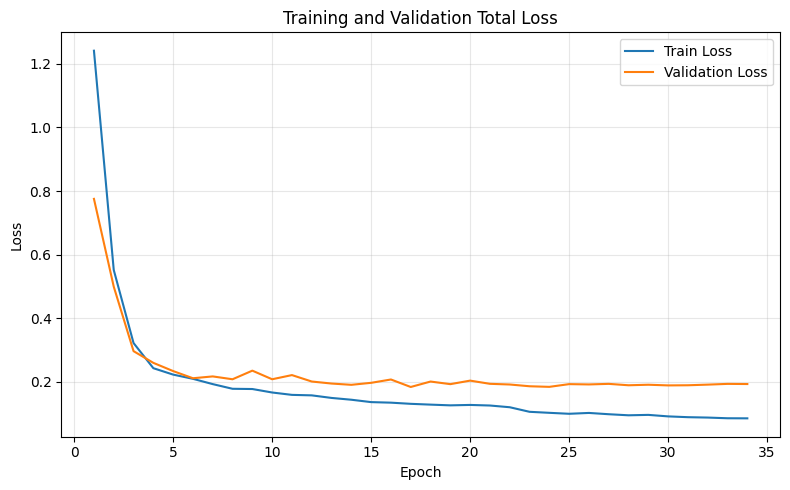

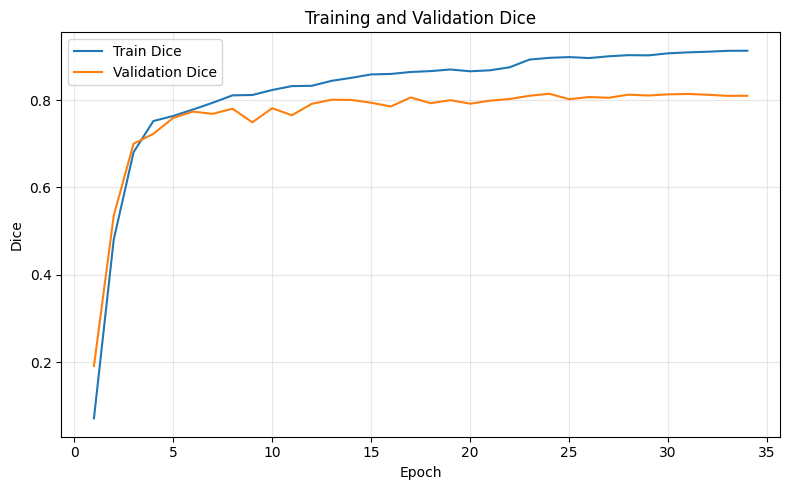

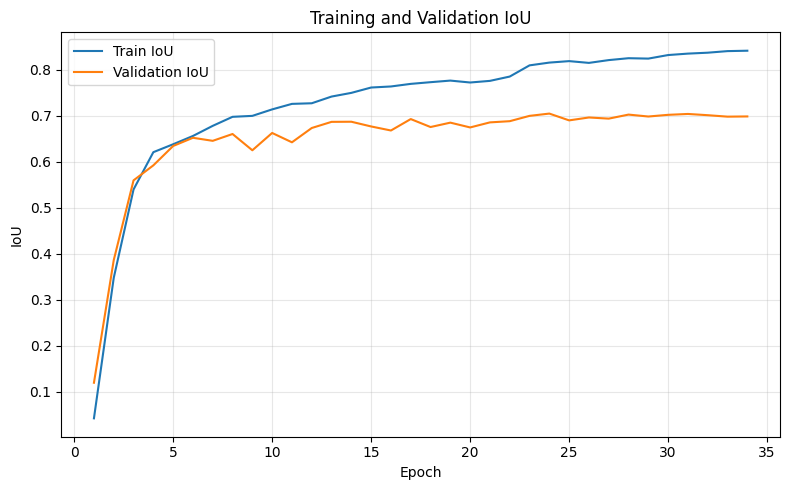

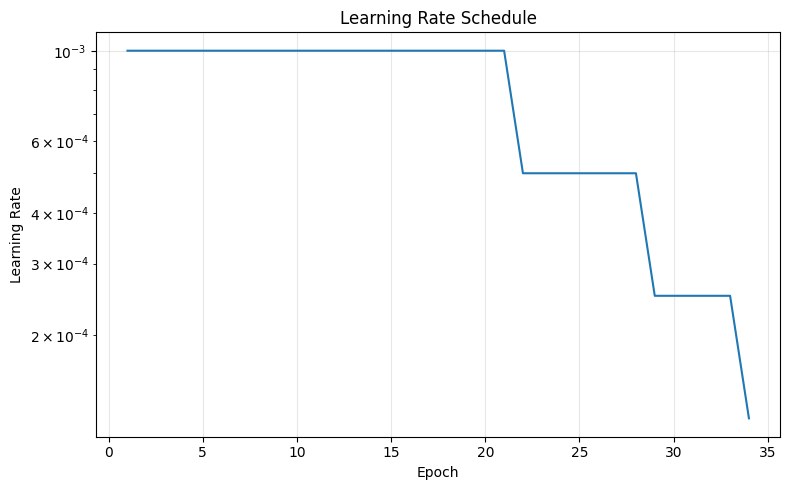

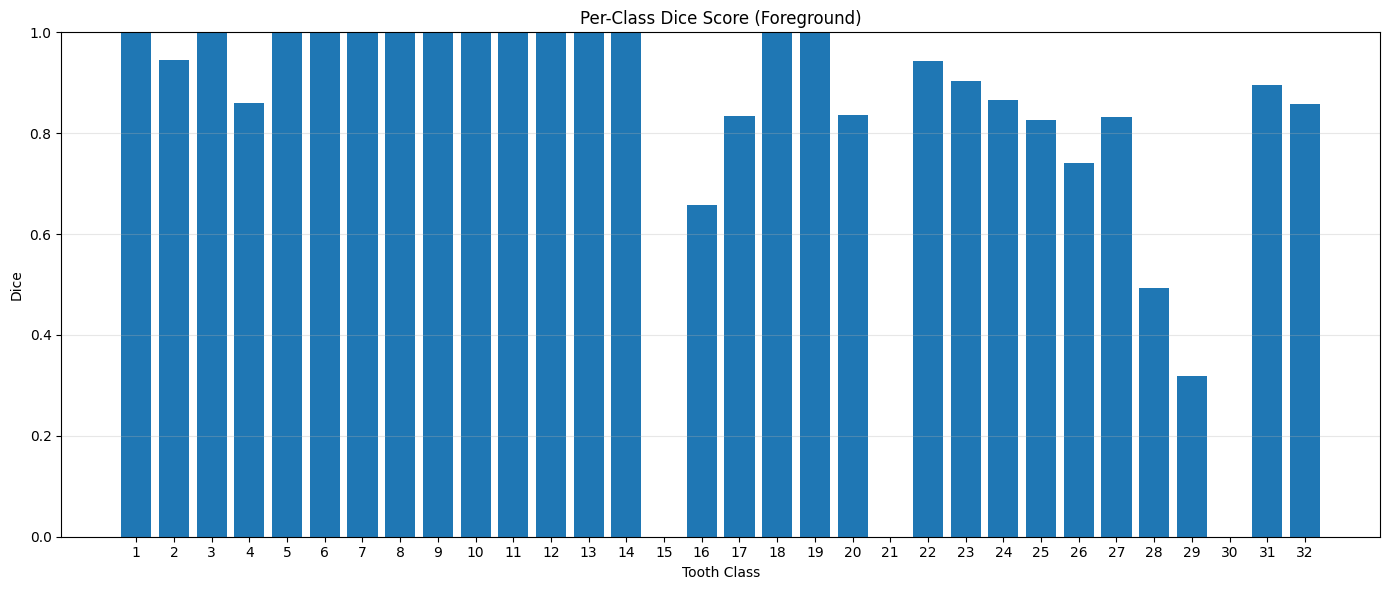

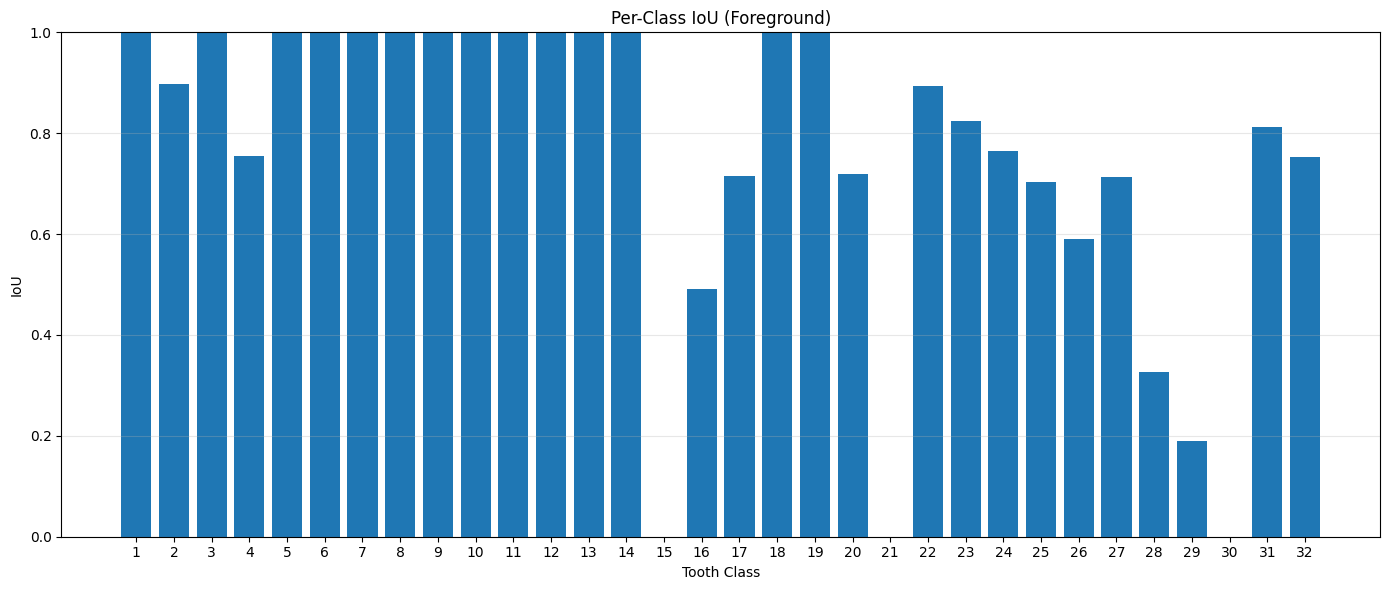

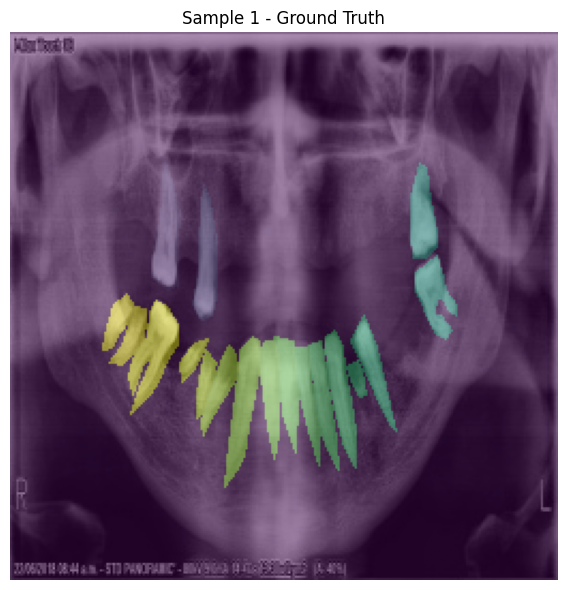

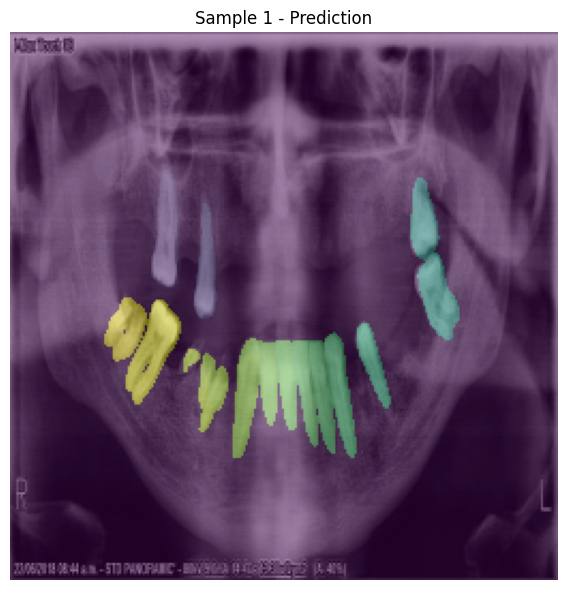

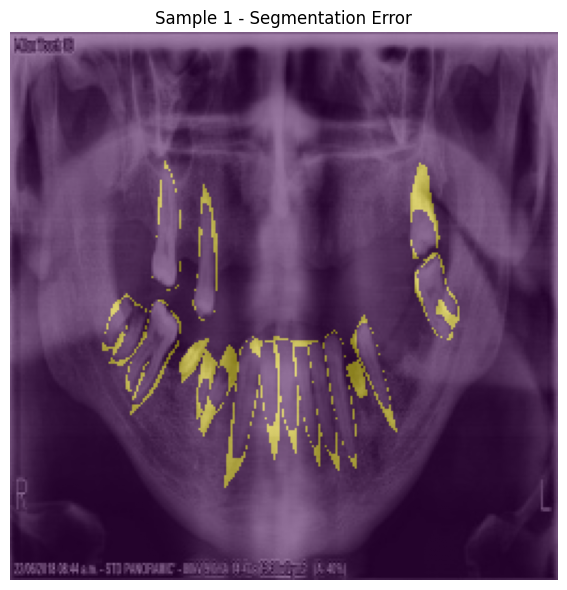

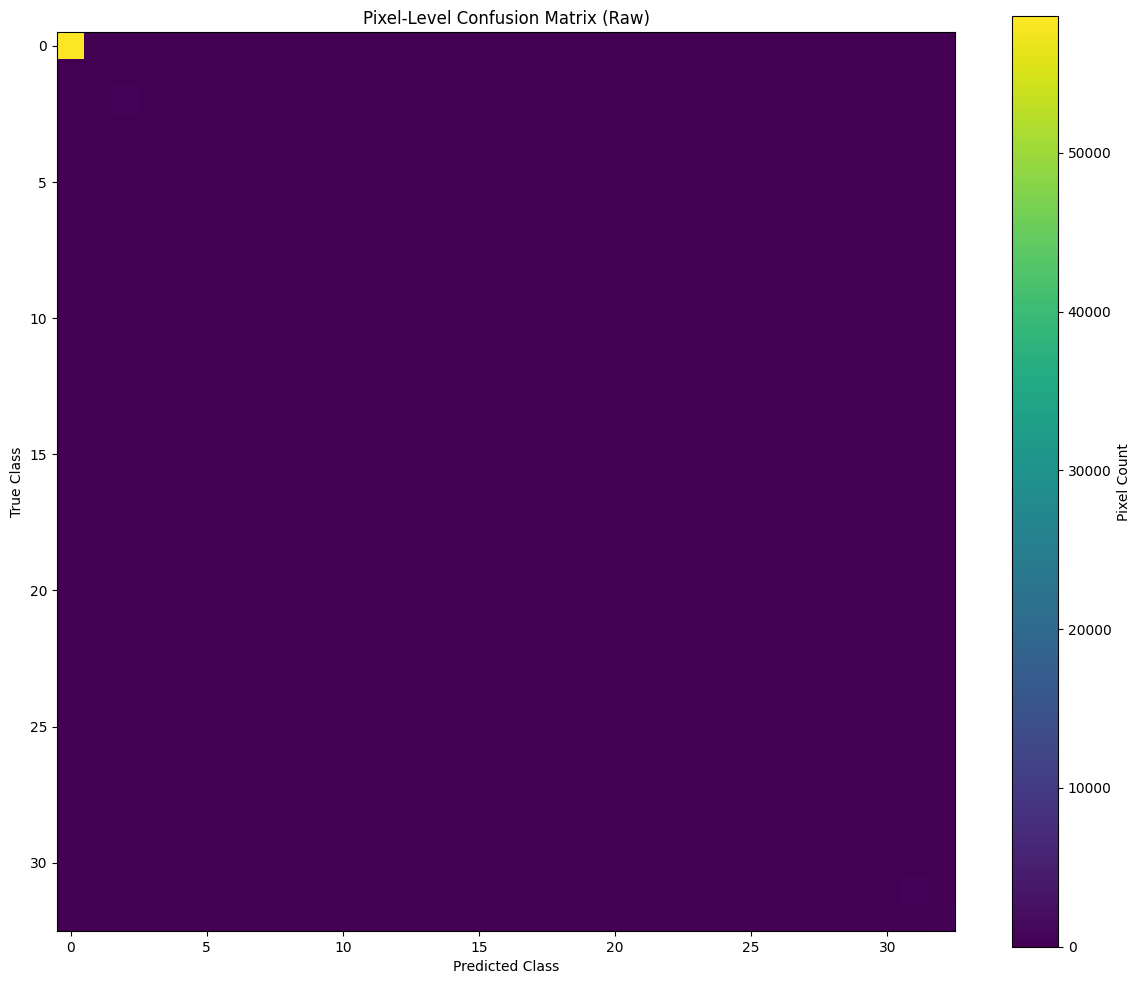

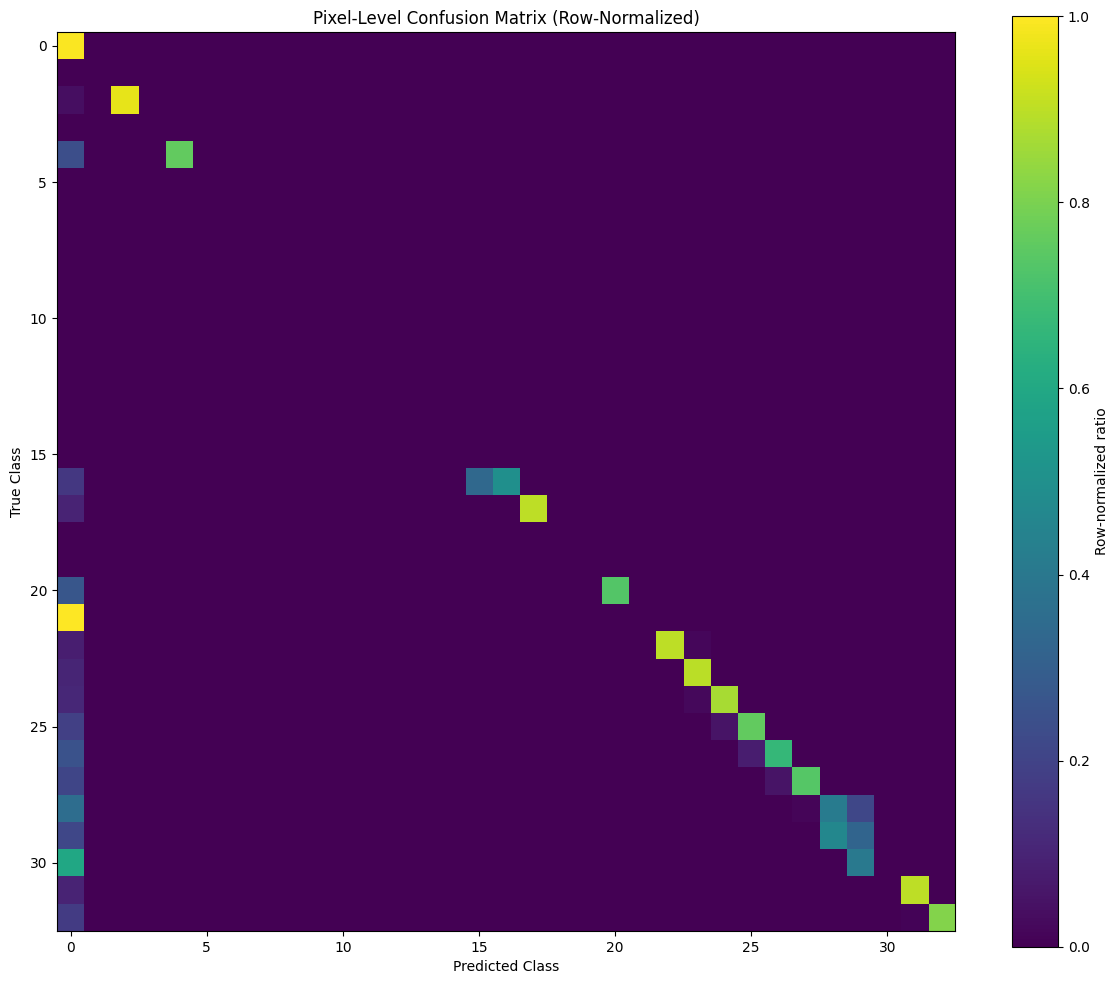


FINAL SEGMENTATION EVALUATION
Classes used in summary : Foreground only (1..N-1)
Mean Dice               : 0.8067
Mean IoU                : 0.7546
Mean Precision          : 0.9010
Mean Recall             : 0.8167
Mean Specificity        : 0.9996


In [31]:
results = evaluate_segmentation_model(
    model=model,
    history_df=history_df,           
    test_loader=test_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
    num_visual_samples=4,
    save_dir=BASE_DIR / "evaluation_E_SE_Dropout",
    ignore_background_in_summary=True
)


In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.ops as ops

IMAGE_SIZE = 256

# =========================================================
# 0. Sub-modules with Exact Architecture Matching State Dict
# =========================================================

class ConvBNAct(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, act=True):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(inplace=True) if act else nn.Identity()
        )

    def forward(self, x):
        return self.block(x)


class C2FBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_blocks=2):
        super().__init__()
        self.c = out_channels // 2
        self.split_conv = ConvBNAct(in_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.fuse = ConvBNAct((2 + num_blocks) * self.c, out_channels, kernel_size=1, stride=1, padding=0)
        
        self.blocks = nn.ModuleList([
            nn.Sequential(
                ConvBNAct(self.c, self.c, kernel_size=3, padding=1),
                ConvBNAct(self.c, self.c, kernel_size=3, padding=1)
            ) for _ in range(num_blocks)
        ])

    def forward(self, x):
        y = list(self.split_conv(x).chunk(2, 1))
        for block in self.blocks:
            # Shortcut connection
            y.append(block(y[-1]) + y[-1])
        return self.fuse(torch.cat(y, 1))


class SPPF(nn.Module):
    def __init__(self, in_channels, out_channels, k=5):
        super().__init__()
        c_ = in_channels // 2
        self.cv1 = ConvBNAct(in_channels, c_, kernel_size=1, stride=1, padding=0)
        self.cv2 = ConvBNAct(c_ * 4, out_channels, kernel_size=1, stride=1, padding=0)
        self.m = nn.MaxPool2d(kernel_size=k, stride=1, padding=k // 2)

    def forward(self, x):
        x = self.cv1(x)
        y1 = self.m(x)
        y2 = self.m(y1)
        return self.cv2(torch.cat((x, y1, y2, self.m(y2)), 1))


class DeformableConvBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.offset_conv = nn.Conv2d(channels, 2 * 3 * 3, kernel_size=3, padding=1)
        # bias=False به خاطر عدم وجود deform_conv.bias در state_dict
        self.deform_conv = ops.DeformConv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(channels)
        self.act = nn.SiLU(inplace=True)

    def forward(self, x):
        offset = self.offset_conv(x)
        return self.act(self.bn(self.deform_conv(x, offset)))


class SEBlock(nn.Module):
    def __init__(self, channels=256, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.conv = nn.Sequential(
            ConvBNAct(in_channels + skip_channels, out_channels, kernel_size=3, padding=1),
            ConvBNAct(out_channels, out_channels, kernel_size=3, padding=1)
        )

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


In [10]:
NUM_CLASSES = 33

# ============================================================
# 14. Dental OPG Model
# ============================================================

class DentalOPGNet(nn.Module):

    def __init__(
        self,
        num_classes=33,
        dropout_p=0.10
    ):

        super().__init__()

        # ----------------------------------------------------
        # Stem
        #
        # 256 -> 128
        # ----------------------------------------------------

        self.stem = ConvBNAct(
            1,
            32,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 1
        #
        # 128x128
        # ----------------------------------------------------

        self.enc1 = C2FBlock(
            32,
            64,
            num_blocks=2
        )

        self.down1 = ConvBNAct(
            64,
            128,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 2
        #
        # 64x64
        # ----------------------------------------------------

        self.enc2 = C2FBlock(
            128,
            128,
            num_blocks=2
        )

        self.down2 = ConvBNAct(
            128,
            256,
            kernel_size=3,
            stride=2,
            padding=1
        )

        # ----------------------------------------------------
        # Encoder Level 3
        #
        # 32x32
        # ----------------------------------------------------

        self.enc3 = C2FBlock(
            256,
            256,
            num_blocks=2
        )

        # ----------------------------------------------------
        # SPPF
        # ----------------------------------------------------

        self.sppf = SPPF(
            256,
            256
        )

        # ----------------------------------------------------
        # Deformable Convolution
        # ----------------------------------------------------

        self.deform = DeformableConvBlock(
            256
        )

        # ====================================================
        # NEW: Dropout2d
        #
        # Deformable Conv
        #        ↓
        #    Dropout2d
        #        ↓
        #       SE
        #
        # Only architectural change in this experiment.
        # ====================================================

        self.dropout = nn.Dropout2d(
            p=dropout_p
        )

        # ----------------------------------------------------
        # SE Attention
        # ----------------------------------------------------

        self.attention = SEBlock(
            channels=256,
            reduction=16
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.dec2 = DecoderBlock(
            256,
            128,
            128
        )

        self.dec1 = DecoderBlock(
            128,
            64,
            64
        )

        # ----------------------------------------------------
        # Segmentation Head
        # ----------------------------------------------------

        self.final_conv = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):

        # ----------------------------------------------------
        # Stem
        # 256 -> 128
        # ----------------------------------------------------

        x = self.stem(x)

        # ----------------------------------------------------
        # Encoder 1
        # 128x128
        # ----------------------------------------------------

        e1 = self.enc1(x)

        # ----------------------------------------------------
        # Downsample
        # 128 -> 64
        # ----------------------------------------------------

        x = self.down1(
            e1
        )

        # ----------------------------------------------------
        # Encoder 2
        # 64x64
        # ----------------------------------------------------

        e2 = self.enc2(x)

        # ----------------------------------------------------
        # Downsample
        # 64 -> 32
        # ----------------------------------------------------

        x = self.down2(
            e2
        )

        # ----------------------------------------------------
        # Encoder 3
        # 32x32
        # ----------------------------------------------------

        e3 = self.enc3(x)

        # ----------------------------------------------------
        # SPPF
        # ----------------------------------------------------

        x = self.sppf(
            e3
        )

        # ----------------------------------------------------
        # Deformable Conv
        # ----------------------------------------------------

        x = self.deform(
            x
        )

        # ====================================================
        # NEW: Dropout
        # ====================================================

        x = self.dropout(
            x
        )

        # ----------------------------------------------------
        # SE Attention
        # ----------------------------------------------------

        x = self.attention(
            x
        )

        # ----------------------------------------------------
        # Decoder 2
        # 32 -> 64
        # ----------------------------------------------------

        x = self.dec2(
            x,
            e2
        )

        # ----------------------------------------------------
        # Decoder 1
        # 64 -> 128
        # ----------------------------------------------------

        x = self.dec1(
            x,
            e1
        )

        # ----------------------------------------------------
        # 128 -> 256
        # ----------------------------------------------------

        x = F.interpolate(
            x,
            size=(
                IMAGE_SIZE,
                IMAGE_SIZE
            ),
            mode="bilinear",
            align_corners=False
        )

        return self.final_conv(
            x
        )


# ============================================================
# 15. Model
# ============================================================

model = DentalOPGNet(
    num_classes=NUM_CLASSES,
    dropout_p=0.10
).to(DEVICE)



Model Inference on New Dental X-Ray Images
This section implements an inference pipeline for applying the trained segmentation model to unseen dental panoramic X-ray images.

The pipeline includes:
- Model Loading: Reconstructs the trained architecture and loads the saved checkpoint.
- Image Preprocessing: Applies grayscale conversion, CLAHE enhancement, resizing, and normalization.
- Segmentation Prediction: Generates a 33-class pixel-level segmentation mask.
- Visualization: Displays the original X-ray, predicted segmentation, and color-coded overlay.
- Class Detection: Identifies predicted tooth classes and counts their corresponding pixels.
The function returns the prediction mask, colored segmentation mask, overlay, and detected tooth classes.

In [11]:

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path


# =========================================================
# 1. Model configuration
# =========================================================

CHECKPOINT_PATH = Path(
    r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\checkpoints\dental_opg_ablation_E_SE_Dropout.pt"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# =========================================================
# 2. Load model
# =========================================================

def load_dental_opg_model(
    checkpoint_path=CHECKPOINT_PATH,
    device=DEVICE
):
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Model checkpoint not found:\n{checkpoint_path}"
        )

    # Rebuild the exact model architecture
    model = DentalOPGNet(
        num_classes=33,
        dropout_p=0.10
    )

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(device)
    model.eval()

    print("Model loaded successfully.")
    print("Device:", device)
    print("Best epoch:", checkpoint["epoch"])
    print(
        "Best validation Dice:",
        checkpoint["best_val_dice"]
    )

    return model


# =========================================================
# 3. Dental OPG inference
# =========================================================

def inference_dental_opg(
    image_path,
    image_size=256,
    alpha=0.45,
    min_pixels=20
):
    """
    Load the saved model and perform inference
    on a single dental OPG image.

    Returns:
        prediction_mask
        colored_mask
        overlay
        detected_classes
    """

    # -----------------------------------------------------
    # 1. Load model on every function call
    # -----------------------------------------------------

    model = load_dental_opg_model(
        checkpoint_path=CHECKPOINT_PATH,
        device=DEVICE
    )

    # -----------------------------------------------------
    # 2. Check image path
    # -----------------------------------------------------

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image not found:\n{image_path}"
        )

    # -----------------------------------------------------
    # 3. Read image
    # -----------------------------------------------------

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(
            f"Could not read image:\n{image_path}"
        )

    original_image = image.copy()

    # -----------------------------------------------------
    # 4. CLAHE
    # -----------------------------------------------------

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    image = clahe.apply(image)

    # -----------------------------------------------------
    # 5. Resize
    # -----------------------------------------------------

    image_resized = cv2.resize(
        image,
        (image_size, image_size),
        interpolation=cv2.INTER_AREA
    )

    # -----------------------------------------------------
    # 6. Normalize
    # -----------------------------------------------------

    image_normalized = (
        image_resized.astype(np.float32) / 255.0
    )

    # -----------------------------------------------------
    # 7. Convert to tensor
    # -----------------------------------------------------

    tensor = torch.from_numpy(
        image_normalized
    ).unsqueeze(0).unsqueeze(0)

    tensor = tensor.to(DEVICE)

    # -----------------------------------------------------
    # 8. Model inference
    # -----------------------------------------------------

    with torch.inference_mode():
        output = model(tensor)

        if output.shape[1] != 33:
            raise RuntimeError(
                f"Expected 33 classes, got {output.shape[1]}"
            )

        prediction = output.argmax(dim=1)

    prediction_mask = (
        prediction[0]
        .cpu()
        .numpy()
        .astype(np.uint8)
    )

    # -----------------------------------------------------
    # 9. Generate fixed class colors
    # -----------------------------------------------------

    rng = np.random.default_rng(42)

    colors = np.zeros(
        (33, 3),
        dtype=np.uint8
    )

    colors[0] = [0, 0, 0]

    for class_id in range(1, 33):
        colors[class_id] = rng.integers(
            50, 256, size=3
        )

    colored_mask = colors[prediction_mask]

    # -----------------------------------------------------
    # 10. Create overlay
    # -----------------------------------------------------

    original_resized = cv2.resize(
        original_image,
        (image_size, image_size),
        interpolation=cv2.INTER_AREA
    )

    original_rgb = cv2.cvtColor(
        original_resized,
        cv2.COLOR_GRAY2RGB
    )

    overlay = cv2.addWeighted(
        original_rgb,
        1 - alpha,
        colored_mask,
        alpha,
        0
    )

    # -----------------------------------------------------
    # 11. Detect classes
    # -----------------------------------------------------

    detected_classes = []

    for class_id in range(1, 33):
        pixel_count = int(
            np.count_nonzero(
                prediction_mask == class_id
            )
        )

        if pixel_count >= min_pixels:
            detected_classes.append(
                (class_id, pixel_count)
            )

    detected_classes.sort(
        key=lambda item: item[0]
    )

    # -----------------------------------------------------
    # 12. Display results
    # -----------------------------------------------------

    fig, axes = plt.subplots(
        1, 3, figsize=(18, 6)
    )

    axes[0].imshow(
        original_resized,
        cmap="gray"
    )
    axes[0].set_title("Original X-Ray")
    axes[0].axis("off")

    axes[1].imshow(colored_mask)
    axes[1].set_title("Predicted Segmentation")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Segmentation Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    # -----------------------------------------------------
    # 13. Print results
    # -----------------------------------------------------

    print("=" * 60)
    print("Dental OPG Inference")
    print("=" * 60)
    print("Image:", image_path)
    print("Detected tooth classes:", len(detected_classes))

    for class_id, pixel_count in detected_classes:
        print(
            f"Class {class_id:02d} -> "
            f"{pixel_count:,} pixels"
        )

    if not detected_classes:
        print("No tooth class detected.")

    print("=" * 60)

    return (
        prediction_mask,
        colored_mask,
        overlay,
        detected_classes
    )


Model loaded successfully.
Device: cuda
Best epoch: 24
Best validation Dice: 0.8143878609103886


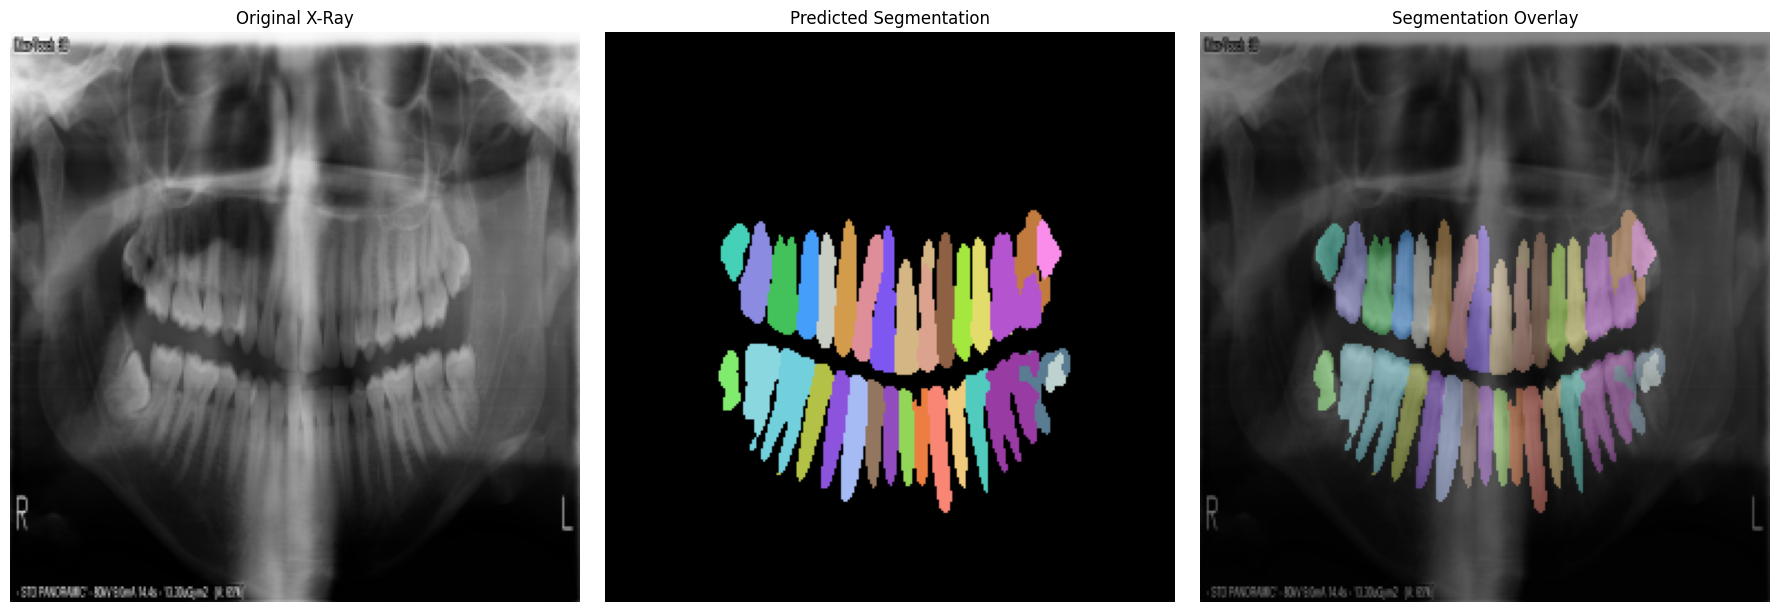

Dental OPG Inference
Image: D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\img\67.jpg
Detected tooth classes: 32
Class 01 -> 216 pixels
Class 02 -> 453 pixels
Class 03 -> 489 pixels
Class 04 -> 388 pixels
Class 05 -> 350 pixels
Class 06 -> 472 pixels
Class 07 -> 434 pixels
Class 08 -> 507 pixels
Class 09 -> 504 pixels
Class 10 -> 326 pixels
Class 11 -> 424 pixels
Class 12 -> 354 pixels
Class 13 -> 367 pixels
Class 14 -> 719 pixels
Class 15 -> 321 pixels
Class 16 -> 188 pixels
Class 17 -> 103 pixels
Class 18 -> 254 pixels
Class 19 -> 797 pixels
Class 20 -> 356 pixels
Class 21 -> 276 pixels
Class 22 -> 401 pixels
Class 23 -> 244 pixels
Class 24 -> 260 pixels
Class 25 -> 271 pixels
Class 26 -> 307 pixels
Class 27 -> 470 pixels
Class 28 -> 380 pixels
Class 29 -> 400 pixels
Class 30 -> 674 pixels
Class 31 -> 476 pixels
Class 32 -> 188 pixels


In [13]:
results = inference_dental_opg(
    image_path=r"D:\resume\11 - pytorch Teeth Segmentation on dental X-ray images\Teeth Segmentation JSON\d2\img\67.jpg"
)

prediction_mask, colored_mask, overlay, detected_classes = results

In [ ]:
prediction_mask, colored_mask, overlay, detected_classes = results